# Can I Predict Tomorrow's Anxiety from My Daily Habits?

Using my daily journal, I explore whether my recent anxiety and daily habits help predict how anxious I will feel tomorrow. I compare simple forecasts with ridge regression using dates in chronological order. 

## 1. Why I'm doing this

Since January 2023 I've written in a journal every day as part of therapy. I wrote it in Arabic, and every entry has the same five things: how much I slept, how well I slept, whether I exercised, whether I saw people in person, and how anxious I felt by the evening.

I started it because of something my therapist told me early on: once my lifestyle habits get better, my anxiety will be something I can control. I've held on to that idea for more than three years. Now I have 1,380 days of entries, and I want to see what my own data actually says about it.

### My question

> **Using only what I know by tonight, can I predict how anxious I'll feel tomorrow evening? And do my sleep, exercise and socializing tell me anything that my recent anxiety doesn't already tell me?**

The second part is the one I really care about. When I read back through the journal, my bad days usually come in groups, so just guessing tomorrow will be like today is probably already a decent forecast. If my habits matter for prediction, a model that knows about them should beat that guess. If it can't, that's still a real answer, and probably a useful one for me.

Along the way I also want to answer three smaller questions:

1. Which habit tells me the most: sleep, exercise or socializing?
2. Do bad nights add up? Are three bad nights in a row worse than each night on its own would suggest?
3. Could a model warn me the evening before a high-anxiety day (6/10 or more)?

The anxiety number is my own 0–10 rating at the end of the day. It isn't a clinical scale and nothing here is a diagnosis. Also, everything in this notebook is about prediction. If bad sleep predicts high anxiety, that doesn't prove bad sleep causes it. It could easily go the other way, because anxious days make it harder to sleep.


## 2. How the project works

The whole project in one picture. The grey boxes happened before this notebook (translating and merging the journal). The blue ones are what I do here.

In [1]:
import re
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_RAW = Path("data/raw/mariams_anxiety_raw.csv")
DATA_PROCESSED = Path("data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# One small palette for every figure: dark ink for text, a light grid,
# blue for the main series and orange for the second one.
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
BLUE, BLUE_LIGHT, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False, "axes.axisbelow": True,
})

print(f"pandas {pd.__version__} · numpy {np.__version__}")

pandas 3.0.6 · numpy 2.4.6


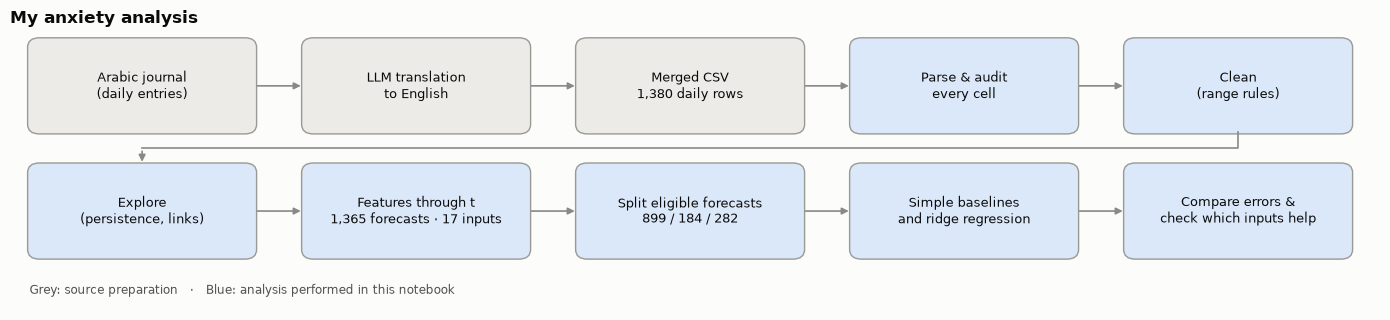

In [ ]:
def draw_pipeline():
    upstream = ["Arabic journal\n(daily entries)", "LLM translation\nto English", "Merged CSV\n1,380 daily rows"]
    in_notebook = ["Parse & audit\nevery cell", "Clean\n(range rules)", "Explore\n(persistence, links)",
                   "Features through t\n1,365 forecasts · 17 inputs", "Split eligible forecasts\n899 / 184 / 282", "Simple baselines\nand ridge regression",
                   "Compare errors &\ncheck which inputs help"]
    stages = [(s, "#ecebe7") for s in upstream] + [(s, "#dbe8f9") for s in in_notebook]

    fig, ax = plt.subplots(figsize=(14, 3.3))
    ax.set_xlim(0, 5 * 2.8)
    ax.set_ylim(0.55, 4.0)
    ax.axis("off")
    w, h = 2.3, 1.15
    for i, (label, fill) in enumerate(stages):
        row, col = divmod(i, 5)
        x, y = col * 2.8 + 0.2, 2.75 - row * 1.55
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    facecolor=fill, edgecolor="#9a9994", linewidth=1))
        ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=9, color=INK)
        if i < len(stages) - 1:
            if col < 4:
                ax.annotate("", xy=(x + 2.8, y + h / 2), xytext=(x + w, y + h / 2),
                            arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
            else:  # wrap to the start of the next row
                x_start, y_mid = 0.2 + w / 2, y - 0.2
                ax.plot([x + w / 2, x + w / 2, x_start], [y, y_mid, y_mid], color=MUTED, lw=1.2)
                ax.annotate("", xy=(x_start, y - 0.4), xytext=(x_start, y_mid),
                            arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
    ax.set_title("My anxiety analysis", pad=6)
    ax.text(0.2, 0.75, "Grey: source preparation   ·   Blue: analysis performed in this notebook",
            fontsize=8.5, color=INK_2)
    plt.tight_layout()
    plt.show()


draw_pipeline()

### Why I used classes

I use four small classes for loading, cleaning and feature construction

| Class | What it does |
|---|---|
| `DailyLogParser` | Turns one raw text cell (`"two"`, `"4/5"`, `" 2 "`) into a number and remembers which rule it used |
| `DailyLogLoader` | Reads the CSV as text, runs every cell through the parser, and checks there's exactly one row per day |
| `DataCleaner` | Applies the valid ranges from my codebook and logs every value it rejects |
| `FeatureBuilder` | Builds the same causal inputs for each lookback and horizon; keeps targets and dates separate |

I had two reasons for this. First, the same rules have to behave the same way on all five columns. Second, I wanted every change to the data to be logged. That way every count I report later comes from the code itself, not from me counting rows by hand.

## 3. My journal data

### Where it came from

I wrote the journal in Arabic, spread across several spreadsheet sheets. To work with it, I used Claude to translate the entries into English and merged the sheets into one CSV with one row per day, from 1 January 2023 to 11 October 2026. I checked roughly 120 days against the Arabic originals and found the translated values consistent. 

Translating can create its own mistakes. For example, a number might come out as a word (`"seven"`) or as a label (`"Fair"`) instead of a digit. So in Section 4 I treat anything like that as a data problem to find and fix.

### What each row means

Each row is one day, and every variable is something I rated myself on a fixed scale:

| Variable | Arabic | Scale | What the numbers mean |
|---|---|---|---|
| `sleep_adequacy` | كفاية النوم | 1–5 | 1 nowhere near enough · 2 insufficient · 3 somewhat enough · 4 mostly enough · 5 fully enough |
| `sleep_quality` | جودة النوم | 1–5 | 1 very poor · 2 poor · 3 fair · 4 good · 5 excellent |
| `exercise_frequency` | عدد مرات ممارسة الرياضة | 0–2 | Separate exercise sessions of at least 10 minutes |
| `socializing_frequency` | عدد مرات التواصل وجهًا لوجه | count ≥ 0 | Separate in-person encounters of at least 10 minutes (I count encounters, not people) |
| `anxiety_level` | مستوى القلق | 0–10 | My evening rating, from 0 (no anxiety) to 10 (extremely high) |

For example, the row `2, 4, 1, 3, 6` means: *I didn't get enough sleep, but the sleep itself was good. I exercised once, had three separate social encounters, and rated my evening anxiety 6/10.*

Two rules from my codebook are so important for cleaning. **A blank or `N/A` means I didn't record it, not zero.** And **a number outside its scale is a recording mistake.**

### When each value was recorded

My journal doesn't have exact timestamps it's just the day, so I have to make assumptions about timing.
| Variable on date *t* | What I assume it describes |
|---|---|
| `sleep_adequacy`, `sleep_quality` | The night **before** day *t* |
| `exercise_frequency`, `socializing_frequency` | What I did **during** day *t* |
| `anxiety_level` | How I felt at the **end** of day *t* |

On the evening of day *t* I already know last night's sleep, today's exercise and socializing, and today's anxiety. What I don't know yet is how I'll sleep tonight, because that only appears in tomorrow's row. So a forecast of tomorrow's anxiety made tonight can only use today's row and the ones before it. Using tomorrow's sleep would be cheating, even though it's sitting right there in the dataset.

## 4. Checking what goes wrong when I load the data

Before writing any cleaning code, I wanted to see what the usual pandas approach does to my file. The clear move is to let `pd.to_datetime` figure out the dates and let `pd.to_numeric(errors="coerce")` turn everything into numbers. The strict date conversion raises an error. Permissive mixed-format parsing and numeric coercion run, but quietly make mistakes.

In [3]:
naive = pd.read_csv(DATA_RAW)
VALUE_COLUMNS = ["sleep_adequacy", "sleep_quality", "exercise_frequency",
                 "socializing_frequency", "anxiety_level"]

# 1) Dates: the strict default refuses the file ...
try:
    pd.to_datetime(naive["date"])
except ValueError as err:
    print("pd.to_datetime (default):", str(err).splitlines()[0])

# ... and the permissive "mixed" mode quietly guesses month-first.
naive_dates = pd.to_datetime(naive["date"], format="mixed")
steps = naive_dates.diff().dt.days
print("\npd.to_datetime(format='mixed'):")
print(f"  '12/11/2023' was read as {naive_dates[naive['date'] == '12/11/2023'].iloc[0].date()}")
print(f"  duplicated dates: {naive_dates.duplicated().sum()}")
print(f"  gaps between consecutive rows that are not 1 day: {sorted(steps[(steps != 1) & steps.notna()].astype(int).tolist())}")

# 2) Values: count recorded entries that coercion throws away.
lost = {}
for col in VALUE_COLUMNS:
    present = naive[col].notna()
    numeric = pd.to_numeric(naive[col], errors="coerce").notna()
    lost[col] = naive.loc[present & ~numeric, col].tolist()
print("\npd.to_numeric(errors='coerce') turns these recorded values into NaN:")
for col, values in lost.items():
    print(f"  {col:<22} {len(values)} lost  {values}")

pd.to_datetime (default): time data "19/03/2023" doesn't match format "%Y-%m-%d". You might want to try:

pd.to_datetime(format='mixed'):
  '12/11/2023' was read as 2023-12-11
  duplicated dates: 1
  gaps between consecutive rows that are not 1 day: [-28, 30]

pd.to_numeric(errors='coerce') turns these recorded values into NaN:
  sleep_adequacy         3 lost  ['four', 'three', '3/5']
  sleep_quality          3 lost  ['4/5', 'Fair', '3/5']
  exercise_frequency     3 lost  ['zero', '0 session(s)', 'zero']
  socializing_frequency  3 lost  ['two', '0 encounter(s)', '1 encounter(s)']
  anxiety_level          3 lost  ['seven', '0/10', '3/10']


There are two problems here: strict date parsing stops with an error, while the permissive conversions can quietly lose or misread information. The strict date parser just refuses the file. That's actually fine, because at least it tells me something is wrong. The `mixed` mode is the dangerous one. It reads `12/11/2023` as **11 December** instead of 12 November, which creates a duplicate date and makes the calendar jump forward 30 days and then back 28. Later, when I build features like "yesterday's anxiety", the rows around that date would quietly be wrong, and nothing would warn me. The number conversion throws away **15 values I actually wrote down**, 3 in every column. These are the ones written as words, as fractions, or with units. After the conversion they look exactly like the days I left blank, which breaks my codebook's rule that blank means "not recorded".

To be fair, 15 cells out of 6,844 is only about 0.2%, so the overall count is small. The bigger issue is the ordering one misread date affects every feature that looks back in time. So instead of trusting the defaults, I'm going to parse every cell myself, keep track of which rule handled it, and check the calendar after parsing.

### Writing rules to read the messy entries

`DailyLogParser` has a named rule for each kind of messy value I found in the file. Every cell it parses keeps the name of the rule that handled it, so the audit table below comes straight from the parser.

**Dates.** Three formats show up. `2023-03-18` and `2023/07/27` can only mean one thing. For dates with the year at the end, I read them day-first. My evidence is the four dates where the first number is bigger than 12 (`19/03/2023`, `30/09/2024`, `25/02/2025`, `17/03/2025`). Those can only be day-first, so that's clearly how I wrote dates in this format. The only truly ambiguous one is `12/11/2023`, and the loader double-checks it: read as 12 November, it fits exactly between the 11th and the 13th.

**Values.** These are number words (`"seven"`), digits with extra spaces (`" 2 "`), unit text (`"0 encounter(s)"`), fractions of the scale (`"4/5"`, `"3/10"`) and one label (`"Fair"`, which my codebook defines as sleep quality 3). I'm strict about two of these. A unit only counts if it belongs to that column (sessions for exercise, encounters for socializing), and a fraction only counts if the bottom number is that column's maximum. Anything else gets marked `unparseable` instead of guessed.

In [4]:
class DailyLogParser:
    # Converts raw text cells into numbers and names the rule that was applied.

    NUMBER_WORDS = {w: i for i, w in enumerate(
        ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"])}
    CODEBOOK_LABELS = {
        "sleep_adequacy": {"nowhere near enough": 1, "insufficient": 2, "somewhat enough": 3,
                           "mostly enough": 4, "fully enough": 5},
        "sleep_quality": {"very poor": 1, "poor": 2, "fair": 3, "good": 4, "excellent": 5},
    }
    UNIT_WORDS = {"exercise_frequency": "session", "socializing_frequency": "encounter"}
    SCALE_MAX = {"sleep_adequacy": 5, "sleep_quality": 5, "anxiety_level": 10}

    @staticmethod
    def parse_date(text):
        # Returns (Timestamp, rule). Raises on any format not seen in the journal.
        t = text.strip()
        if re.fullmatch(r"\d{4}-\d{2}-\d{2}", t):
            return pd.Timestamp(datetime.strptime(t, "%Y-%m-%d")), "iso"
        if re.fullmatch(r"\d{4}/\d{2}/\d{2}", t):
            return pd.Timestamp(datetime.strptime(t, "%Y/%m/%d")), "year_first_slash"
        m = re.fullmatch(r"(\d{2})/(\d{2})/(\d{4})", t)
        if m:
            rule = "day_first_slash" if int(m[1]) > 12 else "ambiguous_read_day_first"
            return pd.Timestamp(datetime.strptime(t, "%d/%m/%Y")), rule
        raise ValueError(f"Unrecognised date format: {text!r}")

    @classmethod
    def parse_value(cls, text, column):
        # Returns (float or NaN, rule).
        t = text.strip()
        low = t.lower()
        if low == "":
            return np.nan, "blank"
        if low in {"n/a", "na"}:
            return np.nan, "na_marker"
        if re.fullmatch(r"-?\d+", t):
            return float(t), ("padded_integer" if t != text else "integer")
        if low in cls.NUMBER_WORDS:
            return float(cls.NUMBER_WORDS[low]), "number_word"
        if low in cls.CODEBOOK_LABELS.get(column, {}):
            return float(cls.CODEBOOK_LABELS[column][low]), "codebook_label"
        m = re.fullmatch(r"(\d+)\s*([a-z]+)\(s\)", low)
        if m and cls.UNIT_WORDS.get(column) == m[2]:
            return float(m[1]), "unit_suffix"
        m = re.fullmatch(r"(\d+)/(\d+)", t)
        if m and cls.SCALE_MAX.get(column) == int(m[2]):
            return float(m[1]), "fraction_of_scale"
        return np.nan, "unparseable"

Before I run this on 6,900 measurement cells, plus the dates, I test it on one example of each pattern. I also include a few inputs it should *refuse*, like a socializing unit in the exercise column. A parser that accepts everything isn't really checking anything.

In [5]:
P = DailyLogParser
checks = [
    (P.parse_value("4", "sleep_quality"), (4.0, "integer")),
    (P.parse_value(" 2 ", "sleep_adequacy"), (2.0, "padded_integer")),
    (P.parse_value("seven", "anxiety_level"), (7.0, "number_word")),
    (P.parse_value("Fair", "sleep_quality"), (3.0, "codebook_label")),
    (P.parse_value("0 encounter(s)", "socializing_frequency"), (0.0, "unit_suffix")),
    (P.parse_value("0 session(s)", "exercise_frequency"), (0.0, "unit_suffix")),
    (P.parse_value("4/5", "sleep_quality"), (4.0, "fraction_of_scale")),
    (P.parse_value("3/10", "anxiety_level"), (3.0, "fraction_of_scale")),
    (P.parse_value("-1", "exercise_frequency"), (-1.0, "integer")),  # parsed; rejected later by range
    (P.parse_value("1 encounter(s)", "exercise_frequency")[1], "unparseable"),  # wrong unit
    (P.parse_value("4/5", "anxiety_level")[1], "unparseable"),                  # wrong scale
    (P.parse_value("N/A", "sleep_adequacy")[1], "na_marker"),
    (P.parse_value("", "sleep_adequacy")[1], "blank"),
    (P.parse_date("19/03/2023"), (pd.Timestamp("2023-03-19"), "day_first_slash")),
    (P.parse_date("12/11/2023"), (pd.Timestamp("2023-11-12"), "ambiguous_read_day_first")),
    (P.parse_date("2023/07/27"), (pd.Timestamp("2023-07-27"), "year_first_slash")),
]
for got, expected in checks:
    assert got == expected, (got, expected)
print(f"All {len(checks)} parser checks passed.")

All 16 parser checks passed.


### Loading the data with my parser

`DailyLogLoader` reads the file with `dtype=str` and `keep_default_na=False`, so pandas doesn't convert anything by itself. Even `"N/A"` comes in as text, which means I can count it. After parsing, the loader checks that the dates are unique, in order, and cover every single day. If any date was misread, this check fails.

In [6]:
class DailyLogLoader:
    # Reads the journal CSV as text, parses it, and verifies the daily calendar.

    def __init__(self, path, value_columns, parser=DailyLogParser):
        self.path = Path(path)
        self.value_columns = value_columns
        self.parser = parser
        self.raw = None
        self.audit = None

    def load(self):
        self.raw = pd.read_csv(self.path, dtype=str, keep_default_na=False)
        records, audit = [], []
        for _, row in self.raw.iterrows():
            date, date_rule = self.parser.parse_date(row["date"])
            record = {"date": date}
            audit.append({"date": date, "column": "date", "raw": row["date"],
                          "parsed": date.date().isoformat(), "rule": date_rule})
            for col in self.value_columns:
                value, rule = self.parser.parse_value(row[col], col)
                record[col] = value
                audit.append({"date": date, "column": col, "raw": row[col], "parsed": value, "rule": rule})
            records.append(record)
        self.audit = pd.DataFrame(audit)
        df = pd.DataFrame(records).set_index("date")
        self._verify_calendar(df)
        return df

    @staticmethod
    def _verify_calendar(df):
        expected = pd.date_range(df.index.min(), df.index.max(), freq="D")
        assert df.index.is_unique, "duplicate dates after parsing"
        assert df.index.is_monotonic_increasing, "dates out of order after parsing"
        assert len(df) == len(expected) and (df.index == expected).all(), "calendar has gaps"
        print(f"Calendar verified: {len(df)} consecutive days, "
              f"{df.index.min().date()} to {df.index.max().date()}, no duplicates or gaps.")


loader = DailyLogLoader(DATA_RAW, VALUE_COLUMNS)
parsed = loader.load()
parsed.head()

Calendar verified: 1380 consecutive days, 2023-01-01 to 2026-10-11, no duplicates or gaps.


,sleep_adequacy,sleep_quality,exercise_frequency,socializing_frequency,anxiety_level
date,,,,,
2023-01-01,4.0,3.0,1.0,2.0,3.0
2023-01-02,3.0,3.0,1.0,3.0,4.0
2023-01-03,4.0,4.0,0.0,2.0,4.0
2023-01-04,2.0,3.0,2.0,1.0,3.0
2023-01-05,2.0,3.0,0.0,2.0,5.0


### Checking how the entries were read

Each row of this table is a column from my journal, and each number is how many cells a rule handled. The non-integer rules show what was recovered or normalized. Padded integers already survive numeric coercion; not every normalization recovers a lost value.

In [7]:
audit = loader.audit
rule_order = ["iso", "year_first_slash", "day_first_slash", "ambiguous_read_day_first",
              "integer", "padded_integer", "number_word", "codebook_label", "unit_suffix",
              "fraction_of_scale", "blank", "na_marker", "unparseable"]
rule_table = (pd.crosstab(audit["column"], audit["rule"])
                .reindex(index=["date"] + VALUE_COLUMNS)
                .reindex(columns=[r for r in rule_order if r in audit["rule"].unique()])
                .fillna(0).astype(int))
display(rule_table)

assert (audit["rule"] == "unparseable").sum() == 0, "some cells matched no rule"
recovered = audit[audit["rule"].isin(["padded_integer", "number_word", "codebook_label",
                                      "unit_suffix", "fraction_of_scale",
                                      "year_first_slash", "day_first_slash", "ambiguous_read_day_first"])]
print(f"Cells needing a non-default rule: {len(recovered)} · unparseable cells: 0")
print("\nEvery recovered cell, for inspection:")
display(recovered.assign(date=recovered["date"].dt.date)
                 .sort_values(["column", "date"])
                 .reset_index(drop=True))

rule,iso,year_first_slash,day_first_slash,ambiguous_read_day_first,integer,padded_integer,number_word,codebook_label,unit_suffix,fraction_of_scale,blank,na_marker
column,,,,,,,,,,,,
date,1370,5,4,1,0,0,0,0,0,0,0,0
sleep_adequacy,0,0,0,0,1363,2,2,0,0,1,10,2
sleep_quality,0,0,0,0,1363,2,0,1,0,2,12,0
exercise_frequency,0,0,0,0,1363,1,2,0,1,0,11,2
socializing_frequency,0,0,0,0,1363,2,1,0,2,0,12,0
anxiety_level,0,0,0,0,1369,1,1,0,0,2,7,0


Cells needing a non-default rule: 33 · unparseable cells: 0

Every recovered cell, for inspection:


,date,column,raw,parsed,rule
0,2023-08-02,anxiety_level,seven,7.0,number_word
1,2025-03-31,anxiety_level,5,5.0,padded_integer
2,2026-01-25,anxiety_level,0/10,0.0,fraction_of_scale
3,2026-08-10,anxiety_level,3/10,3.0,fraction_of_scale
4,2023-03-19,date,19/03/2023,2023-03-19,day_first_slash
5,2023-07-27,date,2023/07/27,2023-07-27,year_first_slash
6,2023-11-12,date,12/11/2023,2023-11-12,ambiguous_read_day_first
7,2024-09-30,date,30/09/2024,2024-09-30,day_first_slash
8,2024-11-20,date,2024/11/20,2024-11-20,year_first_slash
9,2025-01-13,date,2025/01/13,2025-01-13,year_first_slash


All **6,900 measurement cells and 1,380 date cells** matched a rule, including the explicit missing-value rules, so nothing was left unparseable. Ten dates needed something other than the standard format, and **23 recorded values needed normalization or recovery**: 8 had extra spaces, 6 were number words, 5 were fractions, 3 had units, and 1 was the label "Fair".

I printed every fixed cell above so I could check each one by eye against the raw text. For example, `3/10` became 3 for anxiety and `0 session(s)` became 0 for exercise. The calendar check also passed, with 1,380 days in a row and no duplicates or gaps. That's an additional consistency check that `12/11/2023` means 12 November, because reading it the other way would have created a duplicate date and the check would have failed.

One limitation is that these rules only cover patterns that actually appear in this file. If a new one showed up, like "5 out of 10", it would be marked `unparseable` and the `assert` would stop the notebook. I did that on purpose. I'd rather the notebook crash than quietly accept something it doesn't understand.

Parsing tells me what a cell *says*. It doesn't tell me whether that value is even possible, so that's the next check.

### Checking for values outside the scales

Parsing turns text into numbers, but it can't tell me whether a number makes sense. My codebook defines each scale and says anything outside it is a recording mistake, so `DataCleaner` marks those values as missing.

I decided **not** to clip them to the nearest valid value. If I turned an anxiety of 11 into a 10, I'd be making up a rating I never gave, and I'd also be giving the most extreme value extra weight. Marking it as missing is more honest. Later, missing predictors may be filled inside each training fold. Missing target ratings will be excluded after forecast alignment, never imputed.

| Column | Valid values | Where the rule comes from |
|---|---|---|
| `sleep_adequacy`, `sleep_quality` | whole numbers 1–5 | the codebook scale |
| `exercise_frequency` | whole numbers 0–2 | the codebook lists 0, 1 or 2 sessions |
| `socializing_frequency` | whole numbers ≥ 0 | it's a count, and the codebook gives no maximum |
| `anxiety_level` | whole numbers 0–10 | the codebook scale |

In [8]:
class DataCleaner:
    # Applies the codebook's valid ranges; logs and blanks every violation.

    VALID_RANGES = {
        "sleep_adequacy": (1, 5),
        "sleep_quality": (1, 5),
        "exercise_frequency": (0, 2),
        "socializing_frequency": (0, None),
        "anxiety_level": (0, 10),
    }

    def __init__(self, valid_ranges=None):
        self.valid_ranges = valid_ranges or self.VALID_RANGES
        self.rejected = None

    def clean(self, df):
        out = df.copy()
        rejected = []
        for col, (low, high) in self.valid_ranges.items():
            values = out[col]
            bad = values.notna() & ((values < low) | (values % 1 != 0))
            if high is not None:
                bad |= values.notna() & (values > high)
            for date, value in values[bad].items():
                rejected.append({"date": date.date(), "column": col, "value": value,
                                 "valid range": f"{low}–{high if high is not None else '∞'}"})
            out.loc[bad, col] = np.nan
        self.rejected = pd.DataFrame(rejected)
        return out


cleaner = DataCleaner()
clean = cleaner.clean(parsed)
display(cleaner.rejected)

,date,column,value,valid range
0,2024-06-02,sleep_adequacy,6.0,1–5
1,2023-01-15,sleep_quality,0.0,1–5
2,2025-11-28,exercise_frequency,-1.0,0–2
3,2023-06-11,anxiety_level,11.0,0–10


Four values parsed fine but are outside their scale, so they're now marked as missing:

- **Sleep adequacy of 6** on 2024-06-02, when the scale only goes from 1 to 5.
- **Sleep quality of 0** on 2023-01-15, when the scale starts at 1.
- **Exercise of −1** on 2025-11-28. You can't do a negative number of workouts.
- **Anxiety of 11** on 2023-06-11, when the scale goes from 0 to 10. It is outside the codebook. The other measurements cannot tell me what the intended anxiety rating was.

A range check can only catch values that are impossible. If I wrote a 3 when I meant a 7, nothing in the data can catch that.

I'm keeping all four as missing values and not dropping any rows. Missing predictors may be filled later inside each training fold. Missing target ratings will be excluded after alignment, not filled.

### How much data is left after cleaning?

I count how many recorded values remain after each cleaning step. I never drop a whole day, because a day with one bad value still has four good ones.

In [9]:
def usable_counts(frame):
    return frame[VALUE_COLUMNS].notna().sum()

stages = pd.DataFrame({
    "recorded (non-blank, non-N/A)": (loader.audit.query("column != 'date'")
                                       .groupby("column")["rule"]
                                       .apply(lambda r: (~r.isin(["blank", "na_marker"])).sum())
                                       .reindex(VALUE_COLUMNS)),
    "naive to_numeric": pd.Series({c: pd.to_numeric(naive[c], errors="coerce").notna().sum()
                                   for c in VALUE_COLUMNS}),
    "after DailyLogParser": usable_counts(parsed),
    "after DataCleaner": usable_counts(clean),
})
stages.loc["total"] = stages.sum()
display(stages)

fully_blank = clean[VALUE_COLUMNS].isna().all(axis=1)
complete = clean[VALUE_COLUMNS].notna().all(axis=1)
print(f"Days in calendar:          {len(clean)}")
print(f"Days with all five values: {complete.sum()}  ({complete.mean():.1%})")
print(f"Days with no values:       {fully_blank.sum()}  -> {', '.join(str(d.date()) for d in clean.index[fully_blank])}")
print(f"Days missing anxiety:      {clean['anxiety_level'].isna().sum()}")

clean.to_csv(DATA_PROCESSED / "anxiety_clean.csv")
print(f"\nSaved cleaned data to {DATA_PROCESSED / 'anxiety_clean.csv'}")

,"recorded (non-blank, non-N/A)",naive to_numeric,after DailyLogParser,after DataCleaner
sleep_adequacy,1368,1365,1368,1367
sleep_quality,1368,1365,1368,1367
exercise_frequency,1367,1364,1367,1366
socializing_frequency,1368,1365,1368,1368
anxiety_level,1373,1370,1373,1372
total,6844,6829,6844,6840


Days in calendar:          1380
Days with all five values: 1348  (97.7%)
Days with no values:       7  -> 2023-06-30, 2023-07-01, 2023-07-02, 2024-03-14, 2024-03-15, 2026-04-03, 2026-04-04
Days missing anxiety:      8

Saved cleaned data to data/processed/anxiety_clean.csv


I recorded **6,844** values. The default conversion would have kept 6,829 of them, my parser keeps all 6,844, and the range check removes the 4 impossible ones, which leaves **6,840**.

Looking at whole days, **1,348 out of 1,380 (97.7%) have all five values**. Seven days are completely empty, in three short gaps of two or three days each. Anxiety, the thing I'm predicting, is missing on 8 days: those 7 plus the day with the 11.

The empty days bother me a little because they come in short streaks, which are exactly the days where "yesterday's value" has nothing to point to. I can't tell whether those were unusually good days or unusually bad ones, so I'm not going to pretend I know.

At the modeling stage, forecasts with a missing target rating will be excluded after alignment. Missing current anxiety or habits can remain as predictors and be handled using training-only information; they do not automatically make tomorrow's target unusable. The cleaned data is saved to `data/processed/anxiety_clean.csv`.

## 5. Taking a first look at the data

For each figure I'll say which question it answers, what it shows, and what I'm changing in my plan because of it.

### 5.1 How does my anxiety change over time?

If my anxiety jumped around randomly from day to day, that day's habits would be the obvious thing to look at. If it moves in streaks instead, my recent anxiety is probably the strongest predictor, and that's what any habit-based model has to beat.

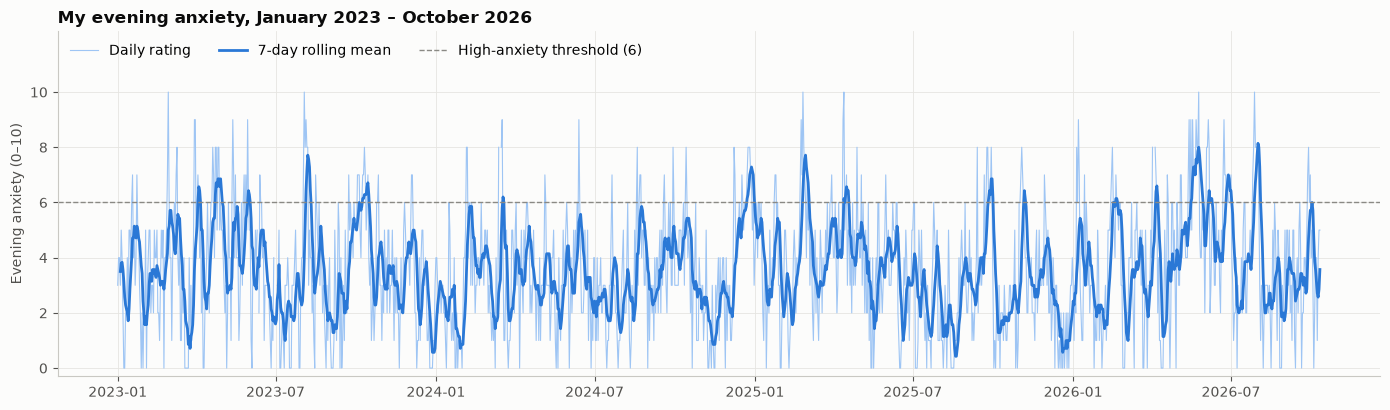

Days rated >= 6: 252 of 1372 (18.4%)
Episodes (>= 2 consecutive high days): 60 · median length 2 days · longest 10 days


,days rated,mean anxiety,share of rated days >= 6
year,,,
2023,361,3.64,0.188
2024,364,3.34,0.143
2025,365,3.37,0.164
2026,282,3.99,0.255


In [10]:
anx = clean["anxiety_level"]
rolling = anx.rolling(7, min_periods=4).mean()
HIGH = 6

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(anx.index, anx, color=BLUE_LIGHT, linewidth=0.8, label="Daily rating")
ax.plot(rolling.index, rolling, color=BLUE, linewidth=2, label="7-day rolling mean")
ax.axhline(HIGH, color=MUTED, linewidth=1, linestyle="--", label=f"High-anxiety threshold ({HIGH})")
ax.set_ylim(-0.3, 12.2)
ax.set_yticks(range(0, 11, 2))
ax.set_ylabel("Evening anxiety (0–10)")
ax.set_title("My evening anxiety, January 2023 – October 2026")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

# High-anxiety episodes: runs of at least 2 consecutive days rated >= HIGH.
high = (anx >= HIGH).astype(float).where(anx.notna())
run_id = (high != high.shift()).cumsum()
runs = high.groupby(run_id).agg(["first", "size"])
episodes = runs[(runs["first"] == 1) & (runs["size"] >= 2)]["size"]
print(f"Days rated >= {HIGH}: {int(high.sum())} of {int(high.notna().sum())} ({high.mean():.1%})")
print(f"Episodes (>= 2 consecutive high days): {len(episodes)} · "
      f"median length {episodes.median():.0f} days · longest {episodes.max()} days")

by_year = pd.DataFrame({
    "days rated": anx.groupby(anx.index.year).count(),
    "mean anxiety": anx.groupby(anx.index.year).mean().round(2),
    f"share of rated days >= {HIGH}": high.groupby(anx.index.year).mean().round(3),
})
by_year.index.name = "year"
display(by_year)

The first thing I notice is that my anxiety comes in waves, not random spikes. The rolling mean makes the rises and quieter stretches easier to see than the daily line alone. A sustained rise in the mean is different from an uninterrupted run of daily ratings above 6; I count those runs separately below. Honestly, I could match many of these changes to things happening in my life at the time.

**252 of 1,372 rated days (18.4%) were 6 or higher**, and they tend to come together. I count **60 "episodes"** of at least two high days in a row. Most of them last two days, and the longest lasted **10 days**.

The yearly table is going to matter later. 2024 and 2025 were calmer (averages of 3.34 and 3.37), but **2026 has been the hardest year so far**, with an average of 3.99 and a quarter of days at 6 or above. In the earlier years that was 14–19%.

(6 is a cutoff I picked myself. A different cutoff would change the number of episodes, but it wouldn't change the fact that high days cluster together.)

This changes two things in my plan:

1. Because I want a future forecast, the main split has to go in time order. Random splitting allows training on dates later than a validation forecast. I will measure any score difference, rather than assume shuffling must improve it.
2. My test period will be 2026, which has been harder than the years the model learns from. If the test error ends up worse than the validation error, that might reflect a real change in my life rather than a broken model.


I have already explored 2026 here, so I cannot call it an untouched holdout. I will freeze model choices using the earlier development periods before final evaluation. Missing ratings are excluded from the yearly high-day proportions, and they break high-anxiety episode runs.

### 5.2 Does yesterday's anxiety help predict today's?

To measure this I use **autocorrelation**. At lag *k*, it's the correlation between my anxiety on a given day and my anxiety *k* days earlier:

$$\rho_k = \operatorname{corr}(a_t,\ a_{t-k})$$

If $\rho_1$ is large, yesterday's rating already predicts today's pretty well, and every model will have to beat that. I report descriptive correlations without a significance band; inference would need to account for temporal dependence.

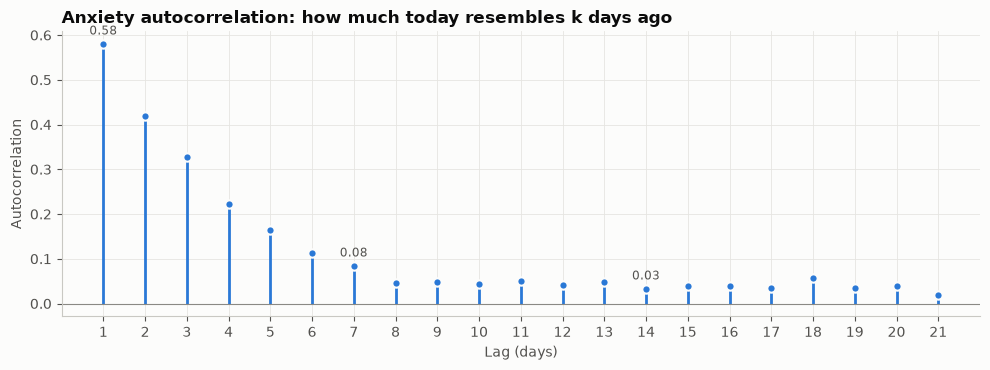

Autocorrelation at selected lags: {1: np.float64(0.579), 2: np.float64(0.419), 3: np.float64(0.327), 7: np.float64(0.083), 14: np.float64(0.032), 21: np.float64(0.018)}
Observed pairs: {1: 1367, 3: 1361, 7: 1357, 14: 1350}


In [11]:
lags = range(1, 22)
acf = pd.Series({k: anx.autocorr(lag=k) for k in lags})

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.vlines(acf.index, 0, acf.values, color=BLUE, linewidth=2)
ax.scatter(acf.index, acf.values, color=BLUE, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axhline(0, color=MUTED, linewidth=0.8)
for k in (1, 7, 14):
    ax.annotate(f"{acf[k]:.2f}", (k, acf[k]), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=8.5, color=INK_2)
ax.set_xticks(list(lags))
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Anxiety autocorrelation: how much today resembles k days ago")
plt.tight_layout()
plt.show()

print("Autocorrelation at selected lags:", {k: round(acf[k], 3) for k in (1, 2, 3, 7, 14, 21)})
print("Observed pairs:", {k: int((anx.notna() & anx.shift(k).notna()).sum()) for k in (1, 3, 7, 14)})

Yesterday's anxiety has a correlation of **0.58** with today's. It drops to **0.42 after two days**, **0.33 after three**, and **0.08 after seven**.

What interests me is that the association is still visible beyond yesterday. That makes recent averages worth testing alongside today's rating. It does not prove a particular memory mechanism or tell me which window predicts best. Slow changes between years can also affect correlations calculated over the whole series.

After about a week the correlations are much smaller, roughly 0.02–0.06 at the displayed later lags. I have left off an independent-day significance band because the series is temporally dependent.

My first reference will be **persistence**, predicting that tomorrow equals today. In Section 11 I'll compare lookbacks of 1, 3, 7 and 14 days using development results, rather than deciding from this plot alone.

### 5.3 How often did I record each rating?

How spread out a variable is limits what a model can learn from it. If something has the same value almost every day, it can't predict much, even if it matters a lot in real life.

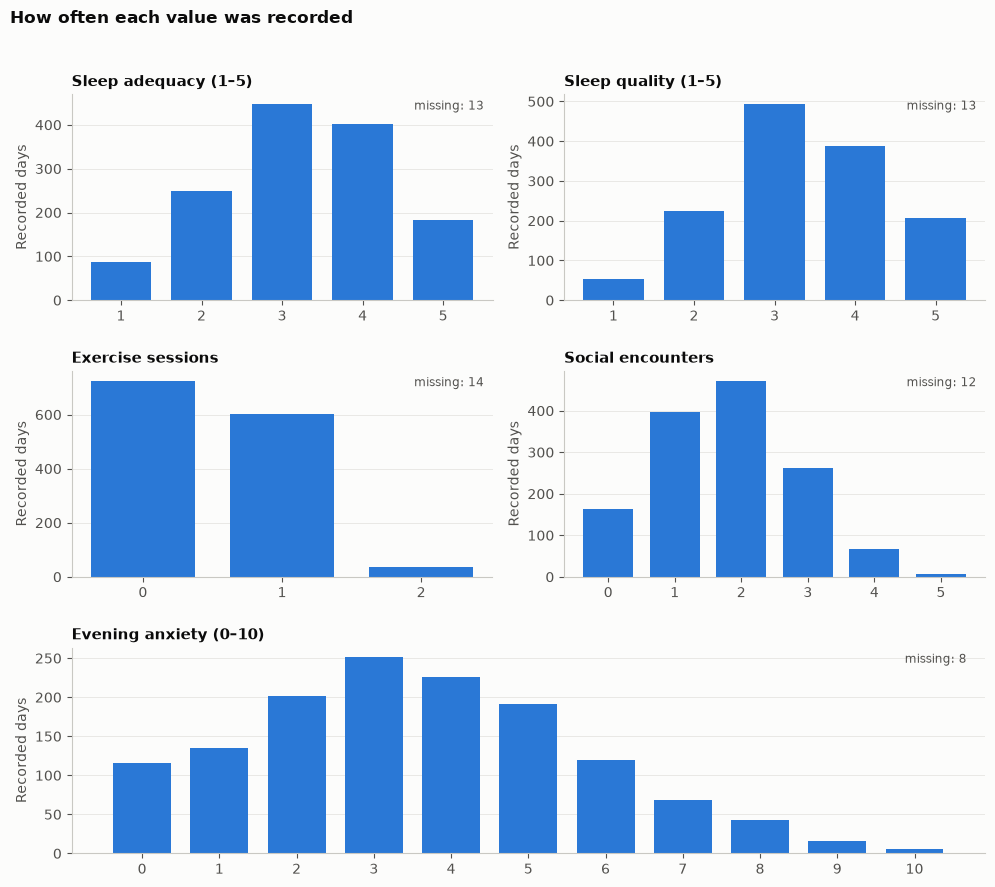

,count,mean,std,min,50%,max
sleep_adequacy,1367.0,3.25,1.10,1.0,3.0,5.0
sleep_quality,1367.0,3.35,1.04,1.0,3.0,5.0
exercise_frequency,1366.0,0.50,0.55,0.0,0.0,2.0
socializing_frequency,1368.0,1.77,1.07,0.0,2.0,5.0
anxiety_level,1372.0,3.56,2.17,0.0,3.0,10.0


In [12]:
labels = {"sleep_adequacy": "Sleep adequacy (1–5)", "sleep_quality": "Sleep quality (1–5)",
          "exercise_frequency": "Exercise sessions", "socializing_frequency": "Social encounters",
          "anxiety_level": "Evening anxiety (0–10)"}
fig = plt.figure(figsize=(10, 9))
distribution_grid = fig.add_gridspec(3, 2)
axes = [fig.add_subplot(distribution_grid[0, 0]), fig.add_subplot(distribution_grid[0, 1]),
        fig.add_subplot(distribution_grid[1, 0]), fig.add_subplot(distribution_grid[1, 1]),
        fig.add_subplot(distribution_grid[2, :])]
for ax, col in zip(axes, VALUE_COLUMNS):
    counts = clean[col].value_counts().sort_index()
    ax.bar(counts.index.astype(int), counts.values, color=BLUE, width=0.75)
    ax.set_title(labels[col], fontsize=10.5)
    ax.set_xticks(counts.index.astype(int))
    ax.grid(axis="x", visible=False)
    ax.text(0.98, 0.97, f"missing: {clean[col].isna().sum()}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8.5, color=INK_2)
for ax in axes:
    ax.set_ylabel("Recorded days")
fig.suptitle("How often each value was recorded", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2)
plt.show()

display(clean[VALUE_COLUMNS].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

- **Sleep adequacy and sleep quality** use the whole 1–5 scale and are centered around 3 (averages of 3.25 and 3.35), so a model has variation to work with; whether it improves forecasts still needs testing.
- **Exercise** is basically yes or no. Almost every day is 0 or 1 session, and I only did 2 sessions on 37 of 1,366 days (average 0.50).
- **Social encounters** go from 0 to 5 but are usually 1 or 2 (average 1.77). Days with 4 or 5 are rare.
- **Anxiety** is skewed to the right. Most days are between 2 and 5 (average 3.56, median 3), with a thin tail up to 10.

Two things follow from this. First, both zero and one exercise session are well represented, but the two-session category is small. That limits conclusions about higher frequency; it does not make exercise generally uninformative. Second, my worst days (7 to 10) are rare, so the model won't have many examples of them. A model that minimizes squared error tends to pull its predictions toward the middle, so I will check whether it underestimates my worst days. Because of that, I'll report the error on high-anxiety days separately, instead of only giving one overall number.

<a id="section-54"></a>

### 5.4 Are my habits related to anxiety today or tomorrow?

A strong same-evening relationship is not enough to answer my forecasting question. I first compare average anxiety at each habit level, then check whether a next-evening association remains when comparing days with the same current anxiety rating.

**Step 1 · Compare the two evenings.** Each panel below shows one habit recorded on day $t$:

- **Blue circles:** average anxiety that evening, $a_t$.
- **Orange squares:** average anxiety the next evening, $a_{t+1}$.

All panels use the same anxiety scale. Under each habit level, I report the number of ratings behind the blue and orange averages separately. Missing values are excluded from each average, so their sample counts can differ. Lines connect observed levels to make the pattern easier to follow; they are not fitted models or uncertainty intervals.

Sleep on day $t$ describes the preceding night. Exercise and socializing refer to day $t$, without timestamps that establish their order relative to anxiety. Socializing levels 4 and 5 are combined as **4+ for this display only**.

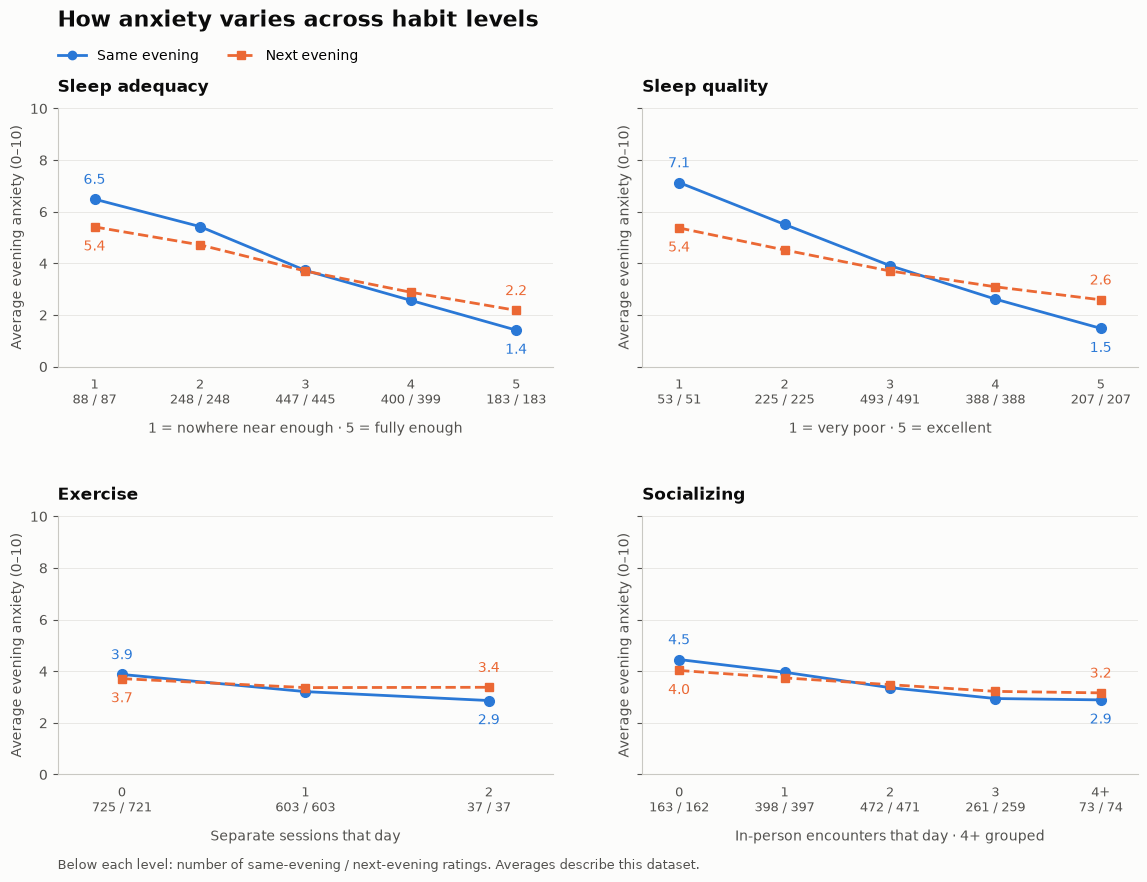

same-evening n  next-evening n  same-evening mean  \
habit          level                                                      
Sleep adequacy 1                  88              87               6.49   
               2                 248             248               5.43   
               3                 447             445               3.73   
               4                 400             399               2.57   
               5                 183             183               1.42   
Sleep quality  1                  53              51               7.13   
               2                 225             225               5.51   
               3                 493             491               3.91   
               4                 388             388               2.62   
               5                 207             207               1.48   
Exercise       0                 725             721               3.88   
               1                 603             603               3.21   
               2                  37              37               2.86   
Socializing    0                 163             162               4.45   
               1                 398             397               3.96   
               2                 472             471               3.36   
               3                 261             259               2.94   
               4                  73              74               2.89   

                      next-evening mean  
habit          level                     
Sleep adequacy 1                   5.41  
               2                   4.72  
               3                   3.70  
               4                   2.88  
               5                   2.18  
Sleep quality  1                   5.37  
               2                   4.52  
               3                   3.71  
               4                   3.09  
               5                   2.59  
Exercise       0                   3.71  
               1                   3.37  
               2                   3.38  
Socializing    0                   4.03  
               1                   3.74  
               2                   3.48  
               3                   3.22  
               4                   3.16

In [13]:
HABITS = ["sleep_adequacy", "sleep_quality", "exercise_frequency", "socializing_frequency"]
habit_axes = {
    "sleep_adequacy": ("Sleep adequacy", "1 = nowhere near enough · 5 = fully enough"),
    "sleep_quality": ("Sleep quality", "1 = very poor · 5 = excellent"),
    "exercise_frequency": ("Exercise", "Separate sessions that day"),
    "socializing_frequency": ("Socializing", "In-person encounters that day · 4+ grouped"),
}
next_anx = anx.shift(-1)  # intact daily calendar: next row really is tomorrow

level_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for ax, col in zip(axes.flat, HABITS):
    level = clean[col].clip(upper=4) if col == "socializing_frequency" else clean[col]
    table = (pd.DataFrame({"level": level, "same": anx, "next": next_anx})
               .groupby("level")
               .agg(same_n=("same", "count"), next_n=("next", "count"),
                    same_mean=("same", "mean"), next_mean=("next", "mean")))
    table.index = table.index.astype(int)
    title, xlabel = habit_axes[col]
    level_tables[title] = table

    ax.plot(table.index, table["same_mean"], color=BLUE, marker="o", markersize=7)
    ax.plot(table.index, table["next_mean"], color=ORANGE, marker="s", markersize=6,
            linestyle="--")
    for x in (table.index[0], table.index[-1]):
        series = sorted(["same_mean", "next_mean"], key=lambda name: table.loc[x, name], reverse=True)
        for name, offset in zip(series, [11, -17]):
            ax.annotate(f"{table.loc[x, name]:.1f}", (x, table.loc[x, name]),
                        xytext=(0, offset), textcoords="offset points", ha="center", fontsize=10,
                        color=BLUE if name == "same_mean" else ORANGE)
    tick_labels = []
    for level, row in table.iterrows():
        label = "4+" if col == "socializing_frequency" and level == 4 else str(level)
        tick_labels.append(f"{label}\n{int(row['same_n'])} / {int(row['next_n'])}")
    ax.set_xticks(table.index, tick_labels, fontsize=9)
    ax.set_xlim(table.index.min() - 0.35, table.index.max() + 0.35)
    ax.set_ylim(0, 10)
    ax.set_yticks(range(0, 11, 2))
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel, labelpad=10, fontsize=10)
    ax.set_ylabel("Average evening anxiety (0–10)")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0, pad=8)

handles = [Line2D([], [], color=BLUE, marker="o", label="Same evening"),
           Line2D([], [], color=ORANGE, marker="s", linestyle="--", label="Next evening")]
fig.suptitle("How anxiety varies across habit levels", x=0.08, y=0.98, ha="left",
             fontsize=16, weight="bold", color=INK)
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.07, 0.95), ncol=2)
fig.text(0.08, 0.025, "Below each level: number of same-evening / next-evening ratings. Averages describe this dataset.",
         fontsize=9, color=INK_2)
fig.subplots_adjust(left=0.08, right=0.98, top=0.87, bottom=0.13, hspace=0.58, wspace=0.18)
plt.show()

level_summary = pd.concat(level_tables, names=["habit", "level"])
display(level_summary.rename(columns={"same_n": "same-evening n", "next_n": "next-evening n",
                                       "same_mean": "same-evening mean", "next_mean": "next-evening mean"})
                     .round(2))

The sleep panels show the largest differences. At sleep adequacy 1 versus 5, same-evening means are **6.5 versus 1.4**, while next-evening means are **5.4 versus 2.2**. The gap is smaller for the next evening: about **3.2 points rather than 5.1**. Sleep quality has a similar pattern: **7.1 versus 1.5** on the same evening and **5.4 versus 2.6** the next evening.

Exercise and socializing show gentler differences. With no exercise versus one session, next-evening means are **3.7 versus 3.4**; two sessions also averages about 3.4. With zero versus 4+ social encounters, next-evening means are **4.0 versus 3.2**. These are group descriptions, not effects of changing a habit.

The counts matter. Sleep quality 1 has **53 same-evening ratings but 51 next-evening ratings**. Two exercise sessions has only **37 ratings for each evening**. A group mean based on fewer observations can be sensitive to a small number of days. No uncertainty intervals are estimated here.

The orange sleep lines suggest a next-day association worth investigating, but today's anxiety is also related to both sleep and tomorrow's rating. Step 2 checks how the descriptive association looks within groups with the same current anxiety.

**Step 2 · Compare days with the same anxiety rating today.**

Sleep relates to today's rating, and today's rating relates to tomorrow's. To describe how the habit–tomorrow association changes when today's rating is held fixed, I group days by $a_t$ and calculate a **Spearman correlation** inside each group. Spearman correlates ranks, so it does not require equal spacing between habit ratings.

For each habit, I retain groups with at least 20 complete day-pairs and variation in both the habit and tomorrow's rating. The cutoff is a practical choice for this exploration, not a significance threshold. I then calculate:

$$r_{\mathrm{within}}=\frac{\sum_{g\in G}n_g\,r_{s,g}}{\sum_{g\in G}n_g},$$

where $g$ is today's anxiety rating, $n_g$ is the group's size and $r_{s,g}$ is its Spearman correlation. The left panel pools those **same retained observations**; the right panel averages their within-group correlations. Using the same days prevents group exclusions from changing the comparison's sample.

This weighted summary is descriptive. It is not a standard partial correlation, a test of conditional independence, or a measure of a causal effect. Opposite group correlations can also cancel in an average. I report the counts and excluded groups below, without significance bands.

In [14]:
def within_today_spearman(habit, min_days=20):
    pairs = pd.DataFrame({"habit": habit, "today": anx, "tomorrow": next_anx}).dropna()
    if pairs.empty:
        raise ValueError("No complete day-pairs")
    details = []
    for rating, group in pairs.groupby("today"):
        reason = ("too few pairs" if len(group) < min_days else
                  "constant habit" if group["habit"].nunique() < 2 else
                  "constant tomorrow" if group["tomorrow"].nunique() < 2 else "retained")
        rho = group["habit"].corr(group["tomorrow"], method="spearman") if reason == "retained" else np.nan
        details.append({"today": int(rating), "pairs": len(group), "rho": rho, "status": reason})
    groups = pd.DataFrame(details)
    kept = groups[groups["status"] == "retained"]
    if kept.empty:
        raise ValueError("No groups support a within-rating comparison")
    retained = pairs[pairs["today"].isin(kept["today"])]
    assert len(retained) == kept["pairs"].sum()
    summary = {
        "all eligible rho": pairs["habit"].corr(pairs["tomorrow"], method="spearman"),
        "pooled retained rho": retained["habit"].corr(retained["tomorrow"], method="spearman"),
        "within-group rho": np.average(kept["rho"], weights=kept["pairs"]),
        "eligible pairs": len(pairs), "retained pairs": len(retained),
        "rows without complete pair": len(habit) - len(pairs),
        "pairs in excluded groups": len(pairs) - len(retained),
        "coverage (%)": 100 * len(retained) / len(pairs),
    }
    return summary, groups


summaries, group_tables = {}, {}
for col in HABITS:
    name = habit_axes[col][0]
    summaries[name], group_tables[name] = within_today_spearman(clean[col])
check = pd.DataFrame.from_dict(summaries, orient="index")
check.index.name = "habit"
display(check[["all eligible rho", "pooled retained rho", "within-group rho"]].round(3))
count_columns = ["eligible pairs", "retained pairs", "rows without complete pair", "pairs in excluded groups"]
display(check[count_columns].astype(int).assign(coverage_pct=check["coverage (%)"].round(1)))
# Keep the full counts and exclusions available; display the group correlations compactly.
group_audit = pd.concat(group_tables, names=["habit", "group"]).droplevel("group")
group_correlations = group_audit.reset_index().pivot(index="today", columns="habit", values="rho")
display(group_correlations.reindex(columns=check.index).round(3))
print("NaN above means a group was excluded, not a zero correlation.")
display(group_audit[group_audit["status"] != "retained"].drop(columns="rho"))

,all eligible rho,pooled retained rho,within-group rho
habit,,,
Sleep adequacy,-0.418,-0.399,-0.070
Sleep quality,-0.307,-0.285,0.086
Exercise,-0.076,-0.069,0.017
Socializing,-0.117,-0.099,0.013


,eligible pairs,retained pairs,rows without complete pair,pairs in excluded groups,coverage_pct
habit,,,,,
Sleep adequacy,1361,1339,19,22,98.4
Sleep quality,1361,1339,19,22,98.4
Exercise,1360,1338,20,22,98.4
Socializing,1362,1340,18,22,98.4


habit,Sleep adequacy,Sleep quality,Exercise,Socializing
today,,,,
0,-0.065,-0.078,-0.105,-0.053
1,-0.153,0.147,0.118,-0.114
2,-0.079,0.048,0.034,0.076
3,-0.062,0.070,0.022,-0.042
4,-0.047,0.136,0.057,0.103
5,-0.121,0.172,0.031,0.091
6,0.021,0.045,-0.115,-0.132
7,0.029,0.065,-0.030,0.021
8,-0.139,0.111,0.071,0.190


NaN above means a group was excluded, not a zero correlation.


,today,pairs,status
habit,,,
Sleep adequacy,9,16,too few pairs
Sleep adequacy,10,6,too few pairs
Sleep quality,9,16,too few pairs
Sleep quality,10,6,too few pairs
Exercise,9,16,too few pairs
Exercise,10,6,too few pairs
Socializing,9,16,too few pairs
Socializing,10,6,too few pairs


Read both panels on the same scale. A negative bar means higher habit values tend to accompany lower anxiety the next evening; a positive bar means the reverse. The original, ungrouped socializing count is used here. Sample sizes differ slightly between habits because missing entries differ.

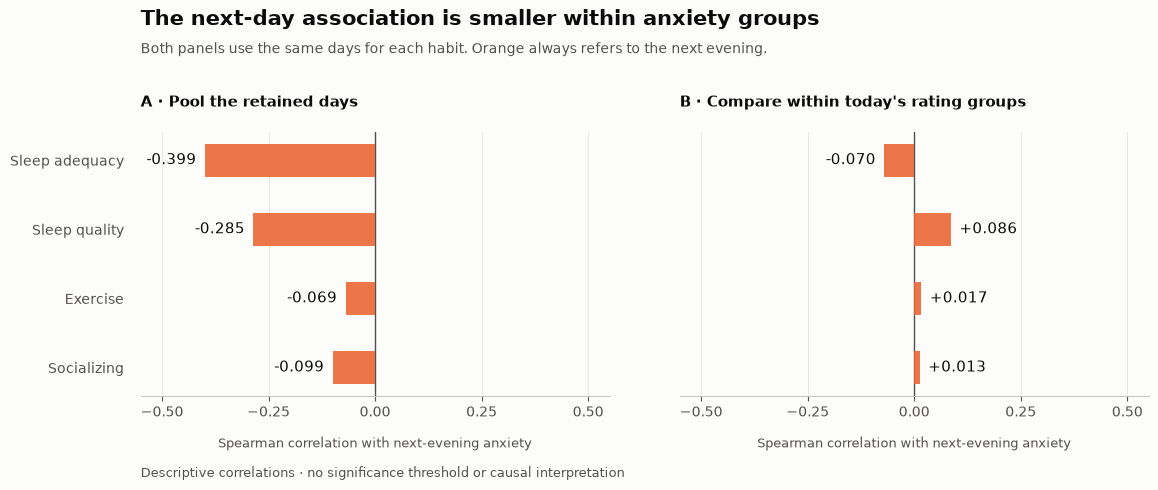

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9), sharex=True, sharey=True)
positions = np.arange(len(check))
for ax, column, title in zip(axes,
        ["pooled retained rho", "within-group rho"],
        ["A · Pool the retained days", "B · Compare within today's rating groups"]):
    values = check[column].to_numpy()
    ax.barh(positions, values, height=0.48, color=ORANGE, alpha=0.9, zorder=3)
    for y, value in zip(positions, values):
        ax.text(value + (0.02 if value >= 0 else -0.02), y, f"{value:+.3f}",
                ha="left" if value >= 0 else "right", va="center", color=INK, fontsize=11)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_xlim(-0.55, 0.55)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xlabel("Spearman correlation with next-evening anxiety", labelpad=12, fontsize=9)
    ax.set_title(title, fontsize=11, pad=18)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, pad=12)
axes[0].set_yticks(positions, check.index)
axes[0].invert_yaxis()
fig.suptitle("The next-day association is smaller within anxiety groups", x=0.14, y=0.98,
             ha="left", fontsize=15, weight="bold", color=INK)
fig.text(0.14, 0.89, "Both panels use the same days for each habit. Orange always refers to the next evening.",
         fontsize=10, color=INK_2)
fig.text(0.14, 0.025, "Descriptive correlations · no significance threshold or causal interpretation", fontsize=9, color=INK_2)
fig.subplots_adjust(left=0.14, right=0.98, top=0.73, bottom=0.19, wspace=0.15)
plt.show()

On the same retained days, sleep adequacy has pooled Spearman correlation **−0.399**, compared with a weighted within-rating correlation of **−0.070**. Sleep quality changes from **−0.285 to +0.086**. Exercise changes from **−0.069 to +0.017**, and socializing from **−0.099 to +0.013**. The within-group averages are all closer to zero, although sleep quality also changes sign.

For comparison with the earlier analysis, the table retains the correlations over all eligible pairs: **−0.418, −0.307, −0.076 and −0.117**, respectively. The plotted pooled values differ because both panels now exclude the same small groups. Each habit retains about **98.4% of its eligible pairs**. Ratings 9 and 10 today are excluded: they have only **16 and 6 complete pairs**, respectively. The within-group comparison therefore describes ratings 0–8 today, not the most extreme current ratings.

This makes anxiety history a useful reference for the modeling stage, but does not establish that the habits add no forecast value. The check holds only today's rating fixed, not earlier history, and an average can conceal different patterns across groups. A small rank correlation can also miss a nonlinear relationship. The positive sleep-quality average is not evidence that good sleep causes higher anxiety.

The next question is empirical: on the same future target dates, does adding lifestyle information to an anxiety-history model reduce forecast error? Only the chronological model comparison can answer that. These plots do not explain a percentage of a causal effect or supply a significance test.

### 5.5 Does the day of the week matter?

If some days of the week were reliably harder, the weekday would be an easy feature to add, since I always know it in advance.

In [16]:
weekday = (pd.DataFrame({"anxiety": anx, "weekday": anx.index.day_name()})
             .groupby("weekday")["anxiety"].agg(["count", "mean", "std"])
             .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
             .round(2))
display(weekday)
spread = weekday["mean"].max() - weekday["mean"].min()
print(f"Spread between highest and lowest weekday mean: {spread:.2f} anxiety points")

,count,mean,std
weekday,,,
Monday,197,3.62,2.30
Tuesday,197,3.65,2.14
Wednesday,197,3.58,2.03
Thursday,196,3.70,2.19
Friday,194,3.64,2.00
Saturday,195,3.29,2.17
Sunday,196,3.45,2.32


Spread between highest and lowest weekday mean: 0.41 anxiety points


Weekends look a bit calmer. Saturday averages 3.29 and Sunday 3.45, while weekdays are between 3.58 and 3.70. The gap between the highest and lowest day is 0.41 anxiety points. I treat this as a descriptive comparison, not an independent-day significance test.

I don't want to read too much into this, though. I'm comparing seven days at once, so one of them looking different by chance isn't that surprising, and 0.41 is small next to my normal day-to-day spread (a standard deviation of 2.17). I use a single `target_is_weekend` flag for the day I am predicting. All later ablations keep this calendar control, so they do not isolate its added value. Its inclusion is a simple design choice suggested by this descriptive exploration, which already includes 2026.

<a id="section-6"></a>

## 6. Choosing the model's inputs

So far, each row has described one day. A model needs a different kind of row: **what I know tonight, paired with the anxiety rating I want to predict tomorrow**. Getting this alignment right matters more than choosing a complicated model. A model can look excellent if I accidentally give it information that would only arrive after the forecast.

I will build the features myself before using any modeling library. The calculations below do not learn parameters from the data. Imputation, standardization and model fitting come later, inside the training folds.

### 6.1 Matching today's inputs to tomorrow's anxiety

I index a forecast by its **issue date** $t$, the evening when it is made. Its **target date** is $t+h$, where $h$ is the number of calendar days ahead:

$$y_t=a_{t+h},\qquad h=1\text{ for the main question.}$$

| Item | What it means for a forecast made on 30 June 2025 |
|---|---|
| Issue date $t$ | Evening of 30 June |
| Today's anxiety $a_t$ | The rating for 30 June; available under the timing assumptions |
| Today's sleep and habits | Sleep before 30 June, and exercise/socializing during 30 June |
| Seven-day window | 24–30 June, including both endpoints |
| Target $y_t$ when $h=1$ | Anxiety on the evening of 1 July |

Today's measurements are valid predictors of tomorrow under these assumptions. **Tomorrow's sleep is unavailable tonight.** A weekend flag for tomorrow is available, because it depends on the calendar rather than an unobserved measurement. Later I will split by **target date**: the example above belongs to July's validation period, even though its issue date is in June.

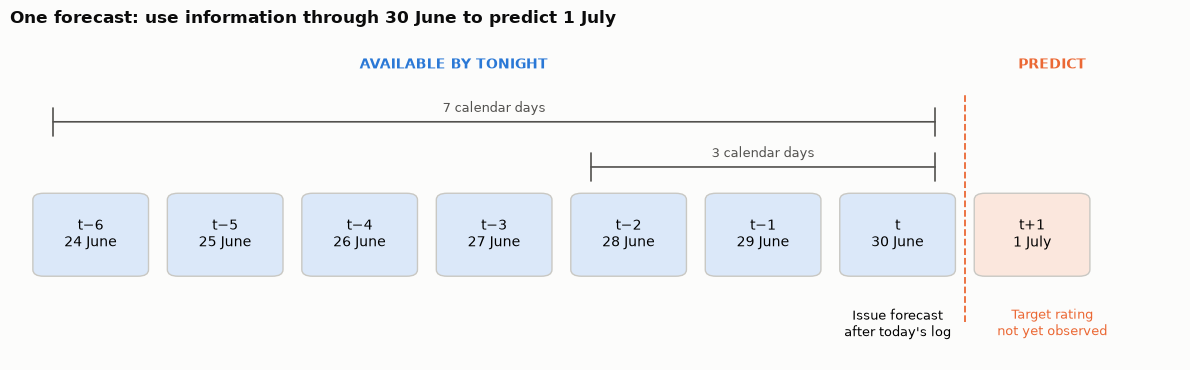

In [17]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.set_xlim(-0.6, 8.1)
ax.set_ylim(-0.7, 3.2)
ax.axis("off")
for x in range(8):
    future = x == 7
    label = "t+1\n1 July" if future else f"{'t' if x == 6 else 't−' + str(6-x)}\n{24+x} June"
    ax.add_patch(FancyBboxPatch((x - 0.4, 0.35), 0.8, 0.95,
                 boxstyle="round,pad=0.03,rounding_size=0.08",
                 facecolor="#fbe7dd" if future else "#dbe8f9", edgecolor="#c9c8c3"))
    ax.text(x, 0.83, label, ha="center", va="center", fontsize=10)
ax.axvline(6.5, ymin=0.12, ymax=0.83, color=ORANGE, linestyle="--", linewidth=1.3)
ax.text(2.7, 2.85, "AVAILABLE BY TONIGHT", color=BLUE, weight="bold", ha="center", fontsize=10)
ax.text(7.15, 2.85, "PREDICT", color=ORANGE, weight="bold", ha="center", fontsize=10)
for left, y, label in [(0, 2.2, "7 calendar days"), (4, 1.65, "3 calendar days")]:
    ax.annotate("", xy=(6.3, y), xytext=(left - 0.3, y),
                arrowprops=dict(arrowstyle="|-|", color=INK_2, lw=1.2))
    ax.text((left + 6) / 2, y + 0.12, label, ha="center", fontsize=9, color=INK_2)
ax.text(6, -0.06, "Issue forecast\nafter today's log", ha="center", va="top", fontsize=9)
ax.text(7.15, -0.06, "Target rating\nnot yet observed", ha="center", va="top", fontsize=9, color=ORANGE)
ax.set_title("One forecast: use information through 30 June to predict 1 July", pad=12)
plt.tight_layout()
plt.show()

### 6.2 How much past information should I use?

I want the features to correspond to questions I can explain:

- **Anxiety history:** does today's rating already give a useful forecast, and does a recent average add context?
- **Lifestyle:** do today's habits and cumulative sleep shortfall add anything after accounting for history?
- **Calendar:** does knowing the target is on a weekend help?
- **Observation coverage:** is a summary based on a full window or only a few recorded values?

For a seven-day lookback, my core feature vector is:

$$x_t=[\underbrace{a_t,\ \bar a_{t-2:t},\ \bar a_{t-6:t}}_{\text{history}},
\underbrace{s_t,\ q_t,\ e_t,\ c_t,\ D_t}_{\text{lifestyle}},
\underbrace{\mathrm{dow}_{t+1}}_{\text{calendar}}],\qquad y_t=a_{t+1}.$$

Here $a$ is anxiety, $s$ sleep adequacy, $q$ sleep quality, $e$ exercise sessions and $c$ social encounters. The bars denote averages ending today. $D_t$ is the cumulative sleep-shortfall score defined below.

For the calendar term, I represent the target weekday with a **weekend indicator**, following Section 5.5: $\mathrm{dow}_{t+1}=1$ for Saturday or Sunday and 0 otherwise. I do not encode weekdays as a numeric scale from 0 to 6, which would impose an arbitrary ordering on a linear model.

Those are nine core features. I keep eight supporting columns to describe missing measurements: five current missingness flags, two coverage fractions for anxiety's rolling means, and one missing-input companion to $D_t$. The actual model input is $\tilde x_t=[x_t,\mathbf m_t]$, with 17 columns in this starting configuration. That distinction makes the equation match the code instead of hiding extra inputs.

**Why not just use raw same-day rows?** Pairing today's habits with today's anxiety would answer a same-evening question. Including today's anxiety as both predictor and target would simply give the answer away. For my next-day question, I keep today's raw measurements but move the target to tomorrow. I also add recent summaries because one rating does not describe the preceding week. Tomorrow's measurements remain unavailable and are excluded.

**Days and lags are different.** A three-day window includes $t-2,t-1,t$: it reaches back two days. For a measurement $v$, I average only its observed entries in that trailing window:

$$\bar v_{k,t}=\frac{\sum_{j=0}^{k-1}I_{t-j}v_{t-j}}{\sum_{j=0}^{k-1}I_{t-j}},
\qquad C_{k,t}=\frac{1}{k}\sum_{j=0}^{k-1}I_{t-j},$$

where $I_u=1$ when $v_u$ is observed and 0 otherwise; the numerator sums only observed values. If none are observed, the mean stays missing. For example, ratings `[2, missing, 4]` give mean 3 and coverage $2/3$. The mean alone would hide how little was recorded. All windows end at $t$; none are centered on it.

The lookback argument $k$ sets the maximum rolling window. I include the standard windows 3 and 7 when they fit, plus $k$ itself if it is greater than one. Thus $k=1$ adds no rolling summaries, $k=3$ adds three-day summaries, and $k=14$ adds 3-, 7- and 14-day summaries. The cumulative sleep score below has its own memory setting. **Seven is a starting configuration, not a validated optimum.** The window comparison comes later.

### 6.3 Keeping track of several nights of poor sleep

A rolling mean treats all days inside a window equally and forgets a day as soon as it falls outside. I also want a candidate that gives a low sleep-adequacy rating some weight for several subsequent days. I construct:

$$z_t=\max(0,3-s_t),\qquad D_t=\lambda D_{t-1}+z_t,\qquad 0<\lambda<1.$$

Ratings 1 and 2 contribute 2 and 1 points; ratings 3–5 contribute zero. The threshold 3 is a design choice. This arithmetic treats steps in an ordinal rating as comparable, so **$D_t$ is a constructed score, not physiological sleep debt or hours of lost sleep**.

Each day's contribution is multiplied by $\lambda$ again on the next day. After $r$ days it has weight $\lambda^r$, giving the half-life:

$$r_{1/2}=\frac{\log(0.5)}{\log(\lambda)}.$$

I fix $\lambda=0.8$ for the calculations and modeling experiments. I do not tune it in this notebook. A higher value forgets more slowly; whether that helps needs development-data evaluation. The recurrence is also separate from the finite lookback $k$, so window experiments should hold it fixed or exclude this feature.

**Missing sleep and initialization.** I initialize $D$ to zero before the first date, because earlier ratings are unavailable. When sleep is missing, I add no *observed* shortfall and let the old score decay. This is not evidence that the missing night was adequate. To make that distinction visible, I also track:

$$M_t=\lambda M_{t-1}+\mathbb{1}[s_t\text{ is missing}],\qquad M_{\text{before start}}=0.$$

$M_t$ records how much recent input is unknown. Under the chosen zero initialization, each missing rating could add 0–2 shortfall points, so its unobserved contribution to the score is between 0 and $2M_t$. That is a bound from the codebook, not a confidence interval. Neither score reconstructs unobserved history before this file begins.

λ = 0.8: half-life = 3.11 days


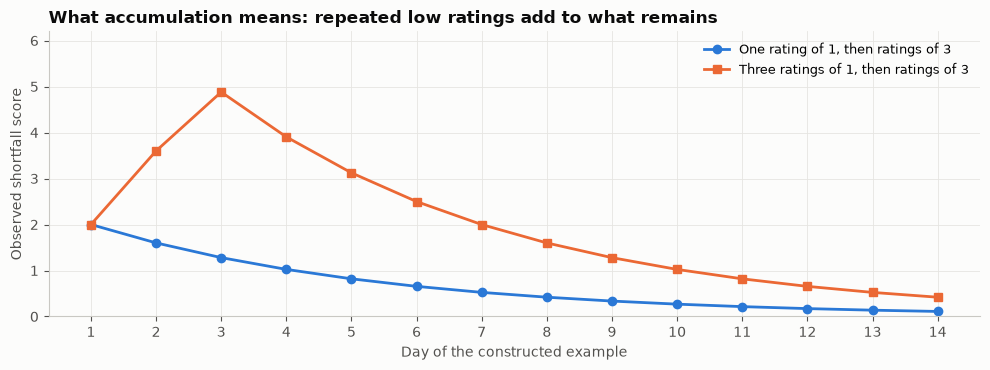

,adequacy,sleep_shortfall,sleep_shortfall_missing_weight
example step (starting at 0),,,
0,1.0,2.0,0.0
1,2.0,2.0,0.0
2,NaN,1.0,1.0
3,4.0,0.5,0.5


In [18]:
def sleep_shortfall_features(adequacy, decay):
    # Accumulate observed shortfalls and track the decayed missing-input weight.
    if not 0 < decay < 1:
        raise ValueError("decay must be strictly between 0 and 1")
    shortfall, missing_weight = 0.0, 0.0
    rows = []
    for value in adequacy:
        missing = pd.isna(value)
        contribution = 0.0 if missing else max(0.0, 3.0 - value)
        shortfall = decay * shortfall + contribution
        missing_weight = decay * missing_weight + float(missing)
        rows.append((shortfall, missing_weight))
    return pd.DataFrame(rows, index=adequacy.index,
                        columns=["sleep_shortfall", "sleep_shortfall_missing_weight"])


SLEEP_DECAY = 0.8  # fixed design choice throughout; not tuned
half_life = np.log(0.5) / np.log(SLEEP_DECAY)
print(f"λ = {SLEEP_DECAY}: half-life = {half_life:.2f} days")

# A constructed example isolates the calculation; these are not observed outcomes.
example_days = pd.RangeIndex(1, 15, name="day")
one_low_night = pd.Series([1] + [3] * 13, index=example_days)
three_low_nights = pd.Series([1] * 3 + [3] * 11, index=example_days)
one_score = sleep_shortfall_features(one_low_night, SLEEP_DECAY)["sleep_shortfall"]
three_score = sleep_shortfall_features(three_low_nights, SLEEP_DECAY)["sleep_shortfall"]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(example_days, one_score, color=BLUE, marker="o", label="One rating of 1, then ratings of 3")
ax.plot(example_days, three_score, color=ORANGE, marker="s", label="Three ratings of 1, then ratings of 3")
ax.set_xticks(range(1, 15))
ax.set_xlabel("Day of the constructed example")
ax.set_ylabel("Observed shortfall score")
ax.set_title("What accumulation means: repeated low ratings add to what remains")
ax.legend(loc="upper right", fontsize=9)
ax.set_ylim(0, 6.2)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"adequacy": [1, 2, np.nan, 4],
                      **sleep_shortfall_features(pd.Series([1, 2, np.nan, 4]), 0.5).to_dict("list")})
          .rename_axis("example step (starting at 0)"))

With $\lambda=0.8$, the half-life is **3.11 days**. In the constructed example, one adequacy rating of 1 starts the score at 2 and it then decays. Three successive ratings of 1 give **2, 3.6 and 4.88** on the first three days, because each new contribution is added to what remains. The figure illustrates that arithmetic; it does not show an estimated relationship with anxiety.

The small table uses $\lambda=0.5$ so I can check every step mentally. The first two ratings, 1 and 2, give scores 2 and 2. On the missing third rating, the observed score decays to 1 while missing-input weight rises to 1. After the fourth rating of 4, they decay to 0.5 and 0.5. A decaying observed score therefore does not mean the unrecorded night was good.

I'll keep both sleep columns as candidates and later compare forecasts with and without them. Neither this illustration nor the chosen decay is evidence that the feature helps.

### 6.4 Building the input features

`FeatureBuilder(lookback, horizon, sleep_decay)` applies those definitions to the intact daily calendar. I keep its work separate from fitting a model:

1. Verify the calendar, then calculate current values, trailing summaries and the two sleep scores.
2. Align the target by shifting anxiety backward $h$ rows. For this verified calendar, that is exactly $h$ days.
3. Return features, targets and alignment metadata separately. Target dates and target availability are never predictor columns.

The builder also records each feature's **domain**. A sleep ablation must remove both sleep ratings, their missingness flags, and both cumulative features. Removing just one sleep column would leave related information behind.

I support positive forecast horizons here, including one and three days. A same-day task ($h=0$) needs a separate issue-time definition and must exclude the target rating itself. Rejecting it in this builder avoids accidentally presenting today's anxiety as a prediction of itself.

In [19]:
class FeatureBuilder:
    # Deterministic feature construction: no fitting, filling, scaling or row removal.
    VARIABLES = {
        "anxiety_level": ("anxiety", "history"),
        "sleep_adequacy": ("sleep_adequacy", "sleep"),
        "sleep_quality": ("sleep_quality", "sleep"),
        "exercise_frequency": ("exercise", "exercise"),
        "socializing_frequency": ("socializing", "socializing"),
    }

    def __init__(self, lookback=7, horizon=1, sleep_decay=0.8):
        for name, value in [("lookback", lookback), ("horizon", horizon)]:
            if isinstance(value, bool) or not isinstance(value, int) or value < 1:
                raise ValueError(f"{name} must be a positive integer")
        if not 0 < sleep_decay < 1:
            raise ValueError("sleep_decay must be strictly between 0 and 1")
        self.lookback, self.horizon, self.sleep_decay = lookback, horizon, sleep_decay
        self.windows = sorted({w for w in (3, 7, lookback) if 1 < w <= lookback})

    def build(self, daily):
        if not isinstance(daily.index, pd.DatetimeIndex) or daily.empty:
            raise ValueError("Expected a nonempty daily DatetimeIndex")
        expected = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
        if not daily.index.equals(expected):
            raise ValueError("Expected unique, ordered, consecutive calendar dates")
        daily = daily.copy()
        daily.index = daily.index.rename("forecast_date")
        features, descriptions = pd.DataFrame(index=daily.index), []

        def add(name, values, domain, meaning):
            features[name] = values
            descriptions.append({"feature": name, "domain": domain, "meaning": meaning})

        for column, (name, domain) in self.VARIABLES.items():
            values = daily[column]
            add(f"{name}_today", values, domain, "Recorded value on issue date")
            add(f"{name}_missing_today", values.isna().astype(float), domain,
                "1 if today's value is missing; 0 otherwise")

        anxiety = daily["anxiety_level"]
        for window in self.windows:
            trailing = anxiety.rolling(window, min_periods=1, center=False)
            add(f"anxiety_mean_{window}d", trailing.mean(), "history",
                f"Observed anxiety mean over {window} calendar days through issue date")
            add(f"anxiety_observed_{window}d", trailing.count() / window, "history",
                f"Fraction of anxiety ratings observed in the {window}-day window")

        sleep_scores = sleep_shortfall_features(daily["sleep_adequacy"], self.sleep_decay)
        add("sleep_shortfall", sleep_scores["sleep_shortfall"], "sleep",
            f"Observed shortfall accumulation; threshold 3, decay {self.sleep_decay}")
        add("sleep_shortfall_missing_weight", sleep_scores["sleep_shortfall_missing_weight"],
            "sleep", "Decayed weight of missing sleep-adequacy inputs")

        target_dates = daily.index + pd.Timedelta(days=self.horizon)
        add("target_is_weekend", (target_dates.dayofweek >= 5).astype(float), "calendar",
            "1 if target date is Saturday or Sunday; known at issue time")
        target = daily["anxiety_level"].shift(-self.horizon).rename("target_anxiety")
        alignment = pd.DataFrame({
            "target_date": target_dates,
            "full_window": np.arange(len(daily)) >= self.lookback - 1,
            "target_in_calendar": target_dates.isin(daily.index),
        }, index=daily.index)
        self.feature_dictionary = pd.DataFrame(descriptions).set_index("feature")
        return features, target, alignment

### What each input feature means

The names below are the actual columns used in the code. The core nine correspond to the underbraced equation. Supporting indicators make missingness visible without filling the measurements or outcomes.

| Symbol / role | Code columns | Meaning |
|---|---|---|
| $a_t$ | `anxiety_today` | Anxiety on the forecast issue date |
| $\bar a_{t-2:t}$ | `anxiety_mean_3d` | Mean observed anxiety over today and the preceding two calendar days |
| $\bar a_{t-6:t}$ | `anxiety_mean_7d` | Mean observed anxiety over today and the preceding six calendar days |
| $s_t, q_t$ | `sleep_adequacy_today`, `sleep_quality_today` | Ratings for the night preceding the issue date |
| $e_t, c_t$ | `exercise_today`, `socializing_today` | Sessions and encounters on the issue date |
| $D_t$ | `sleep_shortfall` | Accumulated observed adequacy shortfalls, in rating-score units |
| $\mathrm{dow}_{t+1}$ | `target_is_weekend` | 1 for a weekend target date, 0 otherwise |
| Five current missingness flags | `*_missing_today` | 1 when a current measurement is absent; 0 when recorded |
| Two history-coverage fractions | `anxiety_observed_3d`, `anxiety_observed_7d` | Proportion of each anxiety window actually recorded |
| Missing sleep-input weight | `sleep_shortfall_missing_weight` | Decayed weight of unrecorded sleep adequacy |

This gives **9 core + 8 supporting = 17 candidate features**. Today's rating and overlapping averages are correlated; more columns do not automatically mean a better forecast. No feature has been selected because of a model score yet.

In [20]:
builder = FeatureBuilder(lookback=7, horizon=1, sleep_decay=SLEEP_DECAY)
all_features, all_targets, alignment = builder.build(clean)
feature_dictionary = builder.feature_dictionary.copy()
assert all_features.shape[1] == 17  # nine core features and eight missingness/coverage columns
assert feature_dictionary.index.is_unique
assert feature_dictionary.index.equals(all_features.columns)
assert {"target_anxiety", "target_date", "target_in_calendar", "full_window"}.isdisjoint(all_features.columns)

domain_summary = feature_dictionary.groupby("domain", sort=False).size().to_frame("candidate features")
display(domain_summary)
print(f"Full calendar matrix: {all_features.shape[0]:,} rows × {all_features.shape[1]} features")
print("Target and alignment metadata are stored separately from the feature matrix.")

# One actual row makes the notation concrete, without fitting or scoring a model.
example_date = pd.Timestamp("2025-06-30")
print(f"\nIssue date: {example_date.date()} · target date: {alignment.loc[example_date, 'target_date'].date()}")
display(all_features.loc[[example_date], ["anxiety_today", "anxiety_mean_3d", "anxiety_mean_7d",
                                         "sleep_adequacy_today", "sleep_shortfall", "target_is_weekend"]].round(3))

,candidate features
domain,
history,6
sleep,6
exercise,2
socializing,2
calendar,1


Full calendar matrix: 1,380 rows × 17 features
Target and alignment metadata are stored separately from the feature matrix.

Issue date: 2025-06-30 · target date: 2025-07-01


,anxiety_today,anxiety_mean_3d,anxiety_mean_7d,sleep_adequacy_today,sleep_shortfall,target_is_weekend
forecast_date,,,,,,
2025-06-30,5.0,3.667,3.0,2.0,2.284,0.0


### 6.5 Checking the feature dates and calculations

I want more than a comment saying "no leakage." These checks target mistakes that would change the forecasting task:

- A small hand-worked example verifies rolling means, coverage and the sleep recurrence, including missing inputs.
- Target checks verify the one- and three-day alignment and confirm that missing outcomes stay missing.
- Removing or reordering a calendar day must be rejected. Otherwise a row shift could quietly change its meaning.
- Changing every measurement after a cutoff must leave all earlier features unchanged. Rebuilding from a prefix must also reproduce those features. I compare **features**, because later outcomes are expected to change targets.
- Changing a measurement available tonight must change the relevant feature tonight. This guards against an invariance check passing just because the features are constant or ignore their inputs.

In [21]:
# A deliberately small example that can be checked by hand.
toy_dates = pd.date_range("2024-01-01", periods=8, freq="D")
toy = pd.DataFrame({
    "anxiety_level": [1, 2, np.nan, 4, 5, 6, 7, 8],
    "sleep_adequacy": [1, 2, np.nan, 4, 3, 5, 2, 1],
    "sleep_quality": [2, 3, 3, 4, 3, 5, 2, 2],
    "exercise_frequency": [0, 1, 0, 1, 0, 1, 0, 1],
    "socializing_frequency": [1, 2, 1, 3, 2, 1, 0, 2],
}, index=toy_dates)
toy_builder = FeatureBuilder(lookback=3, horizon=1, sleep_decay=0.5)
toy_x, toy_y, toy_alignment = toy_builder.build(toy)
third = toy_dates[2]
assert np.isclose(toy_x.loc[third, "anxiety_mean_3d"], (1 + 2) / 2)
assert np.isclose(toy_x.loc[third, "anxiety_observed_3d"], 2 / 3)
assert np.isnan(toy_x.loc[third, "anxiety_today"])
assert toy_x.loc[third, "anxiety_missing_today"] == 1
np.testing.assert_allclose(toy_x["sleep_shortfall"].iloc[:4], [2, 2, 1, 0.5])
np.testing.assert_allclose(toy_x["sleep_shortfall_missing_weight"].iloc[:4], [0, 0, 1, 0.5])

# Verify the missing-input bound by trying both endpoints allowed by the codebook.
worst_missing_sleep = sleep_shortfall_features(toy["sleep_adequacy"].fillna(1), 0.5)
best_missing_sleep = sleep_shortfall_features(toy["sleep_adequacy"].fillna(5), 0.5)
np.testing.assert_allclose(best_missing_sleep["sleep_shortfall"], toy_x["sleep_shortfall"])
np.testing.assert_allclose(worst_missing_sleep["sleep_shortfall"] - toy_x["sleep_shortfall"],
                           2 * toy_x["sleep_shortfall_missing_weight"])
unreported = toy.copy()
unreported.loc[:third, "anxiety_level"] = np.nan
unreported_x, _, _ = toy_builder.build(unreported)
assert np.isnan(unreported_x.loc[third, "anxiety_mean_3d"])
assert unreported_x.loc[third, "anxiety_observed_3d"] == 0

assert np.isnan(toy_y.loc[toy_dates[1]])  # its target rating is missing, not filled
assert toy_y.loc[third] == 4
assert toy_alignment.loc[third, "target_date"] == toy_dates[3]
assert toy_x.loc[pd.Timestamp("2024-01-05"), "target_is_weekend"] == 1  # target Saturday
_, three_day_y, three_day_alignment = FeatureBuilder(horizon=3).build(toy)
assert three_day_y.iloc[0] == 4
assert three_day_alignment.iloc[0]["target_date"] == toy_dates[3]

The first checks use an eight-day arithmetic example so I can verify the numbers directly. The next checks use the full cleaned table. I deliberately corrupt its future in a copy, then rebuild the features. If any earlier row changes, a feature has used information from the wrong side of the forecast boundary.

In [22]:
for broken_calendar in [toy.drop(toy_dates[2]), toy.iloc[::-1], toy.iloc[[0, 0, 1, 2, 3, 4, 5, 6, 7]]]:
    try:
        FeatureBuilder().build(broken_calendar)
    except ValueError:
        pass
    else:
        raise AssertionError("An invalid daily calendar was accepted")
try:
    FeatureBuilder(horizon=0)
except ValueError:
    pass
else:
    raise AssertionError("The forecasting builder accepted a same-day target")

for cutoff in ["2023-01-03", "2023-07-01", "2025-06-30"]:
    changed = clean.copy()
    future = changed.index > pd.Timestamp(cutoff)
    for column, (low, high) in DataCleaner.VALID_RANGES.items():
        high = 5 if high is None else high  # valid alternate socializing count
        changed.loc[future, column] = np.where(changed.loc[future, column] == low, high, low)
    changed_x, _, _ = builder.build(changed)
    prefix_x, _, _ = builder.build(clean.loc[:cutoff])
    pd.testing.assert_frame_equal(all_features.loc[:cutoff], changed_x.loc[:cutoff])
    pd.testing.assert_frame_equal(all_features.loc[:cutoff], prefix_x)

changed_today = clean.copy()
cutoff = pd.Timestamp("2025-06-30")
old = changed_today.loc[cutoff, "sleep_adequacy"]
changed_today.loc[cutoff, "sleep_adequacy"] = 1 if old != 1 else 5
changed_x, _, _ = builder.build(changed_today)
assert changed_x.loc[cutoff, "sleep_adequacy_today"] != all_features.loc[cutoff, "sleep_adequacy_today"]
pd.testing.assert_frame_equal(all_features.loc[:cutoff].iloc[:-1], changed_x.loc[:cutoff].iloc[:-1])

print("Passed: hand calculations, missing-input handling, horizon alignment, calendar guards,")
print("future-change invariance, prefix reproducibility, and response to an available input.")

Passed: hand calculations, missing-input handling, horizon alignment, calendar guards,
future-change invariance, prefix reproducibility, and response to an available input.


The hand calculations, target alignment and calendar checks passed. An entirely unobserved window stays missing with coverage zero. The missing-sleep bound also matches the scores obtained by filling the unknown input with each endpoint of its codebook; those fills are used only for this check, never for the modeling table.

At all three cutoffs, changing every future measurement left earlier features identical. Rebuilding from just the available prefix also reproduced them, including across the July 2023 missing-data run. Changing sleep adequacy on the issue date changed that day's input and left earlier rows alone.

These checks support the timing and arithmetic of this implementation. They do not establish forecast accuracy. No imputer, scaler or model has been fitted, so training-fold checks will still be needed when those steps are added.

### 6.6 Which days can I use for the models?

The builder returned every issue date, including dates with missing predictors. I now apply a separate eligibility rule:

1. Exclude the first $k-1$ issue dates so every retained row has a complete **calendar** lookback. This does not require all measurements in that window to be observed.
2. Exclude forecasts whose target date lies beyond the file.
3. Exclude any remaining forecast whose target anxiety rating is missing.

Only after this alignment do I select rows. I do **not** remove days with missing current anxiety before shifting the target: that would compress time and discard some otherwise usable examples. A missing rating can be an unavailable predictor today while tomorrow's target is observed.

The matrix will still contain missing predictors. Later, imputation and scaling must be fitted inside each training fold. Persistence also needs a documented fallback when today's rating is missing; that policy belongs with the baselines, not with feature construction.

In [23]:
full_window = alignment["full_window"]
target_in_file = alignment["target_in_calendar"]
observed_target = all_targets.notna()
eligible = full_window & target_in_file & observed_target

row_audit = pd.Series({
    "Issue dates in the original calendar": len(clean),
    "After requiring a full calendar lookback": int(full_window.sum()),
    "After requiring target date inside the file": int((full_window & target_in_file).sum()),
    "After requiring an observed target rating": int(eligible.sum()),
}, name="rows")
display(row_audit.to_frame())

X_features = all_features.loc[eligible].copy()
y_next = all_targets.loc[eligible].copy()
forecast_dates = alignment.loc[eligible].copy()

assert X_features.index.equals(y_next.index)
assert X_features.index.equals(forecast_dates.index)
assert y_next.notna().all()
expected_y = clean["anxiety_level"].reindex(pd.DatetimeIndex(forecast_dates["target_date"]))
np.testing.assert_array_equal(y_next.to_numpy(), expected_y.to_numpy())

print(f"Ready for chronological splitting: {len(X_features):,} forecasts × {X_features.shape[1]} candidate features")
print(f"Target dates: {forecast_dates['target_date'].min().date()} to {forecast_dates['target_date'].max().date()}")
print(f"Retained forecasts with at least one missing predictor: {X_features.isna().any(axis=1).sum()}")
print(f"Retained forecasts with missing current anxiety: {X_features['anxiety_today'].isna().sum()}")
print(f"Missing predictor cells: {X_features.isna().sum().sum()}")

modeling_table = X_features.copy()
modeling_table.insert(0, "target_date", forecast_dates["target_date"])
modeling_table["target_anxiety"] = y_next
print("The aligned modeling table and feature dictionary remain available in memory.")
print("No imputation, scaling or model fitting has been applied.")

,rows
Issue dates in the original calendar,1380
After requiring a full calendar lookback,1374
After requiring target date inside the file,1373
After requiring an observed target rating,1365


Ready for chronological splitting: 1,365 forecasts × 17 candidate features
Target dates: 2023-01-08 to 2026-10-11
Retained forecasts with at least one missing predictor: 28
Retained forecasts with missing current anxiety: 4
Missing predictor cells: 41
The aligned modeling table and feature dictionary remain available in memory.
No imputation, scaling or model fitting has been applied.


The seven-day configuration gives **1,365 eligible forecasts and 17 candidate features**. Starting with 1,380 issue dates, I exclude six without a full calendar lookback, one whose target is beyond the file, and eight whose target rating is missing. The resulting target dates run from **8 January 2023 to 11 October 2026**.

I retain **28 forecasts with at least one missing predictor**, including **four with missing current anxiety**. There are **41 missing predictor cells** in total. These are genuine gaps to handle inside training folds, not reasons to invent target ratings. Coverage and missingness indicators already describe the gaps without filling the underlying values.

The domain counts are **6 history, 6 sleep, 2 exercise, 2 socializing and 1 calendar feature**. The core nine columns match the equation; the other eight describe missingness and coverage. The feature dictionary records each column's domain so later ablations remove all related inputs together.

The modeling table is now aligned in memory, but it has not been split or used to fit anything. Next I will define ridge and its objective in Section 7, then establish chronological splits and baseline forecasts in Section 8. The window and feature set will be compared using development data. Decay 0.8 and shortfall threshold 3 remain fixed design assumptions; their alternatives are not tested here.

### 6.7 Choosing how many days to look back (Section 11)

Seven days is an understandable starting point: it gives me today's rating, a short three-day view and a full week. It is not a result. A longer window might smooth noise, but it could also blur a sudden change; a shorter window may react faster but rely on fewer observations.

In **Section 11**, I will compare $k=1,3,7,14$ on development data, not choose a window from the final 2026 evaluation. The table below only checks what each configuration constructs. It reports no forecast errors.

Two controls matter for that comparison. First, larger windows exclude more dates at the start, so I should score configurations on common target dates where possible. Second, $D_t$ has its own decay parameter: changing $k$ does not change its memory. I will hold that feature fixed or remove it when isolating the rolling-window comparison. I do not vary the decay or threshold in these comparisons; their sensitivity remains a limitation.

In [24]:
window_rows = []
for k in [1, 3, 7, 14]:
    candidate = FeatureBuilder(lookback=k, horizon=1, sleep_decay=SLEEP_DECAY)
    candidate_x, candidate_y, candidate_dates = candidate.build(clean)
    usable = candidate_dates["full_window"] & candidate_dates["target_in_calendar"] & candidate_y.notna()
    window_rows.append({"k (calendar days)": k,
                        "anxiety averaging windows": str(candidate.windows),
                        "candidate features": candidate_x.shape[1],
                        "eligible forecasts": int(usable.sum())})
display(pd.DataFrame(window_rows).set_index("k (calendar days)"))
print("Construction counts only. Section 11 will compare validation errors.")

,anxiety averaging windows,candidate features,eligible forecasts
k (calendar days),,,
1,[],13,1371
3,[3],15,1369
7,"[3, 7]",17,1365
14,"[3, 7, 14]",19,1358


Construction counts only. Section 11 will compare validation errors.


<a id="section-7"></a>

## 7. Starting with ridge regression

I now have one row for each eligible forecast: what I know tonight, paired with tomorrow evening's anxiety. The next question is how to turn that row into a prediction.

I want to start with a model whose calculation I can follow. Ridge regression gives each input a weight, adds the contributions together, and learns those weights while discouraging unnecessarily large values. This lets me examine whether habits add predictive information alongside recent anxiety. The comparison with history-only models will answer that question; a coefficient by itself will not.

Three questions guide the math here: how do I calculate a forecast, how do I learn the weights, and how do I judge the result? The **prediction rule** tells me how a row becomes a forecast. The **training objective** tells me which weights the model prefers. **Evaluation on later dates** tells me whether those learned weights are useful. A small training objective alone cannot answer my original question.

### 7.1 Why I chose ridge first

There is a reason to use ridge rather than ordinary least squares here. Today's anxiety, its three-day average and its seven-day average overlap. Sleep adequacy, sleep quality and accumulated sleep shortfall may also carry overlapping information. With related predictors, several combinations of weights can produce similar predictions. Large weights that cancel each other are hard to interpret and may be sensitive to small changes in the training period.

Ridge adds a cost for large weights. It trades some fit to the training observations for a preference for smaller coefficients. Whether that trade improves future forecasts is an empirical question, and the strength of the penalty must be chosen on development data.

For example, if today's rating and its recent average usually rise together, the model may struggle to decide how much credit to assign to each. One fit might place a large positive weight on the first and a negative weight on the second; another might use two smaller weights and make almost the same predictions. This is the issue of **multicollinearity**. It does not make prediction impossible, but it makes individual coefficients less stable. Ridge makes the large-weight option more expensive. It does not tell me which correlated feature is the true cause.

This is the **bias–variance tradeoff** in this setting. Shrinkage can move the fitted relationship away from the best unpenalized training fit, introducing bias, while making the coefficients less sensitive to the particular training observations. That reduced sensitivity can help on later dates. If I shrink too strongly, however, I can lose useful information and underfit. The validation results will decide whether the tradeoff helps this journal.

This is also a useful first model because it makes a clear assumption: each feature contributes additively, with the same slope across its range. Moving sleep adequacy from 1 to 2 has the same modeled contribution as moving it from 4 to 5. The ratings are ordered categories, so that equal-step assumption is an approximation. Thresholds and interactions would need additional features or a different model; I have not tested those here.

### 7.2 What the symbols mean

Section 6 produced **1,365 eligible forecasts with 17 candidate input columns**. That is the entire eligible pool, not the size of the training set. I will assign dates to training, validation and final evaluation in Section 8.

In Section 6, $x_t$ described the nine core inputs and $\widetilde{x}_t$ included the eight missingness and coverage columns. From here onward, I use $x_t$ for the **complete 17-column model input after preprocessing**. The extra columns are still included.

The date subscript matters: $y_t$ is the target attached to the forecast issued at $t$, so it means $a_{t+1}$, not $a_t$. Current anxiety $a_t$ can be an input because I already know it tonight. Tomorrow's anxiety is the outcome I am trying to predict.

In [25]:
n_eligible, d_features = X_features.shape
ridge_notation = pd.DataFrame([
    (r"t", "Forecast issue date", "An evening whose inputs are available"),
    (r"n", "Number of rows used in a particular fit", "Defined by the training dates or CV fold; not the whole pool"),
    (r"d", "Number of input columns", str(d_features)),
    (r"x_t", "One preprocessed feature vector", f"{d_features} values, all available by evening t"),
    (r"X", "Preprocessed training design matrix", f"n rows × {d_features} columns"),
    (r"y_t = a_(t+1)", "Observed target", "Tomorrow evening's 0–10 self-rating"),
    (r"w", "Feature weights", f"{d_features} learned coefficients"),
    (r"b", "Intercept", "One learned constant; excluded from the penalty"),
    (r"y_hat_t", "Model forecast of y_t", "A real-valued anxiety prediction"),
    (r"alpha", "Penalty strength", "Non-negative; selected using development data"),
], columns=["Symbol", "Meaning", "In this notebook"]).set_index("Symbol")
display(ridge_notation)
print(f"Eligible pool: {n_eligible:,} rows; candidate inputs: {d_features}.")
print("No training dates, preprocessing parameters or coefficients have been fitted here.")

,Meaning,In this notebook
Symbol,,
t,Forecast issue date,An evening whose inputs are available
n,Number of rows used in a particular fit,Defined by the training dates or CV fold; not ...
d,Number of input columns,17
x_t,One preprocessed feature vector,"17 values, all available by evening t"
X,Preprocessed training design matrix,n rows × 17 columns
y_t = a_(t+1),Observed target,Tomorrow evening's 0–10 self-rating
w,Feature weights,17 learned coefficients
b,Intercept,One learned constant; excluded from the penalty
y_hat_t,Model forecast of y_t,A real-valued anxiety prediction


Eligible pool: 1,365 rows; candidate inputs: 17.
No training dates, preprocessing parameters or coefficients have been fitted here.


### 7.3 How the inputs become a prediction

For one forecast, ridge uses a weighted sum:

$$\widehat{y}_t=b+x_t^\top w=b+\sum_{j=1}^{d}x_{tj}w_j.$$

For all $n$ training rows together, the same calculation is

$$\widehat{\mathbf y}=Xw+b\mathbf 1_n.$$

Here is what that matrix multiplication contains:

$$\underbrace{\begin{bmatrix}
x_{t_1,1}&\cdots&x_{t_1,17}\\
x_{t_2,1}&\cdots&x_{t_2,17}\\
\vdots&&\vdots\\
x_{t_n,1}&\cdots&x_{t_n,17}
\end{bmatrix}}_{X:\ n\times17}
\underbrace{\begin{bmatrix}w_1\\w_2\\\vdots\\w_{17}\end{bmatrix}}_{w:\ 17\times1}
+\underbrace{b\begin{bmatrix}1\\1\\\vdots\\1\end{bmatrix}}_{n\times1}
=\underbrace{\begin{bmatrix}\widehat y_{t_1}\\\widehat y_{t_2}\\\vdots\\\widehat y_{t_n}\end{bmatrix}}_{\widehat{\mathbf y}:\ n\times1}.$$

Each row is one forecast, and each column is the same feature across forecasts. The $t_i$ are the retained issue dates in chronological order; a day with a missing target may be absent, so consecutive rows need not be consecutive calendar days. Multiplying one row by $w$ means multiplying each input by its weight and adding the 17 products. The vector of ones adds the same intercept to every forecast. In NumPy this is `X @ w + b`: `@` performs the matrix multiplication, and broadcasting adds the scalar `b` to every row's result.

The intercept $b$ sets the overall level. Each $w_j$ changes the forecast according to the corresponding input. Unlike a classifier, this model does not use a sigmoid: its output is already a number on the anxiety scale.

**The preprocessing is part of the model.** `X_features` currently contains missing values and columns with different units. Inside each training fold, I will first fit a median imputer and then standardize the columns:

$$x_{tj}=\frac{v_{tj}-\mu_j}{s_j},$$

where $v_{tj}$ is the observed or imputed feature, and $\mu_j,s_j$ are computed from that fold's imputed training rows only. A constant column uses scale 1. Validation and future rows use those same fitted values. I will put these steps inside a `Pipeline` in Section 9 so neither missing-value estimates nor scaling can borrow information from evaluation dates.

For clarity, $s_j$ in this equation is a feature's training standard deviation, not the sleep-adequacy rating $s_t$ from Section 6. Subtracting $\mu_j$ makes a typical training value close to zero; dividing by $s_j$ measures differences in standard-deviation units. I standardize the inputs, not the target, so the model's forecast remains in anxiety points. Median imputation supplies a usable numeric input where a measurement is absent; the missingness and coverage columns preserve information about those gaps. No target rating is imputed.

Scaling matters for ridge because its penalty acts on coefficients. Without it, changing a feature's units could change how strongly its contribution is penalized. I will standardize all 17 columns consistently, including the existing missingness indicators; a constant indicator will simply become zero within that fit.

Suppose I rewrote an input as a number ten times larger. Dividing its coefficient by ten would preserve every prediction, but its squared coefficient would become one hundred times smaller. The penalty would then prefer that representation just because I changed the units. Standardization prevents this arbitrary unit choice from setting the relative penalty strength. It does not remove correlation between columns.

For a small arithmetic example, suppose only two standardized inputs are present: current anxiety is one training standard deviation above its mean, and sleep adequacy is one below. With **illustrative, unlearned** weights $0.6$ and $-0.2$, and intercept $3$, the calculation is

$$\widehat y=3+(1)(0.6)+(-1)(-0.2)=3.8.$$

| Part of the calculation | Value | Contribution to the forecast |
|---|---:|---:|
| Intercept | $b=3$ | $3.0$ points |
| Current anxiety | $x_1=1,\ w_1=0.6$ | $+0.6$ points |
| Sleep adequacy | $x_2=-1,\ w_2=-0.2$ | $+0.2$ points |
| Total | $3.0+0.6+0.2$ | $3.8$ points |

The last contribution is positive because a below-average sleep value is multiplied by a negative weight. That sign calculation is easy to miss: a negative coefficient does not mean that every observed value subtracts from the prediction. It is the product $x_{tj}w_j$ that contributes.

Those numbers explain the calculation; they are not estimates from my journal. In the fitted model, a weight describes a one-training-standard-deviation change while keeping the other inputs fixed. Related features make that a conditional association, not an isolated effect of changing a habit.

For a nonconstant binary input such as the weekend flag, a switch from 0 to 1 is a raw change of one, not necessarily one standard deviation. Its contribution changes by $w_j/s_j$ after standardization. Also, holding current anxiety fixed while changing a rolling anxiety average may describe an unusual combination of inputs. These are reasons to read the coefficient table alongside feature definitions and ablations, rather than treating it as a ranking of what controls my anxiety.

A linear forecast can fall outside 0–10. I will initially evaluate its raw predictions and report any out-of-range values. Any later clipping policy must be decided on development data and applied consistently before final evaluation.

### 7.4 How the model learns its weights

For each training row, the residual is $y_t-\widehat y_t$. Squaring it gives larger errors more influence and prevents positive and negative errors from canceling. Averaging those squared errors gives the data-fit part of the objective. Ridge adds a second part:

Writing out the two pieces before using matrix notation helps me see exactly what is being minimized:

$$\mathrm{MSE}(w,b)=\frac1n\sum_{i=1}^{n}\left[y_{t_i}-\left(b+\sum_{j=1}^{d}x_{t_i j}w_j\right)\right]^2,
\qquad \lVert w\rVert_2^2=\sum_{j=1}^{d}w_j^2.$$

An error of 2 points contributes $4$ to the squared-error sum; an error of 1 contributes $1$. The sign of either error disappears after squaring. The factor $1/n$ makes the fit term an average over training rows. It does not make the errors themselves small, and the squared-error term is in squared anxiety points, not the original rating units. RMSE will later take a square root to return to anxiety points.

$$\boxed{J(w,b)=\underbrace{\frac1n\lVert\mathbf y-Xw-b\mathbf 1_n\rVert_2^2}_{\text{mean squared training error}}+\underbrace{\alpha\lVert w\rVert_2^2}_{\text{penalty for large weights}}.}$$

Learning means finding $w,b$ that minimize this sum. With $\alpha=0$, this is ordinary least squares. Increasing $\alpha$ makes large weights more costly; it does not guarantee a better forecast. Very strong regularization pushes feature contributions toward zero and leaves predictions close to the fitted intercept. Ridge usually shrinks coefficients rather than setting them exactly to zero.

More precisely, the fitted parameters are $(\widehat w,\widehat b)=\operatorname*{arg\,min}_{w,b}J(w,b)$. The notation `arg min` means the **parameter values** at the minimum, rather than the minimum objective value itself. The model learns $w,b$ from training observations. I choose $\alpha$ separately through validation; it is a hyperparameter, not another coefficient learned by this minimization.

The penalty counts both positive and negative weights: $(-2)^2=2^2=4$. Doubling a coefficient multiplies its penalty contribution by four. It therefore discourages large magnitudes, rather than favoring one sign. The weights are penalized together in their standardized feature coordinates; this does not mean every coefficient changes by the same percentage when $\alpha$ changes.

I leave $b$ out of the penalty. The model should learn the overall anxiety level without being pulled toward a zero baseline. Also, **$J$ is the training objective, not the evaluation score**: the penalty is not a forecast error. Later I will report MAE, RMSE, $R^2$ and skill relative to persistence on held-out dates.

I can check what leaving the intercept unpenalized implies. Differentiating only with respect to $b$ gives

$$\frac{\partial J}{\partial b}=-\frac{2}{n}\sum_{i=1}^{n}(y_{t_i}-x_{t_i}^\top w-b)=0
\quad\Longrightarrow\quad
\widehat b=\overline y-\overline x^\top\widehat w.$$

Here $\overline x$ is the vector of training feature means. After centering the inputs, $\overline x=0$, so $\widehat b=\overline y$: the intercept is the training target mean. The weights then explain deviations around that level. This also explains why, as the penalty becomes very strong and weights approach zero, forecasts approach the training mean. These statements apply to the unweighted, unpenalized-intercept objective written above.

Below I implement the two pieces directly. This function evaluates supplied weights; it does not learn them. The gradient and closed-form solution belong in Section 10.

The function follows the equation line by line: `X @ w + b` gives $\widehat{\mathbf y}$, `np.mean((y - predictions) ** 2)` gives the fit term, and `alpha * (w @ w)` gives $\alpha\sum_j w_j^2$. The shape and finite-value checks catch an unprocessed or misaligned input rather than allowing a meaningless loss to propagate. Returning the two parts separately makes it possible to see why a total changed.

**The worked example below uses three deliberately simple rows.** Both input columns contain $[-1,0,1]^\top$, the targets are $[1,3,5]^\top$, and the intercept is 3. For these identical columns, predictions depend on $w_1+w_2$: choosing $(2,0)$ or $(1,1)$ gives $[-2,0,2]+3=[1,3,5]$. That lets me change the weight allocation without changing the fit. I set $\alpha=0.25$ only to make the arithmetic visible; it is not a tuned setting for my journal.

In [26]:
def ridge_loss_components(X, y, w, b, alpha):
    '''Average squared error + alpha * squared weights; intercept unpenalized.'''
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)
    if X.ndim != 2 or y.shape != (X.shape[0],) or w.shape != (X.shape[1],):
        raise ValueError("Expected X: (n, d), y: (n,), and w: (d,)")
    if len(y) == 0 or not all(np.isfinite(a).all() for a in (X, y, w)):
        raise ValueError("The loss needs nonempty, finite, preprocessed inputs")
    if not np.isscalar(b) or not np.isscalar(alpha):
        raise ValueError("b and alpha must be scalars")
    if not np.isfinite(b) or not np.isfinite(alpha) or alpha < 0:
        raise ValueError("b must be finite, and alpha must be finite and non-negative")
    predictions = X @ w + b
    mse = float(np.mean((y - predictions) ** 2))
    penalty = float(alpha * (w @ w))
    return {"MSE": mse, "Penalty": penalty, "Objective": mse + penalty}


# Deliberately artificial inputs: two identical columns make overlap exact.
# These are arithmetic examples, not observations or fitted journal models.
demo_X = np.array([[-1., -1.], [0., 0.], [1., 1.]])
demo_y = np.array([1., 3., 5.])
demo_b, demo_alpha = 3., 0.25
demo_weights = {
    "A · all weight on one input": np.array([2., 0.]),
    "B · share the same contribution": np.array([1., 1.]),
    "C · smaller total contribution": np.array([0.5, 0.5]),
}
demo_losses = pd.DataFrame({
    name: {"w1": weights[0], "w2": weights[1],
           **ridge_loss_components(demo_X, demo_y, weights, demo_b, demo_alpha)}
    for name, weights in demo_weights.items()
}).T
display(demo_losses.round(3))

# Both exact-fit choices predict the same values; B has half A's penalty.
np.testing.assert_allclose(demo_X @ demo_weights[list(demo_weights)[0]] + demo_b, demo_y)
np.testing.assert_allclose(demo_X @ demo_weights[list(demo_weights)[1]] + demo_b, demo_y)
np.testing.assert_allclose(demo_losses["MSE"], [0., 0., 2 / 3])
np.testing.assert_allclose(demo_losses["Penalty"], [1., 0.5, 0.125])

# Shifting every target and the intercept together must not change the loss.
shifted = ridge_loss_components(demo_X, demo_y + 2, np.array([1., 1.]), demo_b + 2, demo_alpha)
np.testing.assert_allclose(shifted["Objective"], demo_losses.iloc[1]["Objective"])
print("Hand calculations and the unpenalized-intercept check passed.")

,w1,w2,MSE,Penalty,Objective
A · all weight on one input,2.0,0.0,0.000,1.000,1.000
B · share the same contribution,1.0,1.0,0.000,0.500,0.500
C · smaller total contribution,0.5,0.5,0.667,0.125,0.792


Hand calculations and the unpenalized-intercept check passed.


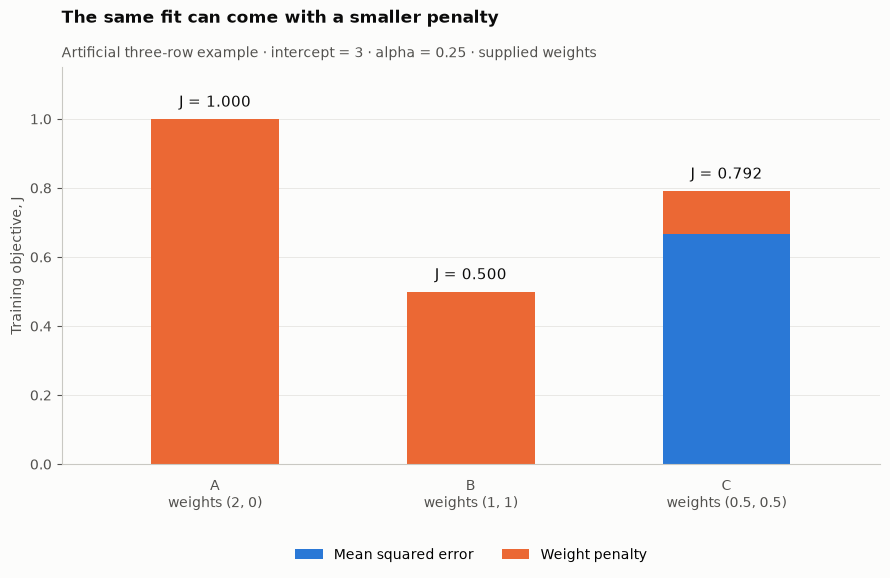

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))
positions = np.arange(len(demo_losses))
ax.bar(positions, demo_losses["MSE"], color=BLUE, width=0.5, label="Mean squared error")
ax.bar(positions, demo_losses["Penalty"], bottom=demo_losses["MSE"],
       color=ORANGE, width=0.5, label="Weight penalty")
for pos, total in zip(positions, demo_losses["Objective"]):
    ax.text(pos, total + 0.025, f"J = {total:.3f}", ha="center", va="bottom", color=INK, fontsize=11)
ax.set_xticks(positions, ["A\nweights (2, 0)", "B\nweights (1, 1)", "C\nweights (0.5, 0.5)"])
ax.tick_params(axis="x", length=0, pad=10)
ax.set_ylim(0, 1.15)
ax.set_xlim(-0.6, 2.6)
ax.set_ylabel("Training objective, J")
ax.set_title("The same fit can come with a smaller penalty", pad=32)
ax.text(0, 1.025, "Artificial three-row example · intercept = 3 · alpha = 0.25 · supplied weights",
        transform=ax.transAxes, fontsize=10, color=INK_2)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
plt.show()

**How to read the figure.** Each bar is one supplied pair of weights. The blue part is mean squared prediction error, the orange part is the weight penalty, and the full height is their sum, $J$. A and B have no visible blue segment because their MSE is exactly zero in this constructed example. Their orange bars are not forecast errors. A lower total is preferred by this particular training objective, at this particular alpha.

Choices A and B both predict the three artificial targets exactly, so both have zero training MSE. Sharing the contribution between two identical inputs changes the squared-weight sum from $2^2+0^2=4$ to $1^2+1^2=2$. With $\alpha=0.25$, the penalty drops from **1.000 to 0.500** without changing a prediction.

Choice C makes both weights smaller again. Its penalty falls to **0.125**, but its predictions become $2,3,4$ instead of $1,3,5$. The residuals are $-1,0,1$, so its MSE is $[(-1)^2+0^2+1^2]/3=2/3\approx\mathbf{0.667}$. Adding the penalty gives $J\approx\mathbf{0.792}$. C pays less for its weights, but its worse fit costs more than it saves relative to B.

B has the lowest objective **among these three supplied choices**. I have not searched over all possible weights, and B is not claimed to be the overall ridge solution. The intercept-shift check provides another useful check on the equation: adding 2 to every target and to the intercept leaves the residuals and the weight penalty unchanged. If that changed the objective, I would have accidentally penalized the intercept or computed the residuals incorrectly.

This is why shrinking every weight as far as possible is not the goal: the objective balances fit against the penalty. The journal's overlapping features are not identical like these toy columns, so their learned weights need not be shared equally. I will judge the actual tradeoff using future-date errors, not this illustration.

### 7.5 Keeping the ridge penalty consistent

My objective divides the squared-error term by $n$. Scikit-learn's `Ridge` instead writes its objective as

$$\lVert\mathbf y-Xw-b\mathbf 1_n\rVert_2^2+\alpha_{\mathrm{sklearn}}\lVert w\rVert_2^2.$$

Multiplying my entire objective by $n$ does not change its minimizer, so equivalent fits require

$$\alpha_{\mathrm{sklearn}}=n\alpha.$$

The algebra is worth writing once:

$$nJ(w,b)=\lVert\mathbf y-Xw-b\mathbf 1_n\rVert_2^2+n\alpha\lVert w\rVert_2^2.$$

Every candidate parameter pair has its objective multiplied by the same positive number $n$, so the pair with the smallest objective stays the same. For a purely numerical example, if a fit contained 100 rows and my mean-error convention used $\alpha=0.01$, the matching scikit-learn setting would be $100\times0.01=1$. With a different number of fitted rows, that conversion changes. These example values are not a parameter choice for this notebook.

Using the same numeric alpha in both implementations would therefore give different regularization strengths. In Section 9, I will report explicitly which convention the tuning grid uses. In Section 10, I will convert using the number of rows in the actual fit before comparing the scratch and scikit-learn solutions. The imputation, scaling, intercept treatment and training rows must also match.

This convention follows the objective documented by the installed scikit-learn `Ridge` implementation. [Reference: Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

### 7.6 The link to Bayesian regression

There is another way to arrive at the same penalty. Suppose the training targets follow a linear model with independent Gaussian errors, $\mathbf y\mid X,w,b\sim\mathcal N(Xw+b\mathbf 1_n,\sigma^2I)$, and suppose the standardized-feature weights have a zero-centered Gaussian prior, $w\sim\mathcal N(0,\tau^2I)$. I leave the intercept unpenalized, corresponding to a flat prior on $b$.

In plain terms, $\sigma^2$ describes the residual variation around the model's prediction, while $\tau^2$ describes how widely I allow individual weights to vary before seeing the training targets. A zero-centered prior prefers weights near zero without forcing them to be zero. It expresses a preference for modest contributions, not a belief that tomorrow's anxiety itself should be near zero; the intercept still sets its overall level.

Bayes' rule combines these two ingredients:

$$p(w,b\mid X,\mathbf y)\ \propto\ \underbrace{p(\mathbf y\mid X,w,b)}_{\text{likelihood: agreement with observations}}\ \underbrace{p(w)}_{\text{prior: preference over weights}}.$$

For Gaussian errors, the likelihood contains $\exp[-\lVert\mathbf y-Xw-b\mathbf 1_n\rVert_2^2/(2\sigma^2)]$. The Gaussian prior contains $\exp[-\lVert w\rVert_2^2/(2\tau^2)]$. Taking the negative logarithm turns their product into a sum and their exponential terms into the two quadratic costs below. Terms that do not depend on $w,b$ do not change which weights minimize that cost, when $\sigma^2$ and $\tau^2$ are held fixed.

Ignoring terms constant in $w,b$, the negative log posterior is

$$\frac{\lVert\mathbf y-Xw-b\mathbf 1_n\rVert_2^2}{2\sigma^2}+\frac{\lVert w\rVert_2^2}{2\tau^2}.$$

Multiplying by $2\sigma^2/n$ gives my ridge objective when

$$\alpha=\frac{\sigma^2}{n\tau^2},\qquad \alpha_{\mathrm{sklearn}}=\frac{\sigma^2}{\tau^2}.$$

For fixed $n$ and residual variance, a smaller $\tau^2$ means a tighter prior and a stronger penalty. For fixed prior variance, larger assumed residual noise gives the observations less influence relative to the prior. These relationships explain the ratio; they do not estimate either variance from my data at this stage.

So ridge is a **maximum a posteriori (MAP)** estimate under these assumptions: a smaller prior variance expresses a stronger preference for weights near zero. It does not mean that ridge has proved the assumptions true. My anxiety ratings are bounded, and dependence between days could remain even after conditioning on the features. The MAP weights alone do not tell me how uncertain the coefficients are.

MAP selects the parameter values where the posterior density is largest. It is a point estimate, so it does not by itself give intervals or probabilities about a coefficient's sign. Also, the independence assumption here concerns the **remaining errors conditional on the inputs**. Including yesterday's anxiety does not automatically make those errors independent. I can fit ridge without claiming this Gaussian model is literally true; a Bayesian uncertainty calculation would need stronger assumptions than the prediction rule alone.

### 7.7 What I need before fitting the model

I have defined the prediction rule, the objective and the meaning of regularization. The small example checked the arithmetic; it did not estimate how well ridge forecasts my anxiety. I have not fitted an imputer, scaler or model on the eligible pool.

The practical question I will carry forward is this: **after accounting for recent anxiety, do the habit features improve predictions on later dates?** A negative sleep coefficient could be compatible with that improvement, but it would not establish it. I need comparable forecasts from history-only and full models, and I need to compare both against persistence. That is how the mathematics connects back to the reason I started this project.

**Next, Section 8:** assign forecasts by their target dates, establish the mean, persistence and seven-day-mean baselines, and compare shuffled versus chronological evaluation on development data. That gives ridge a fair benchmark before I tune or interpret it.

<a id="section-8"></a>

## 8. Splitting the data and trying simple forecasts

I have defined what ridge will learn. Before I let it learn anything, I need to decide what counts as a fair forecast. My question is about tomorrow, so the model must face later observations using information available at the time. A random collection of held-out rows would answer a different question.

This section establishes the dates and the forecasts ridge must compete against. I also run a shuffled-date comparison, a deliberately shuffled-versus-chronological validation experiment, entirely inside the training period. Its purpose is to measure how the evaluation procedure changes the result, not to select a model from the final evaluation period.

### 8.1 Splitting by the date I want to predict

Each eligible row has two dates: the evening when I issue the forecast, and the following evening when I observe its target. I assign the row using its **target date**:

| Partition | Target-date rule | Purpose |
|---|---|---|
| Training | Through 30 June 2025 | Learn preprocessing and coefficients; run internal time-series CV |
| Validation | 1 July–31 December 2025 | Compare development choices and check baseline performance |
| Reserved period | 1 January 2026 onward | Set aside from the model comparisons in this notebook |

For example, the forecast issued on **30 June 2025** predicts **1 July 2025**, so it belongs to validation. The training target observed on 30 June is already available by that evening. This boundary is consistent with my “using what I know tonight” question.

I am keeping the dates fixed rather than choosing a split that happens to give favorable scores. The counts below come from the cleaned, aligned examples, so they can differ from the raw number of calendar days in each period.

**An important limitation:** I already explored the 2026 measurements in Section 5. The final period is reserved from model fitting, tuning and scoring here, but it is not completely unseen data. Any future evaluation on this period would need to acknowledge that earlier exploration.

In [28]:
target_dates = forecast_dates["target_date"]
TRAIN_END = pd.Timestamp("2025-06-30")
VALIDATION_END = pd.Timestamp("2025-12-31")
split_masks = {
    "Training": target_dates <= TRAIN_END,
    "Validation": (target_dates > TRAIN_END) & (target_dates <= VALIDATION_END),
    "Final evaluation": target_dates > VALIDATION_END,
}
membership = pd.DataFrame(split_masks).astype(int)
assert membership.sum(axis=1).eq(1).all()
assert X_features.index.is_monotonic_increasing and X_features.index.is_unique

split_manifest = pd.DataFrame([
    {"Partition": name, "Forecasts": int(mask.sum()),
     "First issue": X_features.index[mask].min().date(),
     "Last issue": X_features.index[mask].max().date(),
     "First target": target_dates.loc[mask].min().date(),
     "Last target": target_dates.loc[mask].max().date()}
    for name, mask in split_masks.items()
]).set_index("Partition")
display(split_manifest)

X_train = X_features.loc[split_masks["Training"]].copy()
y_train = y_next.loc[X_train.index].copy()
X_val = X_features.loc[split_masks["Validation"]].copy()
y_val = y_next.loc[X_val.index].copy()
final_issue_dates = X_features.index[split_masks["Final evaluation"]]

# A label used for fitting must already be observed at the first held-out issue time.
assert target_dates.loc[X_train.index].max() <= X_val.index.min()
assert target_dates.loc[X_val.index].max() <= final_issue_dates.min()
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(final_issue_dates).empty
assert X_val.index.intersection(final_issue_dates).empty
assert target_dates.loc[pd.Timestamp("2025-06-30")] == pd.Timestamp("2025-07-01")
assert split_masks["Validation"].loc[pd.Timestamp("2025-06-30")]
assert len(X_train) + len(X_val) + len(final_issue_dates) == len(X_features)
print(f"Training design: n = {len(X_train):,}, d = {X_train.shape[1]} before preprocessing.")
print("Final-evaluation rows are identified; no 2026 predictions or scores are computed here.")

,Forecasts,First issue,Last issue,First target,Last target
Partition,,,,,
Training,899,2023-01-07,2025-06-29,2023-01-08,2025-06-30
Validation,184,2025-06-30,2025-12-30,2025-07-01,2025-12-31
Final evaluation,282,2025-12-31,2026-10-10,2026-01-01,2026-10-11


Training design: n = 899, d = 17 before preprocessing.
Final-evaluation rows are identified; no 2026 predictions or scores are computed here.


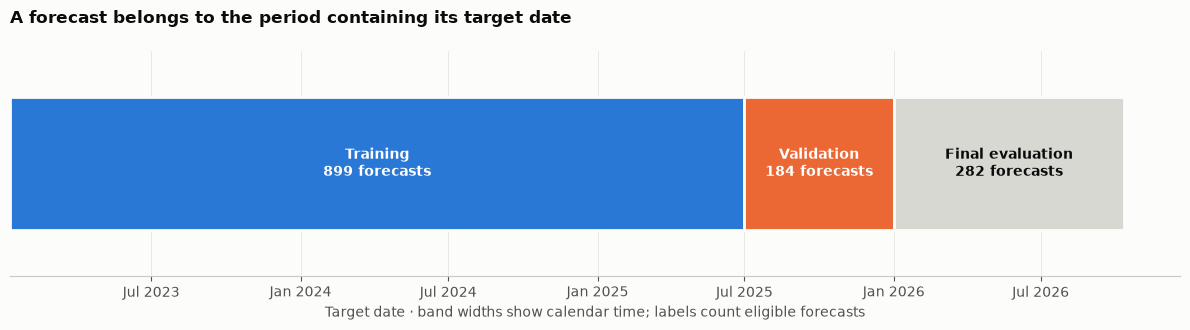

In [29]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 3.4))
for name, color in [("Training", BLUE), ("Validation", ORANGE), ("Final evaluation", "#d8d8d2")]:
    row = split_manifest.loc[name]
    left = mdates.date2num(pd.Timestamp(row["First target"]))
    right = mdates.date2num(pd.Timestamp(row["Last target"]) + pd.Timedelta(days=1))
    ax.barh(0, right - left, left=left, height=0.65, color=color, edgecolor=SURFACE, linewidth=2)
    label = f"{name}\n{row['Forecasts']:,} forecasts"
    ax.text((left + right) / 2, 0, label, ha="center", va="center",
            color="white" if name != "Final evaluation" else INK, fontsize=10, weight="bold")
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_yticks([])
ax.set_ylim(-0.55, 0.55)
ax.set_title("A forecast belongs to the period containing its target date", pad=20)
ax.set_xlabel("Target date · band widths show calendar time; labels count eligible forecasts")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
plt.show()

The aligned data gives **899 training, 184 validation and 282 final-evaluation forecasts**, totaling 1,365. The first training target is 8 January 2023; the last is 30 June 2025. Validation targets cover July–December 2025, and final targets cover 1 January–11 October 2026.

These are the counts I will use from now on, rather than the earlier plan's raw-calendar counts. Seven target dates at the beginning cannot be forecast with the required seven-day history inside this file, and missing target ratings exclude additional examples. Missing predictors remain eligible and will be handled by training-fitted preprocessing. The boundary checks confirm that a fitting label is available by the first held-out issue evening.

### 8.2 Making predictions during validation and testing

I evaluate **successive one-day-ahead forecasts**. At each evening $t$, the day's observed measurements become available, and I predict $a_{t+1}$. When tomorrow arrives, its observed rating may become history for the next forecast. Using that newly available history is legitimate: it matches how I would use the notebook in practice.

This is different from standing on 30 June and predicting all six months without observing anything new. I am not claiming to solve that multi-step problem.

For the validation baseline table, the mean is learned once from the training targets and remains fixed. The persistence and rolling-mean rules update their inputs as observations arrive. Later, a fitted ridge model will similarly keep its learned preprocessing and coefficients fixed within an evaluation block while receiving each evening's available inputs. In expanding-window CV, I refit at the beginning of each fold using only its earlier training rows.

I use no extra gap for this **one-day horizon and evening-after-observation timing**: the last training target may be observed on the first held-out issue date, but never after it. The assertions check this directly. Overlapping history windows are expected in real successive forecasts and do not by themselves require deleting neighboring days. A longer horizon in Section 11 will need the same label-availability check and, where necessary, a gap or date-based purging.

### 8.3 Three simple forecasts to compare against

A complicated model is only useful if it improves on a reasonable simple rule. I use three baselines:

| Baseline | Forecast issued at evening $t$ | What it tests |
|---|---|---|
| Training mean | $\widehat a_{t+1}=\overline a_{\mathrm{train\ targets}}$ | Is knowing the overall training level enough? |
| Persistence | $\widehat a_{t+1}=a_t$ | How far does “tomorrow will be like today” take me? |
| Seven-day mean | $\widehat a_{t+1}=\operatorname{mean}\{a_u:\ t-6\leq u\leq t,\ a_u\text{ observed}\}$ | Does smoothing the last week help? |

The seven-day baseline uses the same calendar window and observed-value mean as Section 6. It averages available observations without compressing time. All three rules predict the same held-out dates; I do not give persistence an easier subset by dropping days with a missing current rating.

**Missing-history policy, specified before looking at scores:** if today's rating is missing, persistence uses the most recent recorded rating on or before $t$. If the seven-day window is entirely missing, its mean falls back to that persistence prediction. If no rating has ever been observed by $t$, both fall back to the fitting partition's target mean. The initial CV training period precedes every scored forecast, so that last fallback is available at forecast time. Targets remain observed values throughout; they are never filled.

Forward filling here defines a baseline forecast. It does not change `clean`, the target series, or the feature matrix used by ridge. In each CV fold, the mean baseline and final fallback are recomputed from that fold's training targets only.

In [30]:
def baseline_predictions(fit_y, issue_features, daily_anxiety):
    '''Forecast the supplied issue dates, using only history through each date.'''
    if fit_y.empty or fit_y.isna().any():
        raise ValueError("Baseline fitting targets must be nonempty and observed")
    training_mean = float(fit_y.mean())
    last_observed = daily_anxiety.ffill().reindex(issue_features.index)
    persistence = issue_features["anxiety_today"].fillna(last_observed).fillna(training_mean)
    week_mean = issue_features["anxiety_mean_7d"].fillna(persistence)
    result = pd.DataFrame({"Training mean": training_mean,
                           "Persistence": persistence,
                           "Seven-day mean": week_mean}, index=issue_features.index)
    assert result.index.equals(issue_features.index)
    assert np.isfinite(result.to_numpy()).all()
    return result


validation_baselines = baseline_predictions(y_train, X_val, clean["anxiety_level"])
validation_history_audit = pd.Series({
    "Scored validation forecasts": len(X_val),
    "Missing current rating: persistence uses earlier history": int(X_val["anxiety_today"].isna().sum()),
    "Entire seven-day history missing: rolling mean uses fallback": int(X_val["anxiety_mean_7d"].isna().sum()),
}, name="forecasts")
display(validation_history_audit.to_frame())

# Check an actual missing-current-rating row against its available history.
missing_current_dates = X_features.index[X_features["anxiety_today"].isna()]
for issue in missing_current_dates:
    if issue >= X_val.index.min():
        continue  # this check uses earlier training-period examples, not final-period predictions
    expected = clean.loc[:issue, "anxiety_level"].dropna().iloc[-1]
    available_fit_y = y_train.loc[target_dates.loc[y_train.index] <= issue]
    actual = baseline_predictions(available_fit_y, X_features.loc[[issue]], clean["anxiety_level"])
    assert np.isclose(actual.loc[issue, "Persistence"], expected)

# At several issue times, removing later observations must leave forecasts unchanged.
for cutoff in [X_val.index[0], X_val.index[len(X_val) // 2], X_val.index[-1]]:
    prefix_predictions = baseline_predictions(y_train, X_val.loc[:cutoff], clean.loc[:cutoff, "anxiety_level"])
    pd.testing.assert_frame_equal(validation_baselines.loc[:cutoff], prefix_predictions)
assert np.allclose(validation_baselines["Seven-day mean"],
                   X_val["anxiety_mean_7d"].fillna(validation_baselines["Persistence"]))
print("Baseline alignment, missing-current fallback and future-prefix checks passed.")

,forecasts
Scored validation forecasts,184
Missing current rating: persistence uses earlier history,0
Entire seven-day history missing: rolling mean uses fallback,0


Baseline alignment, missing-current fallback and future-prefix checks passed.


### 8.4 How I measure prediction errors

For $m$ held-out forecasts, let $e_i=y_i-\widehat y_i$. I report

$$\mathrm{MAE}=\frac1m\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac1m\sum_i e_i^2},\qquad
R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\overline y_{\mathrm{eval}})^2}.$$

MAE is my main comparison: it tells me the average absolute miss in anxiety points. RMSE is also in anxiety points but gives larger misses more influence. Lower is better for both. $R^2$ can be negative; that means the squared errors exceed those from predicting the evaluated targets' own mean. That mean is a mathematical reference calculated after observing the outcomes, not the operational training-mean baseline above. If all evaluated targets are identical, I report $R^2$ as undefined.

Because recent anxiety is central to my question, I also report **MAE skill relative to persistence**:

$$\mathrm{Skill}_{\mathrm{pers}}=1-\frac{\mathrm{MAE}_{\mathrm{model}}}{\mathrm{MAE}_{\mathrm{persistence}}}.$$

A value of $0.10$ means 10% lower MAE than persistence on exactly the same dates; zero means a tie, and a negative value means worse. If persistence has zero error, this ratio is undefined. Here “persistence” includes the missing-history fallback specified above.

The code calculates absolute errors, squared errors and the $R^2$ sums directly with NumPy, then checks them against sklearn. This small scoring function makes the baseline comparison explicit. Section 9 will build the fuller `ModelEvaluator` around the same definitions, with plots as well as scores.

In [31]:
# Regression metrics implemented directly from their definitions.
def _metric_arrays(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    if actual.ndim != 1 or actual.shape != predicted.shape or not len(actual):
        raise ValueError("Expected aligned, nonempty one-dimensional arrays")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Metric inputs must be finite")
    return actual, predicted

def mean_absolute_error(actual, predicted):
    actual, predicted = _metric_arrays(actual, predicted)
    return float(np.mean(np.abs(actual-predicted)))

def root_mean_squared_error(actual, predicted):
    actual, predicted = _metric_arrays(actual, predicted)
    return float(np.sqrt(np.mean((actual-predicted)**2)))

def r2_score(actual, predicted):
    actual, predicted = _metric_arrays(actual, predicted)
    sse = float(np.sum((actual-predicted)**2))
    total = float(np.sum((actual-actual.mean())**2))
    if len(actual) < 2:
        return np.nan
    if total == 0:
        return 1. if sse == 0 else 0.  # sklearn's default force_finite convention
    return 1-sse/total

from sklearn import metrics as sklearn_metrics
for actual, predicted in [([1,3],[2,2]), ([0,2,7],[1,3,4])]:
    for metric in [mean_absolute_error, root_mean_squared_error, r2_score]:
        np.testing.assert_allclose(metric(actual,predicted),getattr(sklearn_metrics,metric.__name__)(actual,predicted))


def regression_scores(actual, predicted, persistence_prediction):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    reference = np.asarray(persistence_prediction, dtype=float)
    if actual.ndim != 1 or not (actual.shape == predicted.shape == reference.shape) or not len(actual):
        raise ValueError("Scores require aligned, nonempty one-dimensional arrays")
    if not all(np.isfinite(a).all() for a in (actual, predicted, reference)):
        raise ValueError("Scores require finite observations and predictions")
    mae = mean_absolute_error(actual, predicted)
    persistence_mae = mean_absolute_error(actual, reference)
    return {"MAE": mae, "RMSE": root_mean_squared_error(actual, predicted),
            "R2": r2_score(actual, predicted) if np.ptp(actual) > 0 else np.nan,
            "Skill vs persistence": 1 - mae / persistence_mae if persistence_mae > 0 else np.nan}


# A hand-calculated score check: MAE = RMSE = 1, R2 = 0, and skill = 0.5.
score_check = regression_scores([1, 3], [2, 2], [0, 0])
np.testing.assert_allclose(list(score_check.values()), [1., 1., 0., 0.5])
assert np.isnan(regression_scores([2, 2], [2, 2], [2, 2])["Skill vs persistence"])
assert np.isnan(regression_scores([2, 2], [2, 2], [1, 1])["R2"])

validation_baseline_scores = pd.DataFrame({
    name: regression_scores(y_val, prediction, validation_baselines["Persistence"])
    for name, prediction in validation_baselines.items()
}).T
display(validation_baseline_scores.round(4))
assert validation_baseline_scores.loc["Persistence", "Skill vs persistence"] == 0

,MAE,RMSE,R2,Skill vs persistence
Training mean,1.8153,2.1502,-0.1418,-0.3202
Persistence,1.3750,1.8043,0.1961,0.0000
Seven-day mean,1.5419,1.9536,0.0575,-0.1214


**Persistence is the strongest of these three validation baselines.** Its MAE is **1.375 anxiety points** over 184 forecasts, compared with **1.815** for the training mean and **1.542** for the seven-day mean. Its RMSE is **1.804**, so the larger misses remain relevant even though the average absolute miss is smaller.

The seven-day mean has skill **−0.121**, meaning about **12.1% higher MAE** than persistence here. Smoothing the recent ratings did not help on these dates. That does not establish that rolling means are useless as model inputs: ridge can combine them with today's rating rather than replacing it outright. The training-mean baseline's negative $R^2$ also illustrates why $R^2$ and improvement over an operational baseline are different comparisons.

There are no missing current ratings or entirely missing seven-day windows in this validation block, so the fallback rules do not change these particular scores. They are still specified and checked for gaps elsewhere in the series. I now have a concrete benchmark for later validation forecasts: they should improve on persistence's **1.375 MAE** on the same dates. This table contains no 2026 scores.

### 8.5 What happens if I shuffle the dates?

The autocorrelation in Section 5 made a random split questionable. Here I measure the difference rather than assume it must favor one method.

I compare **five-fold shuffled `KFold`** with **five-fold expanding-window `TimeSeriesSplit`**, using only the training partition. Both use the same 17 features, median imputation, standardization and ridge objective. Every fold fits a fresh pipeline, so neither imputation nor scaling is fitted before splitting. To keep the ridge objective consistent across different training sizes, I fix the mean-error convention at $\alpha=0.01$ and pass $n_{\mathrm{fold}}\alpha$ to scikit-learn. This is a diagnostic setting, not a tuned or selected value; Section 9 will tune ridge properly.

The shuffled method can fit on dates later than a held-out forecast. In this dataset, tomorrow's rating for a held-out row can even appear as current anxiety in a later training row. That is a concrete overlap between related observations across a random split. It does not mean ridge is directly handed that held-out target at prediction time, but the fitting procedure has used information that a real forecast could not have had.

The code constructs the fold indices directly. For $n$ rows and $F$ expanding folds, each validation block has $q=\lfloor n/(F+1)\rfloor$ rows; fitting endpoints are $n-Fq,n-(F-1)q,\ldots,n-q$. Shuffled K-fold permutes the row indices once and divides them into nearly equal blocks. I check every resulting index array against sklearn before using it.

Expanding-window validation uses only earlier training labels. I check **label availability relative to each forecast's issue time**, not just whether row numbers are sorted. This matters because a row's target is one day after its issue date.

There are two qualifications to the comparison. First, expanding folds have different training sizes from shuffled folds; matching alpha and evaluation dates does not make the experiments identical. Second, missing targets leave a few gaps between eligible rows. `TimeSeriesSplit` splits row counts, so its evaluation blocks contain equal numbers of forecasts but may span different numbers of calendar days. I print the dates and spans instead of claiming they cover identical durations.

In [32]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, TimeSeriesSplit


def expanding_window_splits(n_rows, n_splits=5):
    if n_splits < 2 or n_rows < n_splits+1:
        raise ValueError("Need at least two folds and enough rows")
    block = n_rows//(n_splits+1)
    first = n_rows-n_splits*block
    return [(np.arange(end), np.arange(end,end+block))
            for end in range(first,n_rows,block)]

def shuffled_kfold_splits(n_rows, n_splits=5, seed=156):
    if not 2 <= n_splits <= n_rows:
        raise ValueError("Need between two and n_rows folds")
    order = np.random.RandomState(seed).permutation(n_rows)
    folds = []
    for block in np.array_split(order,n_splits):
        validation = np.zeros(n_rows,dtype=bool)
        validation[block] = True
        folds.append((np.flatnonzero(~validation),np.flatnonzero(validation)))
    return folds

DIAGNOSTIC_ALPHA = 0.01  # fixed, mean-squared-error convention; not tuned
cv_splits = {
    "Shuffled KFold": shuffled_kfold_splits(len(X_train)),
    "Expanding TimeSeriesSplit": expanding_window_splits(len(X_train)),
}
for custom, reference in [(cv_splits["Shuffled KFold"], KFold(n_splits=5,shuffle=True,random_state=156).split(X_train)),
                          (cv_splits["Expanding TimeSeriesSplit"], TimeSeriesSplit(n_splits=5).split(X_train))]:
    for (fit, score), (ref_fit, ref_score) in zip(custom,reference):
        np.testing.assert_array_equal(fit,ref_fit)
        np.testing.assert_array_equal(score,ref_score)
cv_predictions = pd.DataFrame(index=X_train.index, columns=list(cv_splits), dtype=float)
cv_future_label_use = pd.DataFrame(False, index=X_train.index, columns=list(cv_splits))
cv_target_in_training_input = pd.DataFrame(False, index=X_train.index, columns=list(cv_splits))
temporal_baseline_oof = pd.DataFrame(index=X_train.index, columns=list(validation_baselines), dtype=float)
fold_records = []

for scheme, folds in cv_splits.items():
    for fold_number, (fit_positions, score_positions) in enumerate(folds, start=1):
        fit_x, score_x = X_train.iloc[fit_positions], X_train.iloc[score_positions]
        fit_y = y_train.iloc[fit_positions]
        fit_target_dates = target_dates.loc[fit_x.index]
        score_target_dates = target_dates.loc[score_x.index]
        latest_fit_label = fit_target_dates.max()

        if scheme == "Expanding TimeSeriesSplit":
            assert latest_fit_label <= score_x.index.min(), "A training label is not available yet"
            temporal_baseline_oof.loc[score_x.index] = baseline_predictions(
                fit_y, score_x, clean["anxiety_level"])

        diagnostic_model = Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=len(fit_x) * DIAGNOSTIC_ALPHA, solver="svd")),
        ])
        diagnostic_model.fit(fit_x, fit_y)
        cv_predictions.loc[score_x.index, scheme] = diagnostic_model.predict(score_x)
        cv_future_label_use.loc[score_x.index, scheme] = score_x.index < latest_fit_label
        cv_target_in_training_input.loc[score_x.index, scheme] = score_target_dates.isin(fit_x.index)
        fold_records.append({
            "Scheme": scheme, "Fold": fold_number, "Fit rows": len(fit_x), "Scored rows": len(score_x),
            "Last fit target": latest_fit_label.date(),
            "First scored target": score_target_dates.min().date(),
            "Last scored target": score_target_dates.max().date(),
            "Scored span (calendar days)": (score_target_dates.max() - score_target_dates.min()).days + 1,
        })

cv_fold_audit = pd.DataFrame(fold_records)
display(cv_fold_audit.loc[cv_fold_audit["Scheme"] == "Expanding TimeSeriesSplit"]
        .drop(columns="Scheme").set_index("Fold"))
assert not cv_future_label_use["Expanding TimeSeriesSplit"].any()
assert not cv_target_in_training_input["Expanding TimeSeriesSplit"].any()
assert cv_predictions["Shuffled KFold"].notna().all()
assert cv_predictions["Expanding TimeSeriesSplit"].notna().sum() == 5 * (len(X_train) // 6)
print("Ten independent pipelines fitted, all within the training period.")

,Fit rows,Scored rows,Last fit target,First scored target,Last scored target,Scored span (calendar days)
Fold,,,,,,
1,154,149,2023-06-10,2023-06-12,2023-11-10,152
2,303,149,2023-11-10,2023-11-11,2024-04-09,151
3,452,149,2024-04-09,2024-04-10,2024-09-05,149
4,601,149,2024-09-05,2024-09-06,2025-02-01,149
5,750,149,2025-02-01,2025-02-02,2025-06-30,149


Ten independent pipelines fitted, all within the training period.


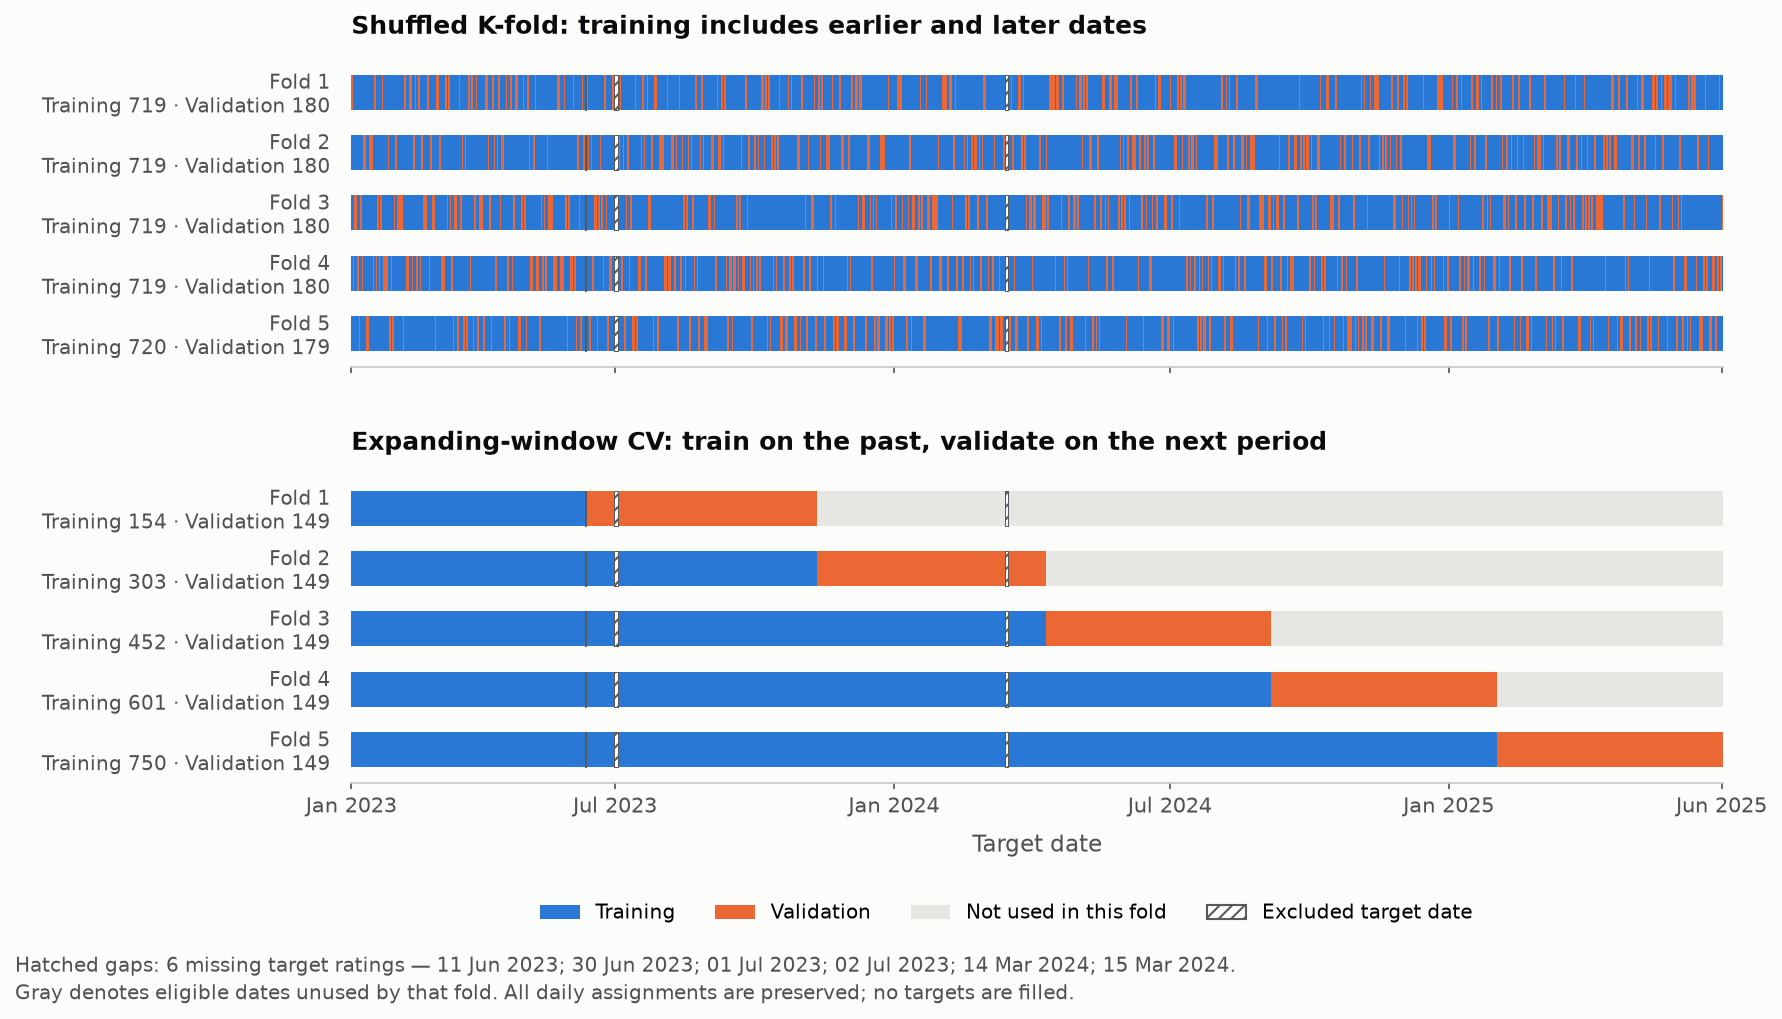

In [33]:
from matplotlib.patches import Patch

# Calendar cells retain their true width, including days with excluded targets.
plot_targets = pd.DatetimeIndex(target_dates.loc[X_train.index])
plot_calendar = pd.date_range(plot_targets.min(), plot_targets.max(), freq="D")
calendar_positions = plot_calendar.get_indexer(plot_targets)
date_edges = mdates.date2num(plot_calendar.append(
    pd.DatetimeIndex([plot_calendar[-1] + pd.Timedelta(days=1)])))
excluded_dates = plot_calendar.difference(plot_targets)
assert clean["anxiety_level"].reindex(excluded_dates).isna().all()
assert len(plot_calendar) == len(X_train) + len(excluded_dates)

# Merge only adjacent calendar cells with identical assignments. This removes
# drawing seams without aggregating dates or changing any fold membership.
def calendar_runs(states, selected_state):
    boundaries = np.r_[0, np.flatnonzero(np.diff(states) != 0) + 1, len(states)]
    return [(date_edges[start], date_edges[end] - date_edges[start])
            for start, end in zip(boundaries[:-1], boundaries[1:])
            if states[start] == selected_state]

not_used_color = "#e6e6e2"
fig, axes = plt.subplots(2, 1, figsize=(11.8, 6.8), dpi=150, sharex=True)
panel_titles = [
    "Shuffled K-fold: training includes earlier and later dates",
    "Expanding-window CV: train on the past, validate on the next period",
]
for ax, (scheme, folds), title in zip(axes, cv_splits.items(), panel_titles):
    row_labels = []
    for fold, (fit_positions, score_positions) in enumerate(folds, start=1):
        # 0 = eligible but unused; 1 = training; 2 = validation; 3 = excluded target.
        states = np.zeros(len(plot_calendar), dtype=int)
        states[plot_calendar.get_indexer(excluded_dates)] = 3
        states[calendar_positions[fit_positions]] = 1
        states[calendar_positions[score_positions]] = 2
        assert np.count_nonzero(states == 1) == len(fit_positions)
        assert np.count_nonzero(states == 2) == len(score_positions)
        assert np.count_nonzero(states == 3) == len(excluded_dates)
        for state, color in [(0, not_used_color), (1, BLUE), (2, ORANGE)]:
            ax.broken_barh(calendar_runs(states, state), (fold - 0.29, 0.58),
                           facecolors=color, edgecolors="none", linewidths=0,
                           antialiased=False)
        # Genuine gaps remain visible; they are not painted as training or unused.
        ax.broken_barh(calendar_runs(states, 3), (fold - 0.29, 0.58),
                       facecolors="white", edgecolors="#595959", linewidths=0.35,
                       hatch="////", antialiased=False)
        row_labels.append(f"Fold {fold}\nTraining {len(fit_positions):,} · Validation {len(score_positions):,}")
    ax.set_yticks(range(1, 6), row_labels)
    ax.set_ylim(5.55, 0.45)  # Fold 1 at the top
    ax.set_xlim(date_edges[0], date_edges[-1])
    ax.set_title(title, fontsize=12, pad=12)
    ax.tick_params(axis="y", labelsize=9.5, length=0, pad=10)
    ax.tick_params(axis="x", labelsize=10, length=3)
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].xaxis_date()
half_year_ticks = pd.date_range(plot_calendar[0].normalize().replace(day=1),
                               plot_calendar[-1], freq="MS")
half_year_ticks = half_year_ticks[(half_year_ticks.month.isin([1, 7]))
                                 & (half_year_ticks > plot_calendar[0])]
date_ticks = pd.DatetimeIndex([plot_calendar[0], *half_year_ticks, plot_calendar[-1]])
axes[-1].set_xticks(mdates.date2num(date_ticks), date_ticks.strftime("%b %Y"))
axes[-1].set_xlabel("Target date", fontsize=11, labelpad=8)
fig.legend(handles=[Patch(facecolor=BLUE, label="Training"),
                    Patch(facecolor=ORANGE, label="Validation"),
                    Patch(facecolor=not_used_color, label="Not used in this fold"),
                    Patch(facecolor="white", edgecolor="#595959", hatch="////", label="Excluded target date")],
           loc="lower center", bbox_to_anchor=(0.58, 0.075), ncol=4, fontsize=9.5)
excluded_label = "; ".join(day.strftime("%d %b %Y") for day in excluded_dates)
fig.text(0.02, 0.045,
         f"Hatched gaps: {len(excluded_dates)} missing target ratings — {excluded_label}.",
         fontsize=9.5, color=INK_2)
fig.text(0.02, 0.018,
         "Gray denotes eligible dates unused by that fold. All daily assignments are preserved; no targets are filled.",
         fontsize=9.5, color=INK_2)
fig.subplots_adjust(left=0.21, right=0.985, top=0.94, bottom=0.23, hspace=0.35)
plt.show()

**Reading the CV diagram.** Both panels use only the **899 training-partition forecasts**, with target dates from **8 January 2023 to 30 June 2025**. Orange means validation **inside a CV fold**; it is separate from the **184-forecast July–December 2025 validation partition** shown in Section 8.1. Gray marks eligible dates unused by that particular fold, not the final 2026 evaluation period.

Each row's counts come from the actual indices used to fit and score that fold. The six hatched dates are missing **target ratings**, so they are excluded from every fold. Missing predictors do not create these gaps: Section 6 retains those rows for training-fitted imputation. Bar widths represent calendar time, so equal validation sample counts can span slightly different numbers of days.

The shuffled panel's blue/orange interleaving shows that fitting can use dates later than a scored forecast. The expanding panel preserves the direction of forecasting. The plot shows **which observations are used**, not how accurate the predictions are or how much shuffling changes the score; that is measured below. Preprocessing is fitted separately within every fold, as required by Section 7.

### 8.6 Comparing models on the same dates

Shuffled CV produces one out-of-fold prediction for every training-period row. Expanding CV needs an initial fitting period, so it cannot score the earliest rows. Comparing their unfiltered averages would mix different evaluation dates.

I therefore retain **only dates with predictions from both methods**, then compute pooled errors on those same targets. The temporal baselines below also use those dates and each fold's own training mean. A pooled MAE is the mean absolute error across all these forecasts, not an unweighted average of differently sized folds. Fold-to-fold variation is not an independent-sample confidence interval for this serially dependent dataset.

I also report two timing diagnostics on those common dates: whether the fit used any label observed after the forecast's issue evening, and whether the held-out target date was included as an issue date in the training inputs. The second check identifies when that target rating is present in a later row's current-anxiety feature. These checks explain the protocol problem even if the score difference happens to be small or reversed.

In [34]:
common_cv_dates = cv_predictions.index[cv_predictions.notna().all(axis=1)]
common_y = y_train.loc[common_cv_dates]
common_persistence = temporal_baseline_oof.loc[common_cv_dates, "Persistence"]
assert temporal_baseline_oof.loc[common_cv_dates].notna().all().all()

c3_scorecard = pd.DataFrame({
    scheme: regression_scores(common_y, cv_predictions.loc[common_cv_dates, scheme], common_persistence)
    for scheme in cv_splits
}).T
print("Ridge scores on common dates (same temporal persistence reference for skill)")
display(c3_scorecard.round(4))

timing_diagnostics = pd.DataFrame({
    "Fit used a label from after issue time (%)": cv_future_label_use.loc[common_cv_dates].mean() * 100,
    "Held-out target occurs in later training inputs (%)": cv_target_in_training_input.loc[common_cv_dates].mean() * 100,
})
print("Timing diagnostics on those same dates")
display(timing_diagnostics.round(1))

training_cv_scores = pd.DataFrame({
    name: regression_scores(common_y, temporal_baseline_oof.loc[common_cv_dates, name], common_persistence)
    for name in temporal_baseline_oof
}).T
training_cv_scores.loc["Ridge (fixed diagnostic alpha)"] = c3_scorecard.loc["Expanding TimeSeriesSplit"]
print("Training-only expanding CV: baselines and fixed-alpha ridge")
display(training_cv_scores.round(4))
print(f"Common evaluation: {len(common_cv_dates):,} forecasts, target dates "
      f"{target_dates.loc[common_cv_dates].min().date()} to {target_dates.loc[common_cv_dates].max().date()}.")
mae_difference = c3_scorecard.loc["Expanding TimeSeriesSplit", "MAE"] - c3_scorecard.loc["Shuffled KFold", "MAE"]
print(f"Temporal MAE minus shuffled MAE: {mae_difference:+.4f} anxiety points.")
print("Positive means shuffled CV looks better; negative means temporal CV looks better.")

Ridge scores on common dates (same temporal persistence reference for skill)


,MAE,RMSE,R2,Skill vs persistence
Shuffled KFold,1.3803,1.6937,0.3172,0.090
Expanding TimeSeriesSplit,1.3984,1.7177,0.2978,0.078


Timing diagnostics on those same dates


,Fit used a label from after issue time (%),Held-out target occurs in later training inputs (%)
Shuffled KFold,99.9,79.1
Expanding TimeSeriesSplit,0.0,0.0


Training-only expanding CV: baselines and fixed-alpha ridge


,MAE,RMSE,R2,Skill vs persistence
Training mean,1.6842,2.0779,-0.0276,-0.1104
Persistence,1.5168,1.9241,0.1189,0.0000
Seven-day mean,1.5785,1.9829,0.0642,-0.0407
Ridge (fixed diagnostic alpha),1.3984,1.7177,0.2978,0.0780


Common evaluation: 745 forecasts, target dates 2023-06-12 to 2025-06-30.
Temporal MAE minus shuffled MAE: +0.0181 anxiety points.
Positive means shuffled CV looks better; negative means temporal CV looks better.


**The shuffled result looks slightly better, but the measured difference is small.** On the same **745 forecasts**, with target dates from 12 June 2023 to 30 June 2025, shuffled CV gives ridge MAE **1.3803** and expanding CV gives **1.3984**. The gap is **0.0181 anxiety points**, about 1.3% of the temporal MAE. I should report that modest difference rather than turn the autocorrelation plot into a claim of dramatic score inflation.

The timing checks show why the shuffled protocol is unsuitable for my forecasting question regardless of the small score gap. For **99.9%** of these scored forecasts, its fit used at least one label observed after the issue evening. For **79.1%**, the held-out target rating also appears as current anxiety in a later training input row. Both rates are **0%** for the expanding folds. Keeping the scaler inside a pipeline prevents preprocessing leakage, but it cannot repair a split that lets the fitting process use the future.

The gap is not a clean estimate of the effect of autocorrelation alone. The methods use different training sizes and compositions, and conditions may change over time. Expanding fits grow from **154 to 750 rows**, whereas shuffled fits use **719 or 720**. Matching the scored dates and the mean-error alpha convention controls two differences, but not all of them. These five folds also do not establish statistical significance or guarantee the same gap on another period or model.

On the valid temporal CV predictions, persistence has MAE **1.5168**, the seven-day mean **1.5785**, and the training mean **1.6842**. Ridge's **1.3984** corresponds to **7.8% lower MAE than persistence** on those same forecasts. This is an encouraging development result for one fixed diagnostic alpha. It does not yet show that habits add value beyond anxiety history; that requires the feature ablation in Section 12. It is also not ridge's validation or final-evaluation score. In particular, I cannot compare this training-CV MAE directly with the **1.375** validation persistence MAE, because those refer to different dates.

The conclusion I will act on is methodological: use forward-in-time validation for model choices, and keep persistence in every comparable scorecard. I will tune ridge in Section 9 rather than treating this diagnostic fit as the chosen model.

### 8.7 Rules for the model comparisons

I now have a fixed chronological split and explicit baseline rules. Preprocessing and coefficient fitting happen inside the training portion of each comparison. Held-out history is used only after it becomes available, and the 2026 partition has received no model predictions or scores in this section.

I will use expanding-window CV for model development because it matches the direction of the actual forecasting task. The shuffled result remains a diagnostic; it is not a score I will use to claim future performance. The baseline results set a concrete bar: ridge must justify its added complexity on comparable dates, especially against persistence.

**Next, Section 9:** tune ridge with a training-only time-series CV pipeline, evaluate the chosen training fit on validation, and introduce `ModelEvaluator`. This notebook ends with the development comparisons; it does not report model scores on the reserved 2026 period. The earlier descriptive exploration of 2026 remains a limitation for any future evaluation.

<a id="section-9"></a>

## 9. Fitting and tuning ridge with scikit-learn

Section 8 gave me an evaluation procedure and a useful benchmark. Now I can ask whether a properly tuned ridge model improves on it. I will choose the penalty using only the training period, fit the chosen pipeline on all 899 training examples, and then examine its forecasts for July–December 2025. The 2026 rows remain outside this work.

Here is what each stage learns. The coefficients $w$ and intercept $b$ are **model parameters**, learned by minimizing the ridge objective on fitting rows. Alpha is a **hyperparameter**, chosen by comparing forecasts for later rows inside the training period. The separate July–December block then checks the resulting choice on another period. These are different jobs, even though both kinds of held-out rows are sometimes called “validation.”

| Stage in this section | Rows used | What I am allowed to learn |
|---|---|---|
| Fit one CV pipeline | Earlier part of the 899-row training partition | Medians, scales, weights and intercept for that fold |
| Score that CV pipeline | Its next 149 eligible forecasts | Forecast errors used to compare alpha values |
| Refit after choosing alpha | All 899 training forecasts | One final training-fitted pipeline for this comparison |
| Check the chosen fit | 184 July–December 2025 forecasts | Development performance and error patterns |

The 745 internal CV forecasts belong to the training partition; they are not an additional dataset outside it. The first 154 training examples supply the initial fitting period and receive no expanding-CV prediction. I do not replace those absent predictions with fitted values, because that would mix training error with held-out error.

### 9.1 Preparing the data separately for each fit

The order is **median imputation → standardization → ridge**. Each CV fold gets a fresh pipeline. Its medians, feature means, feature scales and coefficients are learned from that fold's fitting rows. Its validation rows are only transformed and predicted.

I keep Section 7's objective, $J=\mathrm{MSE}+\alpha\lVert w\rVert^2$. Since scikit-learn minimizes a squared-error **sum**, the pipeline factory converts this to `Ridge(alpha=n_fit * alpha)`. This conversion uses the number of rows in that particular fit. A single fixed scikit-learn alpha across expanding folds would instead change the strength of the penalty relative to the mean-error term.

`keep_empty_features=True` keeps the feature layout stable if an early fitting period has an entirely missing column; scikit-learn then supplies zero for that column before scaling. The missingness and coverage columns from Section 6 remain in the input. This is a numerical fallback, not a claim that an unobserved measurement equals zero.

#### What gets learned from the training data

For fold $f$ and feature $j$, let $m_{fj}$ be the median of the observed fitting values. An absent predictor is replaced with this fitted median. After imputation, the scaler learns the fitting mean $\mu_{fj}$ and standard deviation $s_{fj}$, using divisor $n_f$ (`ddof=0`) as in `StandardScaler`. It transforms a value $v_{ij}$ into

$$z_{ij}^{(f)}=\frac{\operatorname{impute}(v_{ij};m_{fj})-\mu_{fj}}{s_{fj}}.$$

A constant feature uses scale 1. The exact same $m_{fj},\mu_{fj},s_{fj}$ are used for that fold's validation rows. A future observation can therefore be far from the fitting mean; I do not recenter the validation period to make it resemble training. Targets are never imputed or standardized, so every forecast remains in anxiety points.

For example, a fitting median for sleep quality is a rule learned from earlier observations, not an estimate recomputed from the future block. This distinction is why fitting one scaler on all 899 rows **before** CV would be wrong: the early fold would already know something about the distribution of its later validation inputs. Putting preprocessing inside the fold prevents that information from entering the fit. The causal feature construction in Section 6 and the chronological split in Section 8 address different parts of the same timing requirement.

#### How I choose the penalty

Write $F_f$ for the fitting indices and $V_f$ for the validation indices in fold $f$. For a candidate alpha, that fold solves

$$\big(\widehat w_f(\alpha),\widehat b_f(\alpha)\big)
=\operatorname*{arg\,min}_{w,b}\left\{
\frac1{|F_f|}\sum_{i\in F_f}\big[y_i-((z_i^{(f)})^\top w+b)\big]^2+\alpha\lVert w\rVert^2\right\}.$$

Its predictions on $V_f$ are out-of-fold predictions: those targets did not fit that pipeline. I join the five validation blocks and select the alpha with the smallest pooled absolute error:

$$\mathrm{CV\ MAE}(\alpha)=\frac1{745}\sum_{f=1}^{5}\sum_{i\in V_f}
\left|y_i-(z_i^{(f)})^\top\widehat w_f(\alpha)-\widehat b_f(\alpha)\right|,
\qquad \alpha^*=\operatorname*{arg\,min}_{\alpha\in\mathcal A}\mathrm{CV\ MAE}(\alpha).$$

Here $\mathcal A$ is the grid of 17 positive candidates from $10^{-6}$ to $10^2$. Logarithmic spacing lets me explore orders of magnitude rather than spending most candidates on similar large values. There are **17 × 5 = 85 fold fits**, followed later by one refit on the complete training partition. All candidates are scored on exactly the same 745 targets.

The training objective still uses squared error; the selection rule uses MAE because an average absolute miss in rating points is easy to interpret for my question. I am choosing among squared-error-trained models, not claiming to have trained ridge by minimizing absolute error. RMSE remains a secondary diagnostic rather than a second selection rule I switch to after seeing the results.

#### How the code works

`make_ridge_pipeline` creates an unfitted pipeline. `pipeline.fit` learns its preprocessing and regression parameters from `fit_x` and the matching targets. `pipeline.predict(score_x)` applies those already fitted transformations and returns forecasts without learning from the scored outcomes. The `oof` Series stores them against their issue dates, so the target comparisons stay aligned.

The conversion `n_fit * alpha` happens separately in each fit. For instance, the first fold has 154 fitting rows, while the full refit has 899; they should not receive the same scikit-learn alpha if I want to preserve the mean-error objective. The final assertion also checks that the selected candidate is inside the grid. If the minimum were at an endpoint, I would extend the grid using training CV before examining the separate validation score.

In [35]:
def make_ridge_pipeline(alpha, n_fit):
    '''alpha uses the mean-squared-error convention throughout this notebook.'''
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=n_fit * alpha, fit_intercept=True, solver="svd")),
    ])


# A broad logarithmic grid, specified before examining validation performance.
alpha_grid = np.logspace(-6, 2, 17)
ridge_tuning_rows, ridge_candidate_oof, ridge_fold_maes = [], {}, {}
for alpha in alpha_grid:
    oof = pd.Series(np.nan, index=X_train.index, dtype=float)
    fold_maes = []
    for fit_positions, score_positions in cv_splits["Expanding TimeSeriesSplit"]:
        fit_x, score_x = X_train.iloc[fit_positions], X_train.iloc[score_positions]
        assert target_dates.loc[fit_x.index].max() <= score_x.index.min()
        pipeline = make_ridge_pipeline(alpha, len(fit_x))
        pipeline.fit(fit_x, y_train.loc[fit_x.index])
        predictions = pipeline.predict(score_x)
        oof.loc[score_x.index] = predictions
        fold_maes.append(mean_absolute_error(y_train.loc[score_x.index], predictions))
    evaluated = oof.notna()
    assert oof.index[evaluated].equals(common_cv_dates)
    ridge_tuning_rows.append({"alpha (mean-error convention)": alpha,
                             "Pooled CV MAE": mean_absolute_error(y_train.loc[evaluated], oof.loc[evaluated]),
                             "Pooled CV RMSE": root_mean_squared_error(y_train.loc[evaluated], oof.loc[evaluated])})
    ridge_candidate_oof[float(alpha)] = oof
    ridge_fold_maes[float(alpha)] = fold_maes

ridge_tuning = pd.DataFrame(ridge_tuning_rows).set_index("alpha (mean-error convention)")
selected_alpha = float(ridge_tuning["Pooled CV MAE"].idxmin())
ridge_selected_oof = ridge_candidate_oof[selected_alpha].loc[common_cv_dates]
display(ridge_tuning.round(5))
print(f"Selected alpha: {selected_alpha:g} (mean-error convention)")
print(f"Full-training sklearn alpha: {len(X_train) * selected_alpha:g}")
print("Selection used training-only expanding CV, not July–December validation or 2026.")
assert selected_alpha not in (alpha_grid[0], alpha_grid[-1]), "Extend the grid before inspecting validation"

,Pooled CV MAE,Pooled CV RMSE
alpha (mean-error convention),,
0.000001,1.39903,1.72016
0.000003,1.39903,1.72016
0.000010,1.39903,1.72016
0.000032,1.39903,1.72015
0.000100,1.39902,1.72013
0.000316,1.39900,1.72007
0.001000,1.39895,1.71988
0.003162,1.39877,1.71929
0.010000,1.39840,1.71765


Selected alpha: 0.0316228 (mean-error convention)
Full-training sklearn alpha: 28.4289
Selection used training-only expanding CV, not July–December validation or 2026.


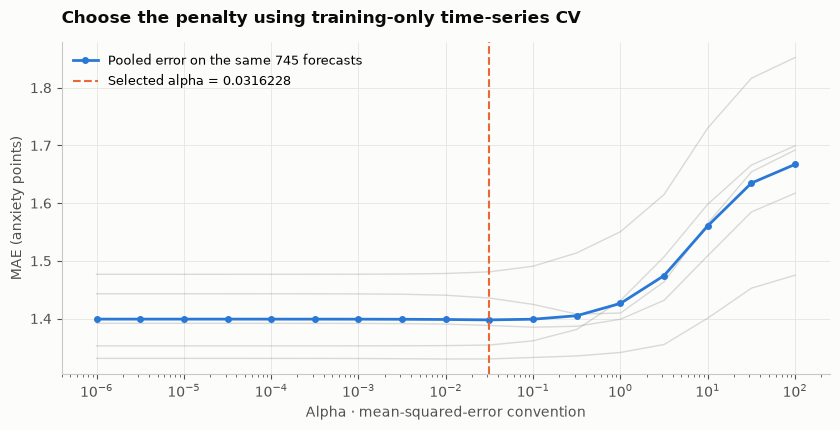

In [36]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
fold_mae_matrix = np.array([ridge_fold_maes[float(a)] for a in alpha_grid])
for fold in range(fold_mae_matrix.shape[1]):
    ax.plot(alpha_grid, fold_mae_matrix[:, fold], color=MUTED, alpha=0.3, linewidth=1)
ax.plot(alpha_grid, ridge_tuning["Pooled CV MAE"], color=BLUE, marker="o", markersize=4,
        label="Pooled error on the same 745 forecasts")
ax.axvline(selected_alpha, color=ORANGE, linestyle="--", linewidth=1.5,
           label=f"Selected alpha = {selected_alpha:g}")
ax.set_xscale("log")
ax.set_xlabel("Alpha · mean-squared-error convention")
ax.set_ylabel("MAE (anxiety points)")
ax.set_title("Choose the penalty using training-only time-series CV", pad=14)
ax.legend(loc="best", fontsize=9)
fig.tight_layout()
plt.show()

The lowest pooled CV MAE is **1.39774**, at **$\alpha=0.0316228$** in my mean-error convention. Fitting all 899 training rows therefore uses **$\alpha_{\mathrm{sklearn}}=28.4289$**. These are two conventions for the same penalty, not two separately selected settings.

The minimum is shallow. Near-zero alpha gives MAE about **1.39903**, only **0.00129 points** worse, while very strong regularization eventually raises it to **1.66723**. The data does not identify a sharply optimal penalty here; the grid gives me a reproducible development choice. The faint gray curves are the five individual folds, whose changing periods and sample sizes explain why their levels differ. They are not confidence bands.

I selected on MAE, not RMSE: the RMSE column need not have its minimum at the same alpha. This is also a selected CV score, so I will not treat its minimum as an unbiased estimate of the final model's error. The next step is the separate 2025 validation check, without changing alpha in response to that score.

### 9.2 Writing a function to compare prediction errors

I need the same scoring rules for ridge, the baselines and the different feature sets. `ModelEvaluator` checks that every prediction is aligned with the same observed targets, then uses Section 8's metric definitions. I index the evaluation table by **target date**, so a point labeled 1 July compares the forecast issued on 30 June with the rating observed on 1 July.

There are three complementary views. The time plot shows when forecasts follow or miss changes. Grouping errors by **observed anxiety** shows which outcome levels are underpredicted or overpredicted; bias here means $\widehat y-y$, so a negative value means underprediction. The calibration check instead groups by **predicted anxiety** and asks whether the observed average matches the forecast average. These two groupings answer different questions.

For the regression calibration check I fix bins at 2, 4, 6 and 8, including open-ended outer bins so no raw prediction is dropped. Within bin $B$, I plot

$$\left(\frac{1}{|B|}\sum_{i\in B}\widehat y_i,\quad
\frac{1}{|B|}\sum_{i\in B}y_i\right).$$

Points near the diagonal indicate agreement of bin averages. This is a descriptive check for a point forecast, not probability calibration or an uncertainty interval. A sparse bin is weak evidence; empty bins stay visible in the table rather than being treated as successful calibration.

#### What the different error scores tell me

For an observed rating level $\ell$, define $A_\ell=\{i:y_i=\ell\}$. The error-by-level table reports

$$\mathrm{MAE}_\ell=\frac1{|A_\ell|}\sum_{i\in A_\ell}|\widehat y_i-y_i|,
\qquad \mathrm{Bias}_\ell=\frac1{|A_\ell|}\sum_{i\in A_\ell}(\widehat y_i-y_i).$$

Absolute errors measure the size of the misses. Signed bias measures their direction and can hide cancellation: errors of $+2$ and $-2$ have mean bias zero but MAE 2. The plotted bars show signed bias; the accompanying table provides MAE and the number of observations. This use of “bias” means mean signed error, not the theoretical estimator bias in the bias–variance decomposition from Section 7.

In the calibration plot, the sets are instead defined by the **forecast**, such as $B=\{i:2\leq\widehat y_i<4\}$. A point below the diagonal means the forecast-bin average exceeds the observed average: overprediction in that bin. A point above the diagonal means underprediction. A reassuring bin average does not ensure small errors for its individual days, and the bin boundaries can affect the picture.

`metrics()` summarizes every model with the same formulas and persistence reference. `errors_by_level()` and `calibration_table()` expose the underlying counts and averages rather than leaving the plots as decoration. The date checks in the constructor matter too: a mathematically correct MAE on forecasts shifted by a day would answer the wrong question.

In [37]:
class ModelEvaluator:
    def __init__(self, actual, predictions, persistence):
        if not isinstance(actual, pd.Series) or not isinstance(predictions, pd.DataFrame):
            raise TypeError("Use an observed-target Series and a prediction DataFrame")
        if not actual.index.equals(predictions.index) or not actual.index.equals(persistence.index):
            raise ValueError("Actual, model and persistence dates must match exactly")
        if actual.empty or not actual.index.is_unique or not actual.index.is_monotonic_increasing:
            raise ValueError("Evaluation dates must be nonempty, unique and ordered")
        if not np.isfinite(np.column_stack([actual, predictions, persistence])).all():
            raise ValueError("Evaluation values must be finite")
        self.actual = actual.copy()
        self.predictions = predictions.copy()
        self.persistence = persistence.copy()

    def metrics(self):
        return pd.DataFrame({name: regression_scores(self.actual, values, self.persistence)
                             for name, values in self.predictions.items()}).T

    def errors_by_level(self, model):
        rows = pd.DataFrame({"Observed anxiety": self.actual,
                             "Absolute error": (self.predictions[model] - self.actual).abs(),
                             "Bias": self.predictions[model] - self.actual})
        return rows.groupby("Observed anxiety").agg(
            n=("Bias", "size"), MAE=("Absolute error", "mean"), Bias=("Bias", "mean"))

    def calibration_table(self, model):
        rows = pd.DataFrame({"Prediction": self.predictions[model], "Observed": self.actual})
        rows["Forecast bin"] = pd.cut(rows["Prediction"], [-np.inf, 2, 4, 6, 8, np.inf],
                                       labels=["<2", "2–<4", "4–<6", "6–<8", "≥8"], right=False)
        table = rows.groupby("Forecast bin", observed=False).agg(
            n=("Observed", "size"), Mean_prediction=("Prediction", "mean"),
            Mean_observed=("Observed", "mean"))
        table["Bias"] = table["Mean_prediction"] - table["Mean_observed"]
        return table

    def plot_over_time(self, model):
        fig, ax = plt.subplots(figsize=(10, 4.2))
        ax.plot(self.actual.index, self.actual, color=INK_2, alpha=0.65, linewidth=1.2, label="Observed")
        ax.plot(self.actual.index, self.persistence, color=ORANGE, alpha=0.6, linewidth=1,
                linestyle="--", label="Persistence")
        ax.plot(self.actual.index, self.predictions[model], color=BLUE, linewidth=1.5, label=model)
        ax.set_ylim(-0.4, 10.4)
        ax.set_xlim(self.actual.index.min(), self.actual.index.max())
        ax.set_ylabel("Anxiety (0–10 self-rating)")
        ax.set_xlabel("Target date")
        ax.set_title("Validation: one-day-ahead forecasts with a fixed training fit", pad=14)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.legend(loc="upper left", ncol=3)
        fig.tight_layout()
        return fig

    def plot_errors_by_level(self, model):
        table = self.errors_by_level(model)
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        colors = [ORANGE if v < 0 else BLUE for v in table["Bias"]]
        ax.bar(table.index, table["Bias"], color=colors, width=0.65)
        for level, row in table.iterrows():
            ax.annotate(f"n={int(row['n'])}", (level, row["Bias"]),
                        xytext=(0, -15 if row["Bias"] < 0 else 6), textcoords="offset points",
                        ha="center", fontsize=9)
        ax.axhline(0, color=INK_2, linewidth=1)
        ax.set_xticks(range(11))
        for absent_level in set(range(11)).difference(table.index):
            ax.text(absent_level, 0.2, "n=0", ha="center", fontsize=9, color=MUTED)
        ax.set_xlim(-0.7, 10.7)
        ax.margins(y=0.22)
        ax.set_xlabel("Observed anxiety level")
        ax.set_ylabel("Mean prediction − observation (points)")
        ax.set_title("Where does ridge overpredict or underpredict?", pad=14)
        fig.tight_layout()
        return fig

    def plot_calibration(self, model):
        table = self.calibration_table(model)
        occupied = table.loc[table["n"] > 0]
        fig, ax = plt.subplots(figsize=(6.5, 4.8))
        ax.plot([0, 10], [0, 10], color=MUTED, linestyle="--", linewidth=1, label="Equal bin averages")
        ax.scatter(occupied["Mean_prediction"], occupied["Mean_observed"],
                   s=35 + 10 * np.sqrt(occupied["n"]), color=BLUE, zorder=3)
        for i, (_, row) in enumerate(occupied.iterrows()):
            ax.annotate(f"n={int(row['n'])}", (row["Mean_prediction"], row["Mean_observed"]),
                        xytext=(8, 8 if i % 2 == 0 else -15), textcoords="offset points", fontsize=10)
        low = min(0, occupied["Mean_prediction"].min()) - 0.3
        high = max(10, occupied["Mean_prediction"].max()) + 0.3
        ax.set_xlim(low, high)
        ax.set_ylim(-0.3, 10.3)
        ax.set_xlabel("Mean prediction within forecast bin")
        ax.set_ylabel("Mean observed anxiety within forecast bin")
        ax.set_title("Regression calibration check on validation", pad=14)
        ax.legend(loc="upper left", fontsize=9)
        fig.tight_layout()
        return fig

### 9.3 Training ridge and predicting the validation days

The tuning decision is now fixed. I refit a fresh pipeline on all training rows, then call only `predict` on validation. The held-out observations can enter later forecasts as available history, as Section 8 explained; they do not refit the imputer, scaler or ridge coefficients within this block.

The CV score used to choose alpha is a development score and benefits from that selection. The separate validation block is a later-period check of the chosen training fit. It is also development data for subsequent window and feature comparisons, so I will not present it as the final untouched performance estimate.

The final preprocessing checks have a concrete purpose. The imputer's stored medians should match the training medians, and the scaler's stored means should match the **imputed training matrix**, not the raw matrix with missing cells. These checks support what the pipeline structure already enforces. `predict(X_val)` then produces one output for each issue date; I relabel the evaluation table by its matching target date without moving any values between rows.

When reading the scorecard, I will distinguish an absolute gain from a relative one. If persistence has MAE $M_p$ and ridge has $M_r$, the average gain is $M_p-M_r$ anxiety points, while skill is $(M_p-M_r)/M_p$. Neither number means every day improved. Similarly, $R^2$ compares squared errors with the validation outcomes' own mean; it is not the percentage of my anxiety caused by the inputs or the percentage of forecasts that were “correct.” This is regression, so I am measuring the size of numeric errors rather than classification accuracy.

In [38]:
ridge_pipeline = make_ridge_pipeline(selected_alpha, len(X_train))
ridge_pipeline.fit(X_train, y_train)
ridge_validation_predictions = pd.Series(ridge_pipeline.predict(X_val), index=X_val.index, name="Ridge")

# Verify that the fitted preprocessing contains training-only statistics.
imputer = ridge_pipeline.named_steps["imputer"]
scaler = ridge_pipeline.named_steps["scaler"]
np.testing.assert_allclose(imputer.statistics_, X_train.median().to_numpy())
imputed_training = imputer.transform(X_train)
np.testing.assert_allclose(scaler.mean_, imputed_training.mean(axis=0))
assert ridge_pipeline.named_steps["ridge"].alpha == len(X_train) * selected_alpha
assert imputed_training.shape == X_train.shape

validation_target_index = pd.DatetimeIndex(target_dates.loc[X_val.index], name="target_date")
validation_actual = pd.Series(y_val.to_numpy(), index=validation_target_index, name="Observed")
validation_prediction_table = validation_baselines.copy()
validation_prediction_table["Ridge"] = ridge_validation_predictions
validation_prediction_table.index = validation_target_index
validation_evaluator = ModelEvaluator(validation_actual, validation_prediction_table,
                                      validation_prediction_table["Persistence"])
display(validation_evaluator.metrics().round(4))
print(f"Raw ridge predictions outside 0–10: {int(((ridge_validation_predictions < 0) | (ridge_validation_predictions > 10)).sum())}")
print("Raw forecasts are scored without clipping. No 2026 predictions have been made.")

,MAE,RMSE,R2,Skill vs persistence
Training mean,1.8153,2.1502,-0.1418,-0.3202
Persistence,1.3750,1.8043,0.1961,0.0000
Seven-day mean,1.5419,1.9536,0.0575,-0.1214
Ridge,1.2955,1.6293,0.3445,0.0578


Raw ridge predictions outside 0–10: 0
Raw forecasts are scored without clipping. No 2026 predictions have been made.


On the **184 July–December 2025 forecasts**, ridge has **MAE 1.2955**, **RMSE 1.6293** and **$R^2=0.3445$**. Persistence has MAE **1.3750**, so ridge reduces the average absolute miss by **0.0795 anxiety points**, or **5.8%**, on exactly the same dates. It also beats the training-mean and seven-day-mean baselines in this block.

The skill calculation makes the relative gain explicit: $1-1.295514/1.375\approx0.0578$. An MAE of 1.2955 means the mean absolute distance between forecast and observed rating is about 1.30 points. It does not mean that each forecast lies within 1.30 points, or that 94.2% of forecasts are correct. RMSE is larger because squaring gives the bigger misses more influence. The positive $R^2$ says the model's squared errors are smaller than those from the validation outcomes' own mean, which is a different reference from persistence.

This is a modest improvement in average prediction, not a claim that anxiety is now predictable to a precise degree. No raw prediction falls outside 0–10, and I have not clipped the forecasts. The preprocessing-statistic checks confirm that medians and scales came from training rows.

The full feature set beat persistence here, but persistence is only one history-based rule. I still need a tuned history-only ridge comparison before attributing the gain to habits. Section 12 will make that comparison. Nor does a point-score improvement establish statistical significance for these dependent daily errors. The 2026 period is set aside and is not used for model evaluation in this notebook.

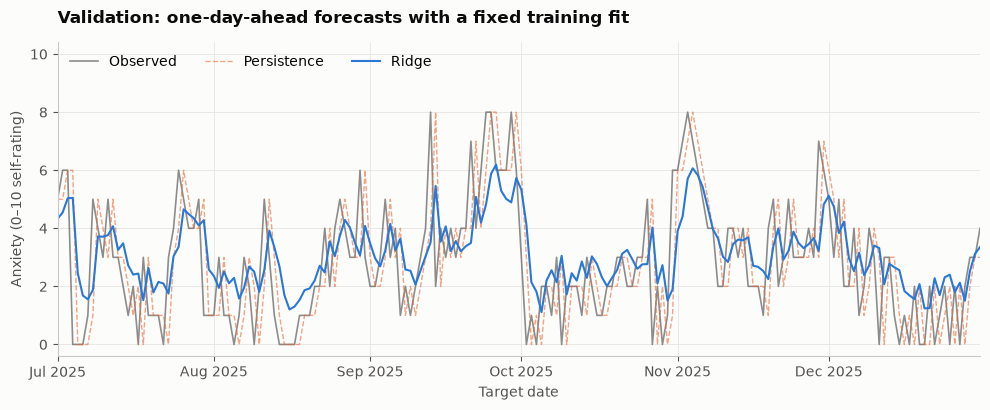

In [39]:
validation_evaluator.plot_over_time("Ridge")
plt.show()

The blue forecasts follow the broad changes but are less extreme than the observed ratings. This is visible around the September and November rises, where several high ratings extend above ridge's predictions, and during calm runs near zero, where ridge often stays above them. Persistence copies the preceding rating, so it can follow the level closely during a run while lagging a sudden change.

Those observations help me understand the score, but the overlay alone cannot tell me whether one rule is better. The aligned metric table measures that comparison. The next plot checks whether the average improvement hides larger errors on the days I most care about.

,n,MAE,Bias
Observed anxiety,,,
0.0,24,2.453,2.453
1.0,28,1.398,1.398
2.0,37,0.836,0.661
3.0,35,0.742,0.175
4.0,24,0.786,-0.543
5.0,14,1.363,-1.287
6.0,13,1.501,-1.471
7.0,4,2.702,-2.702
8.0,5,3.037,-3.037


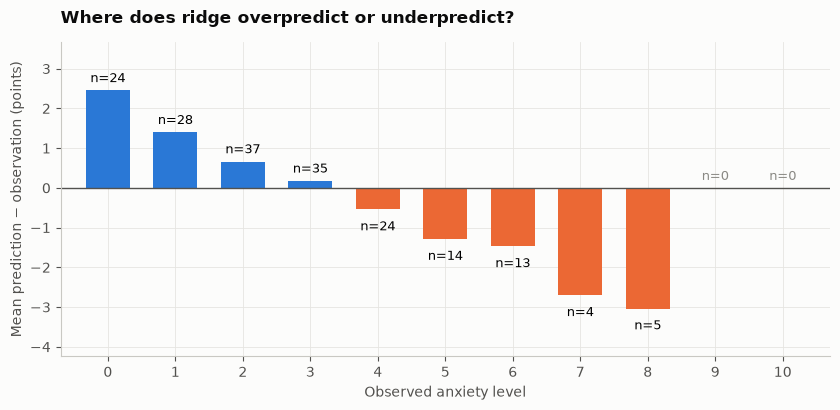

In [40]:
display(validation_evaluator.errors_by_level("Ridge").round(3))
validation_evaluator.plot_errors_by_level("Ridge")
plt.show()

**The average improvement does not carry equally across anxiety levels.** For the **24 observed zero-rating days**, ridge overpredicts by **2.453 points on average**. For ratings **6, 7 and 8**, its mean biases are **−1.471, −2.702 and −3.037 points** respectively: it underpredicts the higher ratings. There are only **4 days rated 7** and **5 rated 8**, so I should not generalize those small groups too confidently. There are no validation targets rated 9 or 10.

This pattern is consistent with forecasts that are less extreme than the outcomes. It can reflect averaging under squared-error fitting, regularization and information absent from the inputs; this plot cannot isolate a single cause. It also groups by the outcome after it is observed, so it is a retrospective error analysis, not an early-warning rule I could apply tonight. I have not evaluated a high-anxiety warning rule in this notebook.

,n,Mean_prediction,Mean_observed,Bias
Forecast bin,,,,
<2,29,1.644,1.586,0.057
2–<4,117,2.916,2.581,0.335
4–<6,36,4.732,4.389,0.343
6–<8,2,6.129,6.500,-0.371
≥8,0,NaN,NaN,NaN


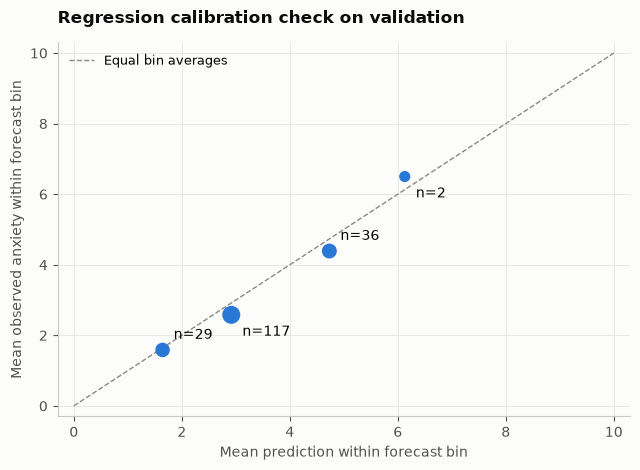

In [41]:
calibration_results = validation_evaluator.calibration_table("Ridge")
assert calibration_results["n"].sum() == len(y_val)
display(calibration_results.round(3))
validation_evaluator.plot_calibration("Ridge")
plt.show()

Most forecasts fall between **2 and 4**: this bin contains **117 days**, with mean prediction **2.916** and mean observed anxiety **2.581**. The **4–6** bin has **36 days**, with means **4.732** and **4.389**. Ridge overpredicts the bin average by about **0.34 points** in both groups. The lowest bin contains **29 days** and has a smaller average gap, **0.057 points**.

Only **two forecasts** fall in the 6–8 bin, and none reaches 8. I therefore have little evidence about calibration at high predicted levels. A point close to the diagonal with $n=2$ is not reassuring on its own.

This does not contradict the previous plot's underprediction of high observed ratings. Here I group by what the model predicted; there I grouped by what actually happened. A high-anxiety outcome that received a moderate forecast appears in a moderate forecast bin here. Bin averages can also conceal substantial individual errors, so I will read this check alongside MAE and the outcome-level error table.

<a id="section-10"></a>

## 10. Writing ridge regression from scratch

I can now use scikit-learn's result as a numerical reference. The aim here is to implement the mathematics myself, not to find a new model by trying more settings. I keep the **same alpha, training rows and fitted preprocessing** as Section 9. Only the optimizer changes.

I will obtain the weights in two ways: a direct solution of the normal equations and repeated gradient-descent updates. Agreement between them and scikit-learn is a useful implementation check. It does not provide three independent pieces of evidence for forecast quality: they solve the same statistical problem.

### 10.1 Viewing the linear model as one neuron

Each feature is multiplied by its weight. The model adds those contributions and the intercept, then applies the identity function $f(z)=z$. The neuron picture describes the prediction rule; learning the weights still requires the loss function and an optimization procedure.

The diagram shows three examples from the actual column order, with dots standing for the other inputs. It does not reduce the model to three features. The current fit still has 17 coefficients and one intercept. An identity activation leaves the weighted sum unchanged, so the output is a rating forecast rather than a probability.

In the derivations below, $X$ means the numeric, imputed and standardized fitting matrix. The code calls it `Z_train` to distinguish it from the raw `X_train` DataFrame. For the real fit, $X$ has shape **899 × 17**, $w$ has 17 entries, and $\mathbf y$ has 899 observed targets. The scratch class receives these numeric inputs; it does not secretly fit its own imputer or scaler.

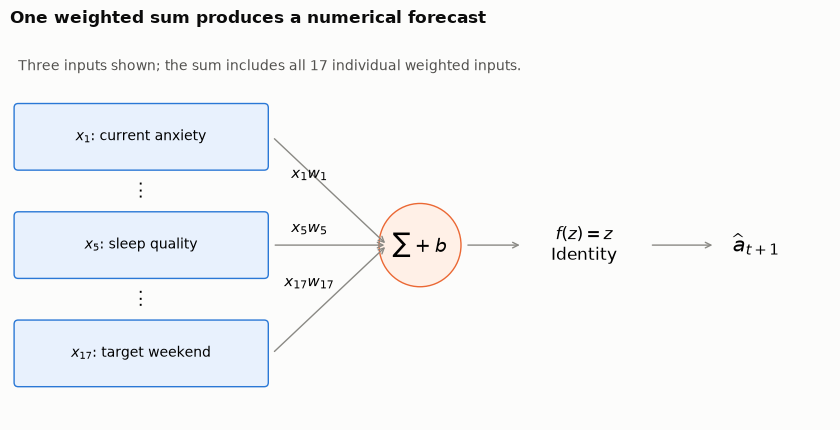

In [42]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 4.6)
ax.axis("off")
inputs = [(3.4, r"$x_1$: current anxiety", r"$x_1w_1$"),
          (2.1, r"$x_5$: sleep quality", r"$x_5w_5$"),
          (0.8, r"$x_{17}$: target weekend", r"$x_{17}w_{17}$")]
for y, label, weight in inputs:
    box = FancyBboxPatch((0.1, y - 0.35), 3.0, 0.7, boxstyle="round,pad=0.05",
                         facecolor="#e8f1fd", edgecolor=BLUE)
    ax.add_patch(box)
    ax.text(1.6, y, label, ha="center", va="center", fontsize=10)
    ax.annotate("", (4.6, 2.1), (3.2, y), arrowprops={"arrowstyle": "->", "color": MUTED})
    ax.text(3.65, (y + 2.1) / 2 + 0.15, weight, ha="center", fontsize=11)
ax.add_patch(plt.Circle((5.0, 2.1), 0.5, facecolor="#fff0e7", edgecolor=ORANGE))
ax.text(5, 2.1, r"$\sum+b$", ha="center", va="center", fontsize=14)
ax.text(1.6, 2.75, r"$\vdots$", ha="center", va="center", fontsize=13)
ax.text(1.6, 1.45, r"$\vdots$", ha="center", va="center", fontsize=13)
ax.annotate("", (6.25, 2.1), (5.55, 2.1), arrowprops={"arrowstyle": "->", "color": MUTED})
ax.text(7.0, 2.1, "$f(z)=z$\nIdentity", ha="center", va="center", fontsize=12)
ax.annotate("", (8.6, 2.1), (7.8, 2.1), arrowprops={"arrowstyle": "->", "color": MUTED})
ax.text(9.1, 2.1, r"$\widehat a_{t+1}$", ha="center", va="center", fontsize=15)
ax.set_title("One weighted sum produces a numerical forecast", pad=10)
ax.text(0.1, 4.2, "Three inputs shown; the sum includes all 17 individual weighted inputs.",
        fontsize=10, color=INK_2)
fig.tight_layout()
plt.show()

### 10.2 Working out the gradients

Let $r=\mathbf y-Xw-b\mathbf 1_n$. Then

$$J(w,b)=\frac1n r^\top r+\alpha w^\top w.$$

For one row, $r_i=y_i-\sum_jx_{ij}w_j-b$. I keep this sign convention throughout the differentiation. Section 9's diagnostic bias uses the opposite sign, prediction minus observation, to make underprediction negative. Squared loss is unchanged by reversing a residual's sign, but an incorrect sign in the derivative would make gradient descent move in the wrong direction.

For one coefficient, changing $w_j$ changes residual $r_i$ at rate $-x_{ij}$. The chain rule gives $\partial(r_i^2)/\partial w_j=-2x_{ij}r_i$. Summing over rows and adding the derivative of the penalty gives

$$\frac{\partial J}{\partial w_j}=-\frac2n\sum_i x_{ij}r_i+2\alpha w_j,
\qquad \boxed{\nabla_wJ=-\frac2nX^\top r+2\alpha w.}$$

There are two forces in this gradient. The data term, $-2X^\top r/n$, changes coefficients to reduce training residuals. The penalty term, $2\alpha w$, pulls them toward zero when I subtract the gradient. If I considered the penalty alone, an update would be $w\leftarrow(1-2\eta\alpha)w$; the full update also includes what the observations say. Regularization therefore changes the solution, rather than merely controlling how fast the solver reaches it.

The dimensions provide a useful check: $X^\top$ is $17\times899$ and $r$ has 899 entries, so $X^\top r$ has 17 entries, one derivative for each coefficient. The factor $1/n$ belongs in the data gradient because the loss uses mean squared error. There is no additional $1/n$ on $2\alpha w$ under this convention.

For the intercept, every residual changes at rate $-1$, and there is no intercept penalty:

$$\frac{\partial J}{\partial b}=-\frac2n\mathbf 1_n^\top r=-2\operatorname{mean}(r).$$

Gradient descent moves against these derivatives: $w\leftarrow w-\eta\nabla_wJ$ and $b\leftarrow b-\eta\,\partial J/\partial b$. The learning rate $\eta$ controls the step size; it is different from the regularization strength $\alpha$.

A positive derivative says that a small increase in that parameter would raise the objective, so subtracting it moves the parameter downward. A negative derivative gives the opposite instruction. The two updates must use gradients evaluated at the same current parameter values; I should not update one parameter and then accidentally compute the other gradient from a different state.

For the small derivative-check matrix below, the initial weights are $(0.3,-0.2)$, the intercept is $1.1$ and alpha is $0.07$. These are arithmetic-test values, separate from my journal fit. The predictions are $[1,1.3,2.5,2]$, giving residuals $[1,-0.3,2.5,2]$. Substitution into the formulas gives

$$\nabla_wJ=[-10.158,-2.478]^\top,\qquad \frac{\partial J}{\partial b}=-2.6.$$

For illustration, a step of $\eta=0.01$ would change the weights to $(0.40158,-0.17522)$ and the intercept to $1.126$. This illustrates the direction and arithmetic of an update. The real-data implementation chooses its step from the training curvature instead of using this illustrative value.

Before using these derivatives to train anything, I check them with a central finite difference. For a parameter $\theta_j$, $[J(\theta+\epsilon e_j)-J(\theta-\epsilon e_j)]/(2\epsilon)$ approximates its derivative. The following small arithmetic test includes nonzero feature means and a nonzero intercept so an intercept mistake cannot hide behind centered data.

The code perturbs one coefficient at a time while holding the others fixed, and separately perturbs the intercept. It compares those numerical slopes with `ridge_gradient`, using `ridge_loss_components` from Section 7 as the objective being differentiated. Agreement is approximate because finite differences involve rounding and a finite step size. I use an explicit numerical tolerance rather than expect bit-for-bit equality.

In [43]:
def ridge_gradient(X, y, w, b, alpha):
    residual = y - (X @ w + b)
    return -2 * X.T @ residual / len(y) + 2 * alpha * w, -2 * residual.mean()


grad_X = np.array([[1., 2.], [2., 2.], [4., -1.], [5., 3.]])
grad_y = np.array([2., 1., 5., 4.])
grad_w, grad_b, grad_alpha = np.array([0.3, -0.2]), 1.1, 0.07
analytic_w, analytic_b = ridge_gradient(grad_X, grad_y, grad_w, grad_b, grad_alpha)
epsilon = 1e-6
numeric_w = np.zeros_like(grad_w)
for j in range(len(grad_w)):
    step = np.zeros_like(grad_w)
    step[j] = epsilon
    plus = ridge_loss_components(grad_X, grad_y, grad_w + step, grad_b, grad_alpha)["Objective"]
    minus = ridge_loss_components(grad_X, grad_y, grad_w - step, grad_b, grad_alpha)["Objective"]
    numeric_w[j] = (plus - minus) / (2 * epsilon)
numeric_b = (ridge_loss_components(grad_X, grad_y, grad_w, grad_b + epsilon, grad_alpha)["Objective"]
             - ridge_loss_components(grad_X, grad_y, grad_w, grad_b - epsilon, grad_alpha)["Objective"]) / (2 * epsilon)
np.testing.assert_allclose(analytic_w, numeric_w, rtol=1e-6, atol=1e-7)
np.testing.assert_allclose(analytic_b, numeric_b, rtol=1e-6, atol=1e-7)
print("Central finite differences agree with both analytic gradients.")

Central finite differences agree with both analytic gradients.


### 10.3 Solving for the weights and intercept

Section 7 showed that the best intercept for any fixed $w$ is $b=\overline y-\overline x^\top w$. I can substitute that result into the objective instead of repeatedly updating $b$.

Define $X_c=X-\mathbf 1_n\overline x^\top$ and $y_c=\mathbf y-\overline y\mathbf 1_n$. These means come from training rows only. Substituting the intercept expression gives the residual identity

$$\mathbf y-Xw-b\mathbf 1_n
=\big(\mathbf y-\overline y\mathbf 1_n\big)
-\big(X-\mathbf 1_n\overline x^\top\big)w
=y_c-X_cw,$$

where I substituted $b=\overline y-\overline x^\top w$. This is why centering removes the intercept from the optimization without penalizing it or forgetting it. The resulting objective is

$$J_c(w)=\frac1n\lVert y_c-X_cw\rVert^2+\alpha\lVert w\rVert^2.$$

Setting its gradient to zero and rearranging gives

$$-\frac2n X_c^\top(y_c-X_cw)+2\alpha w=0
\quad\Longrightarrow\quad
(X_c^\top X_c+n\alpha I_d)w=X_c^\top y_c.$$

Thus the familiar closed form is

$$\boxed{\widehat w=(X_c^\top X_c+n\alpha I_d)^{-1}X_c^\top y_c,
\qquad \widehat b=\overline y-\overline x^\top\widehat w.}$$

The inverse explains the algebra. In code I use `np.linalg.solve(A, rhs)`, which solves the linear system directly rather than explicitly constructing an inverse. With $\alpha>0$, $A$ is positive definite even when features overlap or a column is constant: $v^\top Av=\lVert X_cv\rVert^2+n\alpha\lVert v\rVert^2>0$ for every nonzero $v$.

The identity matrix $I_d$ is $17\times17$, so $n\alpha$ is added to each diagonal entry of the feature cross-product matrix. There is no intercept entry in that matrix: I have already eliminated the intercept by centering. Adding a penalty to an extra column of ones would solve a different problem.

This scratch class deliberately requires **positive alpha**. At alpha zero, redundant columns can make the normal equations singular, and an ordinary least-squares implementation would need a rank-aware approach such as a pseudoinverse. Every candidate in Section 9's ridge grid is positive, so that separate case is outside this class's contract. The later development experiments include alpha zero through scikit-learn's rank-aware `LinearRegression`, not this scratch class.

For both implementations I cache $G=X_c^\top X_c/n$ and $q=X_c^\top y_c/n$. The gradient becomes $2(Gw-q)+2\alpha w$. This is the same gradient as above, computed from reusable training summaries rather than multiplying through all 899 rows at every step.

Dividing the normal equations by $n$ gives $(G+\alpha I_d)w=q$, which is exactly what the closed-form branch solves. $G$ is a $17\times17$ matrix and $q$ is a 17-entry vector. For this small feature count, caching them makes repeated gradient calculations inexpensive. Both branches still use information from the complete fitting set: this is **full-batch gradient descent**, not stochastic updates on individual days.

Although Section 9 already standardizes the inputs, the class computes and stores their training means again so it also works for the noncentered test matrix. On the standardized real inputs those means are essentially zero. Centering the target is an internal algebraic step; prediction restores the offset through `self.intercept_`, so outputs remain on the original anxiety scale.

### 10.4 Choosing the step size and checking convergence

For the centered weights, the Hessian is $H=2(G+\alpha I_d)$. Let $L$ be its largest eigenvalue. I use $\eta=1/L$, a conservative stable step for this convex quadratic. The gradient tells me which direction to move; $L$ controls how sharply the objective curves, so it limits how far I move at once.

Adding $\alpha I_d$ shifts every eigenvalue of $G$ by alpha, so $L=2[\lambda_{\max}(G)+\alpha]$. This is the quantity computed by `largest_curvature` in the class. It depends on the fitting inputs and the already selected alpha, not on validation outcomes.

The Hessian is the matrix of second derivatives. Here it is constant in $w$, and positive alpha makes all its eigenvalues positive. The objective therefore has a unique minimizing weight vector; I do not need a random initialization or a search for different local minima.

To see the role of the step size, let $e^{(k)}=w^{(k)}-\widehat w$ be the distance from the solution. For this quadratic,

$$e^{(k+1)}=(I_d-\eta H)e^{(k)}.$$

Along a direction with Hessian eigenvalue $\lambda$, the error is multiplied by $1-\eta\lambda$. With $\eta=1/L$ and $0<\lambda\leq L$, that multiplier lies between zero and one, so the error contracts. Very different eigenvalues can still make some directions converge much more slowly than others. Increasing alpha can improve this conditioning, but I choose alpha for held-out prediction quality, not just to make optimization faster.

At $w=0$, the recovered intercept is $\overline y$, so the initial real-data model predicts the training mean. This connects the optimization to Section 8's simplest baseline: the updates learn which feature contributions justify departing from that mean.

The gradient-descent fit starts at $w=0$ and stops only when the largest absolute gradient component is at most $10^{-10}$. Reaching a maximum iteration limit instead raises an error. I record every initial update through iteration 99, then every 50 updates and the final state. The plots use those actual iteration numbers. A descending loss curve alone would not prove that the implementation reached the solution, so I also record and check the gradient size.

The stopping statistic is $\lVert\nabla J_c(w)\rVert_\infty=\max_j|\partial J_c/\partial w_j|$. It measures whether another small parameter move can substantially lower this **training objective**, in the current coordinates. It is not a bound on tomorrow's forecast error and does not express statistical confidence in the coefficients. Validation scores do not choose the number of updates; the numerical convergence rule does.

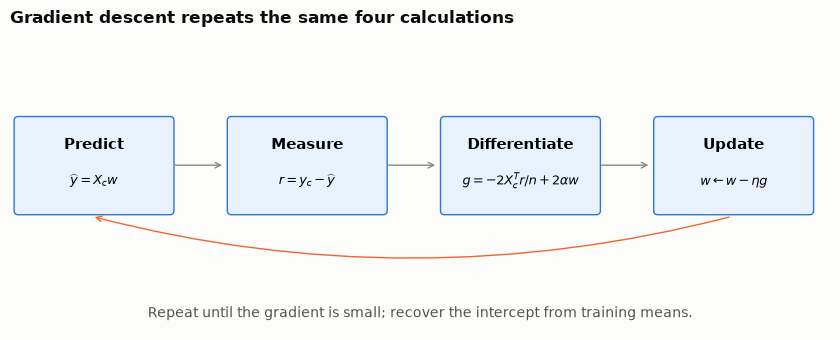

In [44]:
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 3.4)
ax.axis("off")
steps = [(0.1, "Predict", r"$\widehat y=X_cw$"), (2.7, "Measure", r"$r=y_c-\widehat y$"),
         (5.3, "Differentiate", r"$g=-2X_c^Tr/n+2\alpha w$"),
         (7.9, "Update", r"$w\leftarrow w-\eta g$")]
for x, title, equation in steps:
    box = FancyBboxPatch((x, 1.4), 1.85, 1.05, boxstyle="round,pad=0.05",
                         facecolor="#e8f1fd", edgecolor=BLUE)
    ax.add_patch(box)
    ax.text(x + 0.925, 2.12, title, ha="center", fontsize=11, weight="bold")
    ax.text(x + 0.925, 1.7, equation, ha="center", fontsize=9)
for left, right in [(1.98, 2.62), (4.58, 5.22), (7.18, 7.82)]:
    ax.annotate("", (right, 1.93), (left, 1.93), arrowprops={"arrowstyle": "->", "color": MUTED})
ax.annotate("", (1.0, 1.33), (8.8, 1.33),
            arrowprops={"arrowstyle": "->", "color": ORANGE, "connectionstyle": "arc3,rad=-0.13"})
ax.text(5, 0.15, "Repeat until the gradient is small; recover the intercept from training means.",
        ha="center", fontsize=10, color=INK_2)
ax.set_title("Gradient descent repeats the same four calculations", pad=12)
fig.tight_layout()
plt.show()

In [45]:
class MedianStandardizerScratch:
    "Column medians, means and population standard deviations from fitting rows."
    def __init__(self, scale=True):
        self.scale = scale

    def fit(self, X):
        X = np.asarray(X,dtype=float)
        if X.ndim != 2 or not len(X) or np.isinf(X).any():
            raise ValueError("Expected nonempty numeric X; missing values may be NaN")
        self.n_features_in_ = X.shape[1]
        self.medians_ = np.array([np.median(column[~np.isnan(column)])
            if (~np.isnan(column)).any() else 0. for column in X.T])
        filled = np.where(np.isnan(X),self.medians_,X)
        self.mean_ = filled.mean(axis=0)
        std = np.sqrt(np.mean((filled-self.mean_)**2,axis=0))
        self.scale_ = np.where(std==0,1.,std)
        return self

    def transform(self, X):
        if not hasattr(self,"medians_"):
            raise ValueError("Fit on training rows first")
        X = np.asarray(X,dtype=float)
        if X.ndim != 2 or X.shape[1]!=self.n_features_in_ or np.isinf(X).any():
            raise ValueError("Input must match the fitted feature layout")
        filled = np.where(np.isnan(X),self.medians_,X)
        return (filled-self.mean_)/self.scale_ if self.scale else filled

class LeastSquaresScratch:
    "Unpenalized, centered least squares; lstsq handles rank-deficient columns."
    def fit(self, X, y):
        X, y = np.asarray(X,dtype=float), np.asarray(y,dtype=float)
        if X.ndim!=2 or y.shape!=(len(X),) or not len(y) or not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError("Expected finite X (n,d) and observed y (n,)")
        self.n_features_in_ = X.shape[1]
        self.coef_ = np.linalg.lstsq(X-X.mean(axis=0),y-y.mean(),rcond=None)[0]
        self.intercept_ = float(y.mean()-X.mean(axis=0)@self.coef_)
        return self

    def predict(self, X):
        if not hasattr(self,"coef_"):
            raise ValueError("Fit before predicting")
        X = np.asarray(X,dtype=float)
        if X.ndim!=2 or X.shape[1]!=self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Prediction matrix must be finite with the fitted columns")
        return X@self.coef_+self.intercept_

class RidgeScratch:
    def __init__(self, alpha, method="closed_form", tolerance=1e-10, max_iter=100000):
        if not np.isfinite(alpha) or alpha <= 0:
            raise ValueError("This ridge implementation requires a positive finite alpha")
        if method not in {"closed_form", "gradient_descent"}:
            raise ValueError("Choose closed_form or gradient_descent")
        if tolerance <= 0 or max_iter < 1:
            raise ValueError("Convergence controls must be positive")
        self.alpha, self.method = float(alpha), method
        self.tolerance, self.max_iter = tolerance, max_iter

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (X.shape[0],) or len(y) == 0:
            raise ValueError("Expected a nonempty (n, d) matrix and (n,) targets")
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError("Impute inputs before fitting; targets must be observed")
        self.n_features_in_ = X.shape[1]
        self.x_mean_, self.y_mean_ = X.mean(axis=0), float(y.mean())
        Xc, yc = X - self.x_mean_, y - self.y_mean_
        gram, rhs = Xc.T @ Xc / len(y), Xc.T @ yc / len(y)
        self.loss_history_, self.iteration_history_, self.gradient_history_ = [], [], []
        if self.method == "closed_form":
            self.coef_ = np.linalg.solve(gram + self.alpha * np.eye(X.shape[1]), rhs)
            self.n_iter_ = 0
        else:
            self.coef_ = np.zeros(X.shape[1])
            largest_curvature = 2 * (np.linalg.eigvalsh(gram).max() + self.alpha)
            self.learning_rate_ = 1 / largest_curvature
            for iteration in range(self.max_iter + 1):
                gradient = 2 * (gram @ self.coef_ - rhs) + 2 * self.alpha * self.coef_
                converged = np.max(np.abs(gradient)) <= self.tolerance
                if iteration < 100 or iteration % 50 == 0 or converged or iteration == self.max_iter:
                    loss = np.mean((yc - Xc @ self.coef_) ** 2) + self.alpha * (self.coef_ @ self.coef_)
                    self.iteration_history_.append(iteration)
                    self.loss_history_.append(float(loss))
                    self.gradient_history_.append(float(np.max(np.abs(gradient))))
                if converged:
                    self.n_iter_ = iteration
                    break
                if iteration == self.max_iter:
                    raise RuntimeError("Gradient descent did not converge; inspect the controls")
                self.coef_ -= self.learning_rate_ * gradient
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.coef_
        self.gradient_norm_ = float(np.max(np.abs(2 * (gram @ self.coef_ - rhs) + 2 * self.alpha * self.coef_)))
        return self

    def predict(self, X):
        if not hasattr(self, "coef_"):
            raise ValueError("Fit the model before predicting")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Prediction inputs must be finite and have the fitted feature count")
        return X @ self.coef_ + self.intercept_

### 10.5 Checking my ridge code against scikit-learn

First I use a small matrix with nonzero column means, a constant column and two identical columns. It deliberately combines cases that can expose a penalized-intercept error or a singular-matrix problem. I compare both scratch solvers with scikit-learn using $n\alpha$ in its convention.

Then I implement the preprocessing directly with `MedianStandardizerScratch`. For each fitting column I calculate the observed median, fill its missing values, calculate the mean and population standard deviation, and use scale 1 for a constant column. A wholly missing fitting column uses zero, matching the declared sklearn policy. Validation is transformed using those stored fitting statistics. I check the resulting arrays against Section 9's library preprocessing before giving the solvers identical inputs and targets. No preprocessing is refitted on validation. Centering inside the scratch estimator is part of handling the intercept; it is not a second estimate from held-out rows.

`LeastSquaresScratch` separately covers the alpha-zero limit used by the later development experiments. It centers the inputs, solves the rank-aware least-squares problem with NumPy linear algebra and restores the intercept. The redundant-column example also checks its predictions against sklearn. Positive-alpha ridge still uses the uniquely regularized solve described above.

#### Matching the code to the equations

| Code | Mathematical role |
|---|---|
| `self.x_mean_`, `self.y_mean_` | Store $\overline x,\overline y$ from the fitting data |
| `Xc`, `yc` | Form the centered inputs and targets |
| `gram`, `rhs` | Cache $G=X_c^\top X_c/n$ and $q=X_c^\top y_c/n$ |
| `np.linalg.solve(gram + alpha * I, rhs)` | Solve the ridge normal equations |
| `gradient = 2 * (gram @ coef - rhs) + 2 * alpha * coef` | Evaluate the same centered ridge gradient |
| `coef -= learning_rate * gradient` | Move against that gradient |
| `y_mean - x_mean @ coef` | Recover the unpenalized intercept |
| `X @ coef + intercept` | Forecast in the original target units |

The two identical test columns make the unregularized problem redundant; the constant column becomes zero after centering and should receive zero weight under positive regularization. The nonzero feature means make correct intercept recovery necessary. These cases check features of the mathematics that ordinary random inputs might fail to expose clearly.

For the real comparison, `np.allclose` tests coefficients, intercepts and predictions with explicit tolerances. Its condition is approximately $|a-b|\leq\mathrm{atol}+\mathrm{rtol}|b|$. This is more appropriate than exact equality for floating-point linear algebra. I check predictions as well as coefficients because a small parameter difference can be amplified by an input; the actual maximum prediction discrepancy is printed below. The coefficient table may round a tiny difference to zero without implying bitwise-identical fits.

In [46]:
check_X = np.array([[2., 2., 1.], [3., 3., 1.], [5., 5., 1.], [7., 7., 1.]])
check_y, check_alpha = np.array([3., 4., 6., 7.]), 0.2
check_reference = Ridge(alpha=len(check_y) * check_alpha, solver="svd").fit(check_X, check_y)
for method in ["closed_form", "gradient_descent"]:
    checked = RidgeScratch(check_alpha, method=method).fit(check_X, check_y)
    np.testing.assert_allclose(checked.coef_, check_reference.coef_, atol=1e-8, rtol=1e-7)
    np.testing.assert_allclose(checked.intercept_, check_reference.intercept_, atol=1e-8, rtol=1e-7)
    np.testing.assert_allclose(checked.predict(check_X), check_reference.predict(check_X), atol=1e-8, rtol=1e-7)
from sklearn.linear_model import LinearRegression
ols_scratch_check = LeastSquaresScratch().fit(check_X,check_y)
ols_library_check = LinearRegression().fit(check_X,check_y)
np.testing.assert_allclose(ols_scratch_check.predict(check_X),ols_library_check.predict(check_X),atol=1e-10)
print("Passed: nonzero means, unpenalized intercept, constant and duplicate columns; rank-deficient OLS limit.")

scratch_preprocessor = MedianStandardizerScratch().fit(X_train)
Z_train = scratch_preprocessor.transform(X_train)
Z_val = scratch_preprocessor.transform(X_val)
np.testing.assert_allclose(Z_train,scaler.transform(imputer.transform(X_train)),atol=1e-12)
np.testing.assert_allclose(Z_val,scaler.transform(imputer.transform(X_val)),atol=1e-12)
# An entirely missing column and a constant column have explicit behavior.
preprocess_check = MedianStandardizerScratch().fit([[np.nan,2.],[np.nan,2.]])
np.testing.assert_allclose(preprocess_check.transform([[np.nan,2.]]),[[0.,0.]])
assert Z_train.shape[1] == Z_val.shape[1] == 17
ridge_closed = RidgeScratch(selected_alpha, method="closed_form").fit(Z_train, y_train)
ridge_gd = RidgeScratch(selected_alpha, method="gradient_descent").fit(Z_train, y_train)
sklearn_ridge = ridge_pipeline.named_steps["ridge"]

for scratch in [ridge_closed, ridge_gd]:
    np.testing.assert_allclose(scratch.coef_, sklearn_ridge.coef_, rtol=1e-7, atol=1e-8)
    np.testing.assert_allclose(scratch.intercept_, sklearn_ridge.intercept_, rtol=1e-7, atol=1e-8)
    np.testing.assert_allclose(scratch.predict(Z_val), ridge_validation_predictions, rtol=1e-7, atol=1e-8)
assert np.all(np.diff(ridge_gd.loss_history_) <= 1e-10)
assert ridge_gd.gradient_norm_ <= ridge_gd.tolerance
print(f"Gradient descent converged after {ridge_gd.n_iter_:,} updates; step size = {ridge_gd.learning_rate_:.6g}.")
print(f"Final maximum absolute gradient: {ridge_gd.gradient_norm_:.3g}")
print(f"Maximum validation prediction difference (GD vs sklearn): "
      f"{np.max(np.abs(ridge_gd.predict(Z_val) - ridge_validation_predictions)):.3g}")

Passed: nonzero means, unpenalized intercept, constant and duplicate columns; rank-deficient OLS limit.
Gradient descent converged after 556 updates; step size = 0.119452.
Final maximum absolute gradient: 9.8e-11
Maximum validation prediction difference (GD vs sklearn): 1.41e-10


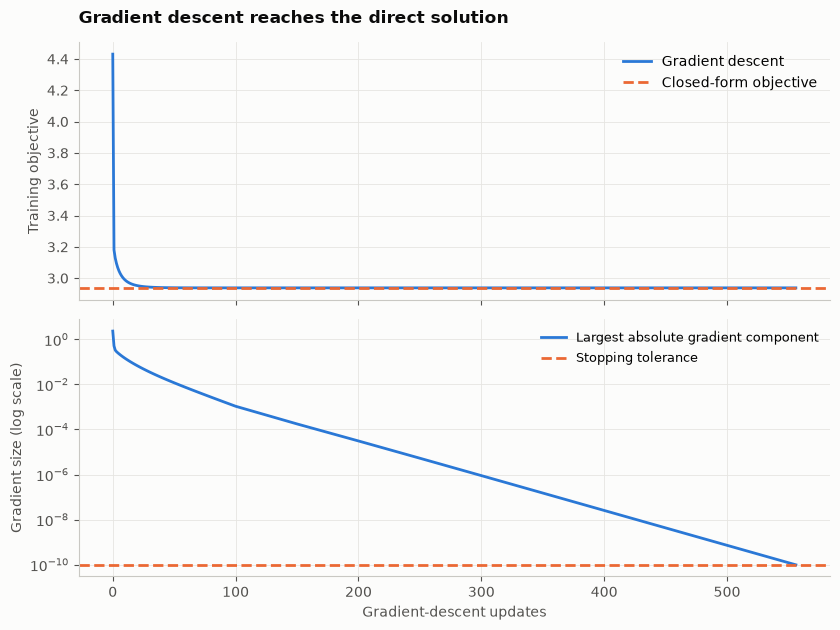

In [47]:
closed_objective = ridge_loss_components(Z_train, y_train.to_numpy(), ridge_closed.coef_,
                                         ridge_closed.intercept_, selected_alpha)["Objective"]
fig, axes = plt.subplots(2, 1, figsize=(8.5, 6.4), sharex=True)
axes[0].plot(ridge_gd.iteration_history_, ridge_gd.loss_history_, color=BLUE, label="Gradient descent")
axes[0].axhline(closed_objective, color=ORANGE, linestyle="--", label="Closed-form objective")
axes[0].set_ylabel("Training objective")
axes[0].set_title("Gradient descent reaches the direct solution", pad=14)
axes[0].legend()
axes[1].semilogy(ridge_gd.iteration_history_, ridge_gd.gradient_history_, color=BLUE,
                 label="Largest absolute gradient component")
axes[1].axhline(ridge_gd.tolerance, color=ORANGE, linestyle="--", label="Stopping tolerance")
axes[1].set_xlabel("Gradient-descent updates")
axes[1].set_ylabel("Gradient size (log scale)")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

The numerical gradient check passed, and gradient descent reached its stopping tolerance after **556 updates**, using a step size of about **0.119452**. Its final largest absolute gradient component is **$9.8\times10^{-11}$**, below the specified $10^{-10}$ threshold.

The upper plot shows the objective falling to the direct solution's value. It looks flat early because later changes are small on that vertical scale. The lower plot makes those later steps visible: the gradient continues to shrink until it reaches the stopping threshold. The code also checks that the recorded loss does not increase beyond numerical tolerance.

The maximum difference between gradient-descent and scikit-learn validation predictions is only **$1.41\times10^{-10}$ points**. The direct solution agrees as well. These discrepancies are numerical, far below the precision of the self-ratings; both scratch solvers reproduce the fitted reference model.

In [48]:
coefficient_comparison = pd.DataFrame({
    "Domain": builder.feature_dictionary.loc[X_train.columns, "domain"],
    "Gradient descent": ridge_gd.coef_,
    "Closed form": ridge_closed.coef_,
    "sklearn": sklearn_ridge.coef_,
}, index=X_train.columns)
coefficient_comparison.loc["Intercept"] = ["unpenalized", ridge_gd.intercept_, ridge_closed.intercept_, sklearn_ridge.intercept_]
coefficient_comparison["Max absolute difference"] = coefficient_comparison[
    ["Gradient descent", "Closed form", "sklearn"]].max(axis=1) - coefficient_comparison[
    ["Gradient descent", "Closed form", "sklearn"]].min(axis=1)
display(coefficient_comparison.round(8))

scratch_validation_scorecard = pd.DataFrame({
    "sklearn": regression_scores(y_val, ridge_validation_predictions, validation_baselines["Persistence"]),
    "Closed form": regression_scores(y_val, ridge_closed.predict(Z_val), validation_baselines["Persistence"]),
    "Gradient descent": regression_scores(y_val, ridge_gd.predict(Z_val), validation_baselines["Persistence"]),
}).T
display(scratch_validation_scorecard.round(6))

,Domain,Gradient descent,Closed form,sklearn,Max absolute difference
anxiety_today,history,0.822273,0.822273,0.822273,0.0
anxiety_missing_today,history,-0.134160,-0.134160,-0.134160,0.0
sleep_adequacy_today,sleep,-0.027955,-0.027955,-0.027955,0.0
sleep_adequacy_missing_today,sleep,0.194111,0.194111,0.194111,0.0
sleep_quality_today,sleep,0.147434,0.147434,0.147434,0.0
sleep_quality_missing_today,sleep,-0.041368,-0.041368,-0.041368,0.0
exercise_today,exercise,0.021452,0.021452,0.021452,0.0
exercise_missing_today,exercise,-0.006093,-0.006093,-0.006093,0.0
socializing_today,socializing,0.043649,0.043649,0.043649,0.0
socializing_missing_today,socializing,0.003910,0.003910,0.003910,0.0


,MAE,RMSE,R2,Skill vs persistence
sklearn,1.295514,1.629257,0.344469,0.057808
Closed form,1.295514,1.629257,0.344469,0.057808
Gradient descent,1.295514,1.629257,0.344469,0.057808


The three coefficient columns agree to the displayed precision, and the `np.allclose` checks passed for coefficients, intercept and validation predictions. The scorecard is consequently the same for all three solvers: **MAE 1.295514** and **RMSE 1.629257**. Reimplementing ridge has verified the calculation, not created an additional performance improvement.

The intercept is **3.57842**, the training target mean after centering the fitted inputs. Current anxiety has weight **0.8223**, the three-day mean **0.5298**, and the seven-day mean **−0.1106**. Those weights belong to overlapping inputs; the negative seven-day coefficient does not mean that a higher recent average protects me from anxiety. It changes the prediction conditionally on the other included summaries.

For example, increasing standardized current anxiety by one while keeping the other 16 inputs fixed raises the fitted prediction by **0.8223 points**. On the raw input scale the change is $w_j\Delta v_j/s_j$, where $s_j$ is that input's training scale. A one-point change in the original rating is therefore not automatically a one-unit change in the standardized input. Also, changing current anxiety in a real daily record changes its rolling summaries too, so that one-coefficient calculation is a conditional reading of the equation, not the complete effect of changing a day's entry.

The intercept is the forecast at the vector of training feature means, where standardized inputs are all zero. That reference need not correspond to an actual observed evening, especially when some columns are binary flags. It sets the model's level; the weighted deviations determine each day's forecast.

The habit weights also need that care. Sleep adequacy is **−0.0280**, while sleep quality is **+0.1474** after the other inputs are included, despite the negative pooled sleep associations in Section 5. That is a different comparison: these are jointly fitted, regularized, standardized coefficients for tomorrow's target, not pooled same-evening correlations. Their signs do not establish that better sleep raises or lowers anxiety causally. Exercise and socializing have small positive weights here, **0.0215** and **0.0436**; their practical predictive contribution still needs the planned ablations.

Missingness and coverage coefficients describe the measurement pattern, not a habit intervention. For nonconstant binary indicators, a raw 0-to-1 change is not a one-standard-deviation change, as Section 7 explained. I cannot rank personal actions from coefficient magnitudes or signs. I have not calculated coefficient uncertainty intervals here.

### 10.6 What I learned from checking the two versions

The gradient check tests the derivatives. The small-matrix check tests intercept handling and correlated or constant inputs. The real-data comparison tests the alpha conversion, preprocessing alignment and both solvers together. The loss curve and stopping criterion show that the iterative fit actually converged.

Together these checks support my implementation of ridge. They do not prove that a coefficient is causal, that the Gaussian assumptions in Section 7 hold, or that tomorrow's errors will match this validation period. A habit coefficient must still be read alongside correlated history features and the missingness indicators; its sign alone cannot answer whether that habit adds predictive value.

There is also a distinction between **optimization error** and **forecast error**. Here the scratch and library predictions differ by roughly $10^{-10}$ points, while the held-out MAE is about 1.3 points. Solving the same objective more precisely will not remove the much larger forecasting uncertainty. Improving that requires useful information, an appropriate model and evidence from later dates, rather than additional gradient-descent iterations after convergence.

**Next, Section 11:** compare lookback windows and forecast horizons on development data. Section 12 will then ask directly whether habits improve on history-only models. The current seven-day, one-day-ahead ridge fit is a documented reference for those experiments, not a feature set chosen from the 2026 outcomes.

<a id="section-11"></a>

## 11. Trying different lookback windows and forecast days

Seven days was an understandable starting point, not a result. I now compare lookbacks $k=1,3,7,14$ for forecasts one and three days ahead. I tune each configuration using training-only time-series CV and compare their predictions on **the same 184 validation target dates**. There are no 2026 predictions in these experiments.

### 11.1 Setting up the window and horizon comparisons

The target is $y_t^{(h)}=a_{t+h}$. With $h=3$, the forecast must use information available three evenings before the target, not observations collected in between. Persistence therefore means $\widehat a_{t+3}=a_t$ for that task.

The lookback controls the available anxiety summaries: $k=1$ uses today's rating, $k=3$ adds a three-day mean, $k=7$ adds a seven-day mean, and $k=14$ adds a fourteen-day mean. Their coverage columns change with them. These are nested feature sets, not four different rolling means substituted into an otherwise identical single column. Lifestyle measurements, calendar encoding and the sleep-shortfall recurrence remain fixed. In particular, the recurrence can remember more than $k$ days; I am testing the anxiety-summary windows, not claiming to truncate every input's memory.

I hold the sleep decay at 0.8 and its shortfall threshold at 3, as in Section 6. I do not tune those choices in this experiment.

### 11.2 Using the same dates for a fair comparison

Longer windows lose more initial rows. I intersect eligible **target dates** across all eight forecasting configurations before comparing them. Each target rating is therefore identical across configurations, although its issue date changes with the horizon.

A three-day horizon also changes label availability. If validation begins with target 1 July, that forecast is issued on 28 June. A fixed model fitted for that first forecast cannot use training targets from 29 or 30 June. I use this conservative cutoff for **all** configurations, so their fitting targets match. Inside CV I similarly retain only fitting labels available by the earliest issue time in the next validation block. I purge using actual dates rather than assuming that two rows always mean two calendar days.

For each candidate alpha, each fold minimizes the same $\mathrm{MSE}+\alpha\lVert w\rVert^2$ objective as Sections 7–10. Alpha is chosen by pooled CV MAE; validation then compares the window/horizon configurations. This is model development, so the lowest validation score is not an unbiased estimate of the final selected model's performance.

In [49]:
development_daily = clean.loc[:VALIDATION_END].copy()
development_anxiety = development_daily["anxiety_level"]
from sklearn.linear_model import LinearRegression

# Include the unregularized limit explicitly alongside positive ridge penalties.
EXPERIMENT_ALPHAS = np.r_[0., np.logspace(-6, 4, 21)]


def make_experiment_pipeline(alpha, n_fit):
    model = make_ridge_pipeline(alpha, n_fit)
    if alpha == 0:
        model.set_params(ridge=LinearRegression())
    return model


def build_development_task(lookback, horizon):
    # h=0 is a separately labeled association diagnostic, never a forecasting choice.
    task_builder = FeatureBuilder(lookback=lookback, horizon=max(1, horizon), sleep_decay=SLEEP_DECAY)
    features, target, dates = task_builder.build(development_daily)
    dictionary = task_builder.feature_dictionary.copy()
    if horizon == 0:
        features = features.loc[:, dictionary["domain"].ne("history")]
        dictionary = dictionary.loc[features.columns]
        features["target_is_weekend"] = (features.index.dayofweek >= 5).astype(float)
        target = development_anxiety.copy()
        dates["target_date"] = features.index
        dates["target_in_calendar"] = True
    usable = dates["full_window"] & dates["target_in_calendar"] & target.notna()
    issue_dates = features.index[usable]
    target_index = pd.DatetimeIndex(dates.loc[usable, "target_date"], name="target_date")
    features = features.loc[usable].copy()
    features.index = target_index
    target = pd.Series(target.loc[usable].to_numpy(), index=target_index, name="Observed")
    np.testing.assert_array_equal(target, development_anxiety.reindex(target_index))
    assert (target_index - issue_dates == pd.Timedelta(days=horizon)).all()
    return {"X": features, "y": target, "dictionary": dictionary, "h": horizon, "k": lookback}


def available_date_splits(target_index, horizon, n_splits=5):
    folds = []
    for fit, score in expanding_window_splits(len(target_index), n_splits):
        first_issue = target_index[score].min() - pd.Timedelta(days=horizon)
        fit = fit[target_index[fit] <= first_issue]
        assert len(fit) and target_index[fit].max() <= first_issue
        folds.append((fit, score))
    return folds


def tune_development_ridge(features, targets, folds):
    # Every alpha gets fresh fold-specific imputation, scaling and coefficients.
    scored_positions = np.concatenate([score for _, score in folds])
    best = None
    records = []
    for alpha in EXPERIMENT_ALPHAS:
        oof = pd.Series(np.nan, index=features.index)
        for fit, score in folds:
            model = make_experiment_pipeline(float(alpha), len(fit))
            model.fit(features.iloc[fit], targets.iloc[fit])
            oof.iloc[score] = model.predict(features.iloc[score])
        mae = mean_absolute_error(targets.iloc[scored_positions], oof.iloc[scored_positions])
        records.append({"alpha": alpha, "CV MAE": mae})
        if best is None or mae < best["mae"]:
            best = {"alpha": float(alpha), "mae": mae, "oof": oof}
    best["search"] = pd.DataFrame(records)
    return best


def horizon_baselines(fit_y, target_index, horizon):
    issue_dates = target_index - pd.Timedelta(days=horizon)
    context = pd.DataFrame({"anxiety_today": development_anxiety.reindex(issue_dates).to_numpy(),
                            "anxiety_mean_7d": development_anxiety.rolling(7, min_periods=1).mean()
                                                .reindex(issue_dates).to_numpy()}, index=issue_dates)
    result = baseline_predictions(fit_y, context, development_anxiety)
    result.index = target_index
    return result


forecast_tasks = {(k, h): build_development_task(k, h) for h in [1, 3] for k in [1, 3, 7, 14]}
common_task_dates = next(iter(forecast_tasks.values()))["X"].index
for task in forecast_tasks.values():
    common_task_dates = common_task_dates.intersection(task["X"].index)
common_task_dates = common_task_dates.sort_values()
c4_validation_dates = common_task_dates[(common_task_dates > TRAIN_END) & (common_task_dates <= VALIDATION_END)]
first_three_day_issue = c4_validation_dates.min() - pd.Timedelta(days=3)
c4_training_dates = common_task_dates[common_task_dates <= min(TRAIN_END, first_three_day_issue)]
c4_folds = available_date_splits(c4_training_dates, horizon=3)
assert len(c4_validation_dates) == 184
assert c4_training_dates.max() <= first_three_day_issue
print(f"Common fitting targets: {len(c4_training_dates)}, {c4_training_dates.min().date()}–{c4_training_dates.max().date()}")
print(f"Common validation targets: {len(c4_validation_dates)}, {c4_validation_dates.min().date()}–{c4_validation_dates.max().date()}")
display(pd.DataFrame([{"Fold": f, "Fit rows": len(fit), "Validation rows": len(score),
                       "Last fitting target": c4_training_dates[fit].max().date(),
                       "Earliest issue time (h=3)": (c4_training_dates[score].min() - pd.Timedelta(days=3)).date()}
                      for f, (fit, score) in enumerate(c4_folds, 1)]).set_index("Fold"))

Common fitting targets: 888, 2023-01-17–2025-06-28
Common validation targets: 184, 2025-07-01–2025-12-31


,Fit rows,Validation rows,Last fitting target,Earliest issue time (h=3)
Fold,,,,
1,146,148,2023-06-12,2023-06-12
2,294,148,2023-11-10,2023-11-10
3,442,148,2024-04-08,2024-04-08
4,590,148,2024-09-03,2024-09-03
5,738,148,2025-01-29,2025-01-29


In [50]:
c4_records, c4_predictions, c4_models, c4_searches = [], {}, {}, {}
c4_baselines = {h: horizon_baselines(forecast_tasks[(7, h)]["y"].loc[c4_training_dates],
                                    c4_validation_dates, h) for h in [1, 3]}
for (k, h), task in forecast_tasks.items():
    fit_x, fit_y = task["X"].loc[c4_training_dates], task["y"].loc[c4_training_dates]
    choice = tune_development_ridge(fit_x, fit_y, c4_folds)
    model = make_experiment_pipeline(choice["alpha"], len(fit_x)).fit(fit_x, fit_y)
    prediction = pd.Series(model.predict(task["X"].loc[c4_validation_dates]), index=c4_validation_dates)
    scores = regression_scores(task["y"].loc[c4_validation_dates], prediction, c4_baselines[h]["Persistence"])
    c4_records.append({"h": h, "k": k, "Features": fit_x.shape[1], "alpha": choice["alpha"],
                       "Training CV MAE": choice["mae"], **scores})
    c4_predictions[(k, h)], c4_models[(k, h)], c4_searches[(k, h)] = prediction, model, choice["search"]
c4_results = pd.DataFrame(c4_records).set_index(["h", "k"])
c4_display = c4_results.round(4)
c4_display["alpha"] = c4_results["alpha"].map(lambda a: "0 (OLS)" if a == 0 else f"{a:.3g}")
display(c4_display)

baseline_rows = []
for h, predictions in c4_baselines.items():
    actual = forecast_tasks[(7, h)]["y"].loc[c4_validation_dates]
    for name, prediction in predictions.items():
        baseline_rows.append({"h": h, "Baseline": name, **regression_scores(actual, prediction, predictions["Persistence"])})
c4_baseline_scores = pd.DataFrame(baseline_rows).set_index(["h", "Baseline"])
display(c4_baseline_scores.round(4))
print("Window and horizon forecasts scored on validation only; alpha choices came from training-only CV.")

Features    alpha  Training CV MAE     MAE    RMSE      R2  \
h k                                                                
1 1         13  0 (OLS)           1.4100  1.2999  1.6284  0.3452   
  3         15   0.0316           1.4016  1.2931  1.6255  0.3475   
  7         17   0.0316           1.4025  1.2961  1.6307  0.3433   
  14        19   0.0316           1.4082  1.2959  1.6308  0.3432   
3 1         13        1           1.6163  1.6279  1.9960  0.0161   
  3         15        1           1.6134  1.6140  1.9851  0.0268   
  7         17        1           1.6152  1.6121  1.9839  0.0281   
  14        19     3.16           1.6270  1.6695  2.0228 -0.0105   

      Skill vs persistence  
h k                         
1 1                 0.0546  
  3                 0.0596  
  7                 0.0574  
  14                0.0575  
3 1                 0.0896  
  3                 0.0973  
  7                 0.0984  
  14                0.0663

MAE    RMSE      R2  Skill vs persistence
h Baseline                                                    
1 Training mean   1.8182  2.1532 -0.1449               -0.3223
  Persistence     1.3750  1.8043  0.1961                0.0000
  Seven-day mean  1.5419  1.9536  0.0575               -0.1214
3 Training mean   1.8182  2.1532 -0.1449               -0.0169
  Persistence     1.7880  2.3579 -0.3730                0.0000
  Seven-day mean  1.7345  2.1945 -0.1893                0.0300

Window and horizon forecasts scored on validation only; alpha choices came from training-only CV.


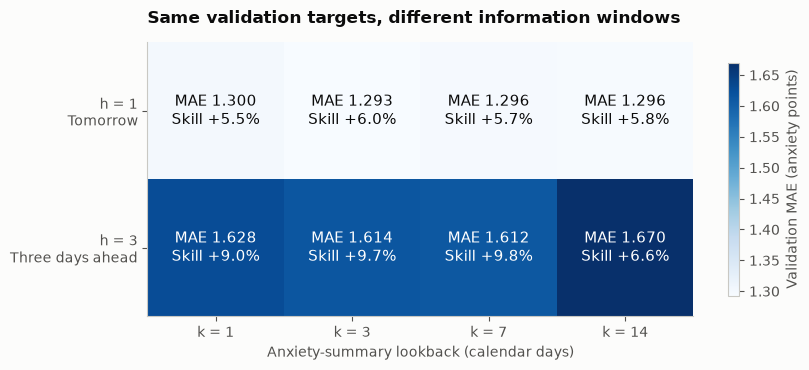

In [51]:
mae_grid = c4_results["MAE"].unstack("k").loc[[1, 3], [1, 3, 7, 14]]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
image_map = ax.imshow(mae_grid.to_numpy(), cmap="Blues", aspect="auto")
for row, h in enumerate(mae_grid.index):
    for column, k in enumerate(mae_grid.columns):
        mae = c4_results.loc[(h, k), "MAE"]
        skill = c4_results.loc[(h, k), "Skill vs persistence"]
        color = "white" if image_map.norm(mae) > 0.55 else INK
        ax.text(column, row, f"MAE {mae:.3f}\nSkill {skill:+.1%}", ha="center", va="center", fontsize=11, color=color)
ax.set_xticks(range(4), [f"k = {k}" for k in mae_grid.columns])
ax.set_yticks([0, 1], ["h = 1\nTomorrow", "h = 3\nThree days ahead"])
ax.set_xlabel("Anxiety-summary lookback (calendar days)")
ax.set_title("Same validation targets, different information windows", pad=14)
ax.grid(False)
fig.colorbar(image_map, ax=ax, label="Validation MAE (anxiety points)", shrink=0.85)
fig.tight_layout()
plt.show()

The controlled comparison uses **888 fitting targets, 17 January 2023–28 June 2025**, and the same **184 validation targets** for every configuration. The date audit confirms that even the three-day forecasts use only fitting labels available at their first issue time.

For **tomorrow**, $k=3$ has the lowest validation MAE, **1.2931**, compared with **1.2999, 1.2961 and 1.2959** for $k=1,7,14$. The difference between three and seven days is only about **0.003 anxiety points**. I would not call this compelling evidence that three days is a uniquely best window. All four improve on same-date persistence, whose MAE is **1.3750**.

At **three days ahead**, $k=7$ has the lowest MAE, **1.6121**, while the fourteen-day version is worse at **1.6695**. The horizon-matched persistence baseline has MAE **1.7880**, so the seven-day model has about **9.8% skill** relative to that harder baseline. Its absolute error is still larger than tomorrow's: a larger relative skill does not mean forecasting three days ahead is easier. The seven-day-mean baseline also changes with the issue date and has MAE **1.7345** at this horizon.

The main forecasting task remains $h=1$. I record $k=3$ as the lowest-scoring validation candidate and keep $k=7$ as the established reference for the next ablation. Keeping both roles explicit is more honest than declaring a strong window preference from a tiny difference or rewriting the earlier reference results. Alpha was retuned for each configuration; these scores compare complete learning procedures, not the isolated effect of adding one column at fixed weights.

### 11.3 Why predicting the same evening is a separate check

Predicting the same evening's rating from the same evening's recorded habits is a retrospective association task. It is not tomorrow's forecast, and I have not established that all entries were recorded before the rating. I therefore exclude **all anxiety-history columns**, including their missingness and coverage indicators. Otherwise today's rating would directly reveal its own target.

The following diagnostic uses lifestyle and calendar columns only, with the calendar recomputed for the actual same-day target. With no anxiety summaries, changing $k$ changes eligibility at the beginning but not the remaining feature values. I verify that equivalence on the common dates and score one representative configuration rather than print four identical models. Persistence at $h=0$ would copy the target itself, so I do not report that circular benchmark. Its skill is explicitly relative to the training mean.

In [52]:
same_day_tasks = {k: build_development_task(k, 0) for k in [1, 3, 7, 14]}
for k, task in same_day_tasks.items():
    pd.testing.assert_frame_equal(task["X"].loc[common_task_dates], same_day_tasks[14]["X"].loc[common_task_dates])
    assert not task["dictionary"]["domain"].eq("history").any()
same_day_task = same_day_tasks[14]
same_day_choice = tune_development_ridge(same_day_task["X"].loc[c4_training_dates],
                                         same_day_task["y"].loc[c4_training_dates], c4_folds)
same_day_model = make_experiment_pipeline(same_day_choice["alpha"], len(c4_training_dates)).fit(
    same_day_task["X"].loc[c4_training_dates], same_day_task["y"].loc[c4_training_dates])
same_day_prediction = same_day_model.predict(same_day_task["X"].loc[c4_validation_dates])
same_day_mean = np.full(len(c4_validation_dates), same_day_task["y"].loc[c4_training_dates].mean())
same_day_scores = regression_scores(same_day_task["y"].loc[c4_validation_dates], same_day_prediction, same_day_mean)
same_day_scores["Skill vs training mean"] = same_day_scores.pop("Skill vs persistence")
display(pd.DataFrame([same_day_scores], index=["h=0: retrospective lifestyle + calendar diagnostic"]).round(4))
print(f"Same-day inputs: {same_day_task['X'].shape[1]}; alpha: {same_day_choice['alpha']:g}. No anxiety-history inputs.")

,MAE,RMSE,R2,Skill vs training mean
h=0: retrospective lifestyle + calendar diagnostic,1.0637,1.3176,0.5713,0.415


Same-day inputs: 11; alpha: 0.1. No anxiety-history inputs.


The same-day lifestyle-and-calendar diagnostic has **11 inputs**, validation **MAE 1.0637**, **RMSE 1.3176** and **$R^2=0.5713$**. Its **41.5% skill is relative to the training mean**, not persistence. The check confirms that all four lookbacks produce identical input values on the common dates once anxiety-history columns are removed.

This supports the descriptive observation in Section 5 that same-evening habits move with anxiety. It does not establish causal effects or solve the forecasting question. Those measurements describe the same day as the outcome, and the timing of their recording does not establish that they were available before the anxiety rating. I will not carry this model into the tomorrow-forecast scorecard as a competing forecast.

### 11.4 What these results say about the lookback window

The central question stays **tomorrow's anxiety**, so I will not replace it with the same-day task or choose the forecast horizon simply because one score is lower. Within a horizon, a lower validation MAE is a useful development result, not proof of a uniquely best window.

The controlled window and horizon fits use fewer training targets than Section 9: their common starting date accommodates fourteen-day history at a three-day horizon, and their common end date respects the three-day issue-time cutoff. Their alpha search also extends to $10^4$ for strongly regularized candidates and includes the unregularized $\alpha=0$ limit, implemented with `LinearRegression` and the same preprocessing. This avoids treating a minimum at nearly zero as evidence for a precisely identified positive penalty. The scratch ridge class in Section 10 retains its positive-alpha contract. I should therefore compare configurations **within the window and horizon table**, rather than attribute any difference from Section 9 entirely to the window.

For the feature comparison below, I retain the original **$k=7,h=1$ reference**, fixed before this window comparison. This keeps the question “do habits add to recent anxiety?” separate from choosing a window after looking at validation. Any preferred lookback window remains a development candidate to carry forward; it does not retrospectively change Sections 9–10 or turn the ablation into an independent evaluation of a validation-selected window.

<a id="section-12"></a>

## 12. Do habits help once I include past anxiety?

This is the comparison closest to my original question. A full model beating persistence does not tell me whether habits helped: it also has more flexible anxiety-history summaries. I now compare feature groups directly, keeping the seven-day, one-day-ahead reference and the original 899-row training partition.

### 12.1 Removing one group of inputs at a time

Every candidate retains the known target-weekend flag as a common calendar control. “History” includes current anxiety, its rolling summaries and their missingness/coverage columns. “Lifestyle” includes sleep, exercise and socializing, with their related indicators. Removing sleep also removes both ratings, accumulated shortfall, current missingness flags and the missing-input recurrence. Otherwise the model could still receive the supposedly removed information indirectly through its engineered companions.

Each candidate gets its own training-fitted imputer, scaler and tuned alpha. Reusing the full model's weights or its alpha after removing inputs would not give the smaller model a fair chance to adapt.

### 12.2 Tuning each feature set within the training folds

If I tune alpha on five folds and report the minimum on those same folds as if the choice were fixed beforehand, the score benefits from selection. Here I use **nested expanding-window CV** entirely within training:

1. An outer fold holds out the next period, exactly as in Section 8.
2. Three inner expanding folds inside its fitting period select alpha for each feature set.
3. I refit that candidate on the outer fitting rows and forecast its outer held-out rows.
4. I pool the five outer blocks, giving one genuinely held-out prediction per scored target for each candidate.

Both inner and outer folds check that every fitting label is available by the next block's earliest issue evening. The 2025 validation block and 2026 final period are not used to tune or score the feature comparison.

For candidate $S$, write $\widehat\alpha_{f,S}$ for the alpha chosen inside outer fold $f$. The comparison estimates

$$\mathrm{MAE}_{S}=\frac1{745}\sum_{f=1}^{5}\sum_{i\in V_f}
\left|y_i-\widehat y_{i,S}^{\,(f,\widehat\alpha_{f,S})}\right|.$$

The mean and persistence baselines use exactly those outer dates; their fitting means and fallback rules are computed from the corresponding outer training rows. Nested CV protects the alpha selection within each reported fold. Comparing several feature sets can still create selection optimism if I choose the smallest reported outer score, so these remain development comparisons, not the final performance claim.

In [53]:
c1_dictionary = builder.feature_dictionary.loc[X_train.columns]
c1_domains = c1_dictionary["domain"]
c1_feature_sets = {
    "History + calendar": c1_domains.index[c1_domains.isin(["history", "calendar"])].tolist(),
    "Lifestyle + calendar": c1_domains.index[c1_domains.ne("history")].tolist(),
    "Full": X_train.columns.tolist(),
    "Full minus sleep": c1_domains.index[c1_domains.ne("sleep")].tolist(),
    "Full minus exercise": c1_domains.index[c1_domains.ne("exercise")].tolist(),
    "Full minus socializing": c1_domains.index[c1_domains.ne("socializing")].tolist(),
}
for name, columns in c1_feature_sets.items():
    assert "target_is_weekend" in columns
for domain in ["sleep", "exercise", "socializing"]:
    assert not c1_dictionary.loc[c1_feature_sets[f"Full minus {domain}"], "domain"].eq(domain).any()
display(pd.DataFrame({"Features": {name: len(columns) for name, columns in c1_feature_sets.items()},
                      "Columns": {name: ", ".join(columns) for name, columns in c1_feature_sets.items()}}))

c1_target_index = pd.DatetimeIndex(target_dates.loc[X_train.index], name="target_date")
c1_X = X_train.copy()
c1_X.index = c1_target_index
c1_y = pd.Series(y_train.to_numpy(), index=c1_target_index, name="Observed")
c1_outer_folds = available_date_splits(c1_target_index, horizon=1)
c1_oof = pd.DataFrame(np.nan, index=c1_target_index, columns=list(c1_feature_sets))
c1_baseline_oof = pd.DataFrame(np.nan, index=c1_target_index, columns=list(validation_baselines))
c1_choices = []
for fold_number, (fit, score) in enumerate(c1_outer_folds, 1):
    fit_dates, score_dates = c1_target_index[fit], c1_target_index[score]
    inner_folds = available_date_splits(fit_dates, horizon=1, n_splits=3)
    c1_baseline_oof.loc[score_dates] = horizon_baselines(c1_y.iloc[fit], score_dates, horizon=1)
    for name, columns in c1_feature_sets.items():
        choice = tune_development_ridge(c1_X.iloc[fit][columns], c1_y.iloc[fit], inner_folds)
        model = make_experiment_pipeline(choice["alpha"], len(fit)).fit(c1_X.iloc[fit][columns], c1_y.iloc[fit])
        prediction = model.predict(c1_X.iloc[score][columns])
        c1_oof.loc[score_dates, name] = prediction
        c1_choices.append({"Fold": fold_number, "Feature set": name, "Fit rows": len(fit),
                           "Validation rows": len(score), "alpha": choice["alpha"],
                           "Inner selected MAE": choice["mae"],
                           "Outer MAE": mean_absolute_error(c1_y.iloc[score], prediction)})
    print(f"Nested feature-comparison fold {fold_number}/5 complete ({len(fit)} fitting, {len(score)} held-out forecasts).", flush=True)

c1_common_dates = c1_oof.index[c1_oof.notna().all(axis=1)]
assert c1_common_dates.equals(pd.DatetimeIndex(target_dates.loc[common_cv_dates], name="target_date"))
assert len(c1_common_dates) == 745
c1_all_predictions = c1_baseline_oof.loc[c1_common_dates].join(c1_oof.loc[c1_common_dates])
c1_evaluator = ModelEvaluator(c1_y.loc[c1_common_dates], c1_all_predictions,
                              c1_baseline_oof.loc[c1_common_dates, "Persistence"])
c1_scores = c1_evaluator.metrics()
display(c1_scores.round(4))
c1_alpha_choices = pd.DataFrame(c1_choices).pivot(index="Fold", columns="Feature set", values="alpha")
display(c1_alpha_choices)
print("The outer scores evaluate the inner tuning procedure, not the minimum inner-CV errors.")

,Features,Columns
History + calendar,7,"anxiety_today, anxiety_missing_today, anxiety_..."
Lifestyle + calendar,11,"sleep_adequacy_today, sleep_adequacy_missing_t..."
Full,17,"anxiety_today, anxiety_missing_today, sleep_ad..."
Full minus sleep,11,"anxiety_today, anxiety_missing_today, exercise..."
Full minus exercise,15,"anxiety_today, anxiety_missing_today, sleep_ad..."
Full minus socializing,15,"anxiety_today, anxiety_missing_today, sleep_ad..."


Nested feature-comparison fold 1/5 complete (154 fitting, 149 held-out forecasts).


Nested feature-comparison fold 2/5 complete (303 fitting, 149 held-out forecasts).


Nested feature-comparison fold 3/5 complete (452 fitting, 149 held-out forecasts).


Nested feature-comparison fold 4/5 complete (601 fitting, 149 held-out forecasts).


Nested feature-comparison fold 5/5 complete (750 fitting, 149 held-out forecasts).


,MAE,RMSE,R2,Skill vs persistence
Training mean,1.6842,2.0779,-0.0276,-0.1104
Persistence,1.5168,1.9241,0.1189,0.0000
Seven-day mean,1.5785,1.9829,0.0642,-0.0407
History + calendar,1.3873,1.6981,0.3137,0.0853
Lifestyle + calendar,1.5405,1.9182,0.1243,-0.0156
Full,1.4134,1.7333,0.2850,0.0681
Full minus sleep,1.4059,1.7227,0.2937,0.0731
Full minus exercise,1.3995,1.7170,0.2984,0.0773
Full minus socializing,1.4112,1.7264,0.2906,0.0696


Feature set,Full,Full minus exercise,Full minus sleep,Full minus socializing,History + calendar,Lifestyle + calendar
Fold,,,,,,
1,1.000000,0.316228,0.316228,1.000000,0.100000,0.316228
2,0.031623,0.010000,0.010000,0.031623,0.000000,0.316228
3,0.031623,0.031623,0.000000,0.100000,0.000000,1.000000
4,0.003162,0.001000,0.001000,0.003162,0.010000,1.000000
5,0.010000,0.000000,0.100000,0.003162,0.031623,1.000000


The outer scores evaluate the inner tuning procedure, not the minimum inner-CV errors.


### 12.3 Comparing the changes in error

For each target date, the full and reduced models see the same forecasting problem. Let

$$d_i^{(S)}=|y_i-\widehat y_{i,S}|-|y_i-\widehat y_{i,\mathrm{full}}|,
\qquad \overline d^{(S)}=\mathrm{MAE}_{S}-\mathrm{MAE}_{\mathrm{full}}.$$

A positive difference means the full model has lower MAE; a negative difference means the reduced model does better. For “History + calendar,” this tests adding all lifestyle inputs together. For the single-domain removals, it tests that domain's additional value given the other inputs and the separate retuning.

The percentage of dates on which the full model has lower absolute error is descriptive, not a probability that a habit matters. Daily errors are dependent, and several small differences can be unstable. I do not attach independent-sample significance tests to these overlapping time-series folds.

,MAE reduced minus full,Dates full has smaller absolute error (%)
History + calendar,-0.0261,47.2483
Lifestyle + calendar,0.1270,55.4362
Full minus sleep,-0.0075,48.5906
Full minus exercise,-0.0139,48.9933
Full minus socializing,-0.0022,54.2282


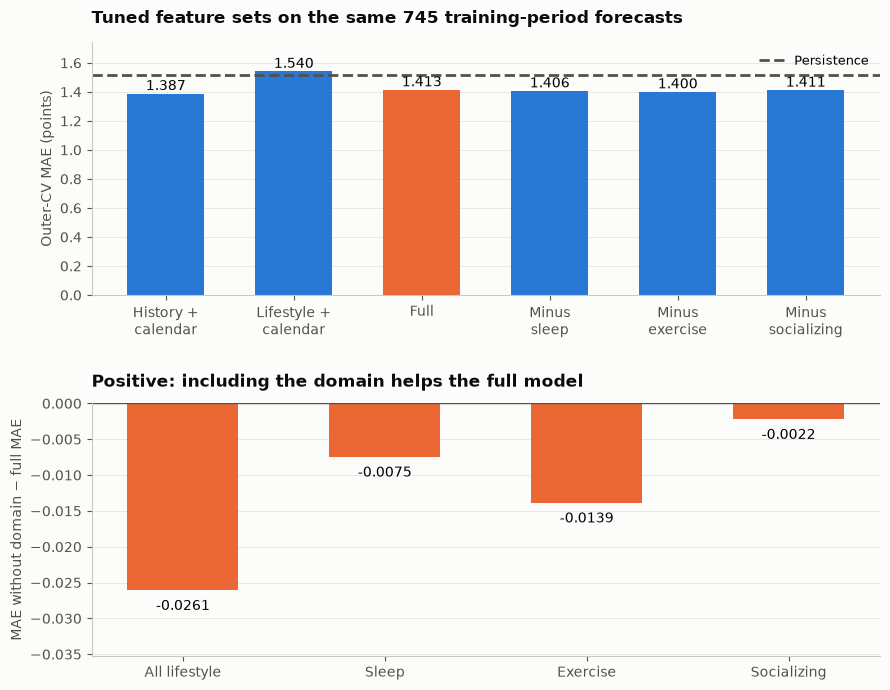

In [54]:
c1_actual = c1_y.loc[c1_common_dates]
c1_absolute_errors = c1_oof.loc[c1_common_dates].sub(c1_actual, axis=0).abs()
c1_paired = pd.DataFrame({
    "MAE reduced minus full": c1_absolute_errors.mean() - c1_absolute_errors["Full"].mean(),
    "Dates full has smaller absolute error (%)": c1_absolute_errors.gt(c1_absolute_errors["Full"], axis=0).mean() * 100,
})
display(c1_paired.drop(index="Full").round(4))
np.testing.assert_allclose(c1_paired["MAE reduced minus full"],
                           c1_scores.loc[c1_oof.columns, "MAE"] - c1_scores.loc["Full", "MAE"])

fig, axes = plt.subplots(2, 1, figsize=(9, 7.0))
short_names = ["History +\ncalendar", "Lifestyle +\ncalendar", "Full", "Minus\nsleep", "Minus\nexercise", "Minus\nsocializing"]
values = c1_scores.loc[list(c1_feature_sets), "MAE"]
axes[0].bar(range(6), values, color=[BLUE if name != "Full" else ORANGE for name in c1_feature_sets], width=0.6)
for position, value in enumerate(values):
    axes[0].text(position, value + 0.025, f"{value:.3f}", ha="center", fontsize=10)
axes[0].axhline(c1_scores.loc["Persistence", "MAE"], color=INK_2, linestyle="--", label="Persistence")
axes[0].set_xticks(range(6), short_names)
axes[0].set_ylim(0, max(values.max(), c1_scores.loc["Persistence", "MAE"]) + 0.2)
axes[0].set_ylabel("Outer-CV MAE (points)")
axes[0].set_title("Tuned feature sets on the same 745 training-period forecasts", pad=14)
axes[0].legend(fontsize=9)
removals = ["History + calendar", "Full minus sleep", "Full minus exercise", "Full minus socializing"]
gains = c1_paired.loc[removals, "MAE reduced minus full"]
axes[1].bar(range(4), gains, color=[BLUE if gain > 0 else ORANGE for gain in gains], width=0.55)
for position, value in enumerate(gains):
    axes[1].annotate(f"{value:+.4f}", (position, value), xytext=(0, 6 if value >= 0 else -14),
                     textcoords="offset points", ha="center", fontsize=10)
axes[1].axhline(0, color=INK_2, linewidth=1)
axes[1].set_xticks(range(4), ["All lifestyle", "Sleep", "Exercise", "Socializing"])
axes[1].set_ylabel("MAE without domain − full MAE")
axes[1].set_title("Positive: including the domain helps the full model", pad=12)
axes[1].margins(y=0.35)
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout(h_pad=2.5)
plt.show()

**For this ridge procedure, adding the habit features does not improve on the history-and-calendar model.** On the same **745 outer-CV forecasts**, history plus calendar has MAE **1.3873**, compared with **1.4134** for the full model. Both beat persistence's **1.5168**, with skill about **8.5%** and **6.8%** respectively. Lifestyle plus calendar alone has MAE **1.5405**, slightly worse than persistence.

This is why the earlier full-model improvement over persistence was not enough to answer my central question. A more flexible history model can already explain an improvement over that simple rule. Here the full model's additional lifestyle inputs increase MAE by about **0.0261 points** relative to history plus calendar. That is a small observed difference, not a significance claim or a conclusion that habits do not matter in my life.

The domain-removal results point in the same direction: removing sleep, exercise or socializing gives MAE **1.4059, 1.3995 and 1.4112**, respectively. Their reduced-minus-full differences are **−0.0075, −0.0139 and −0.0022**. A negative bar means the reduced model has lower MAE; none of these removals hurts average accuracy in this comparison. The candidates were retuned separately, so this measures each domain's incremental value to the learning procedure, not a fixed coefficient being set to zero.

The socializing example also shows why counting “winning days” can mislead. The full model has smaller absolute error on about **54.2%** of dates than the model without socializing, yet its mean absolute error is slightly higher. The sizes of the remaining misses outweigh that majority. MAE uses the size of every error rather than only which model won the day.

Alpha varies across outer folds because each is selected from a different earlier period. The **1.4134** nested score is not expected to equal Section 9's **1.39774** selected training-CV minimum: that earlier minimum used the same CV targets to choose alpha, whereas each outer prediction here uses an alpha selected without its scored targets. Neither training-CV number should be compared directly with the **1.2955** validation MAE from July–December 2025, because those are different dates.

My answer so far is specific: **these recorded lifestyle features have not added predictive value beyond recent anxiety and calendar for this seven-day, one-day-ahead ridge setup.** I have not tested every possible representation or nonlinear interaction, and I have not estimated causal effects. A different model or feature representation could give a different result; I have not tested that here.

### 12.4 What I can learn from removing inputs

This comparison asks whether these recorded habits, represented by these features, improve this ridge forecasting procedure beyond recent anxiety and a shared calendar flag. It does not test whether sleep, exercise or social contact causally affect my wellbeing. An unhelpful predictive feature could still describe something important in my life; its effect could be nonlinear, delayed differently, obscured by measurement noise or already reflected in current anxiety.

Dropping a correlated domain also lets the remaining coefficients change. A small removal effect is not proof that the domain has no information, and a coefficient's sign from Section 10 is not a substitute for this out-of-fold comparison. Nested alpha tuning makes the scorecard fairer, but it does not remove distribution change or turn the 745 dependent days into independent experiments.

For my journal, the main finding is that these habit features did not improve this ridge model beyond recent anxiety and calendar information in the comparisons above. That does not tell me whether changing my habits would change my anxiety. A useful next step would be to fix the modelling choices and evaluate them on newly recorded days.